# Entregable 1 · Detección de intrusiones en redes de drones con datos tabulares

**Estado del arte, análisis exploratorio e implementación de los tres modelos base de la literatura**

| | |
|---|---|
| **Autor** | Donny Torres |
| **Programa** | Maestría en Analítica de Datos, Universidad del Norte (Barranquilla) |
| **Asignatura** | Deep Learning |
| **Fecha** | Noviembre de 2026 |
| **Conjunto de datos** | *UAVIDS-2025*, versión 1 (`UAVIDS-2025.csv`) |
| **Fuente** | Kaggle: <https://www.kaggle.com/datasets/qinglizeng1997/uavids-2025>; Zenodo, licencia CC BY 4.0, DOI <https://doi.org/10.5281/zenodo.15336998> |
| **Tipo de problema** | Clasificación con datos tabulares, multiclase de cinco categorías |
| **Repositorio** | <https://github.com/DTL-DA/proyecto-final-dl-uavids-2025> |
| **Jupyter Book** | Pendiente de publicación |
| **Dashboard** | Pendiente de publicación |

Este cuaderno desarrolla el primer entregable del proyecto final de Deep Learning. El propósito es establecer, con evidencia estadística, el nivel mínimo de desempeño (*baseline*) que cualquier modelo avanzado deberá superar al detectar intrusiones en redes de enjambres de drones, de modo que una mejora futura se pueda juzgar por su relevancia y no solo por un promedio más alto. Primero se define el problema, luego se audita el conjunto de datos, se extraen de la literatura los tres modelos de Deep Learning más básicos y se implementan bajo un mismo protocolo, para cerrar con el baseline y su inferencia estadística.

## Configuración del entorno

El cuaderno se ejecuta de principio a fin en CPU, porque el conjunto de datos es tabular y pesa unos 20 MB. Se apoya en tres reglas:

- **Los datos se obtienen con un solo paso.** Si el archivo no está en la carpeta del proyecto, se descarga de Kaggle, y en cualquier caso se verifica su suma SHA-256.
- **Cada corrida se guarda al terminar.** Si la ejecución se interrumpe, se vuelve a ejecutar y se salta lo que ya está hecho.
- **Las semillas y la configuración quedan registradas**, junto con las versiones de las librerías, para que cada resultado se pueda reproducir.

In [1]:
import warnings
import hashlib
import json
import os
import random
import subprocess
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = Path("Entregable_1_UAVIDS_2025")
CARPETA_DATOS = RAIZ / "datos"
RESULTADOS = RAIZ / "resultados"
CSV = CARPETA_DATOS / "UAVIDS-2025.csv"
SHA_ESPERADO = "d50d339f68be7b23f0bf089dd438b20a1835c13182d8641220538121440164d0"
URL = "https://www.kaggle.com/api/v1/datasets/download/qinglizeng1997/uavids-2025"

CARPETA_DATOS.mkdir(parents=True, exist_ok=True)
RESULTADOS.mkdir(parents=True, exist_ok=True)
if not CSV.exists():
    comprimido = CARPETA_DATOS / "archive.zip"
    subprocess.run(["curl", "-L", "-sS", "-o", str(comprimido), URL], check=True)
    with zipfile.ZipFile(comprimido) as z:
        z.extract("UAVIDS-2025.csv", CARPETA_DATOS)
    comprimido.unlink()
sha = hashlib.sha256(CSV.read_bytes()).hexdigest()
assert sha == SHA_ESPERADO, "El SHA-256 no coincide: la copia está dañada o cambió de versión"
datos = pd.read_csv(CSV)
print("SHA-256:", sha)
print("Forma del archivo:", datos.shape)

SHA-256: d50d339f68be7b23f0bf089dd438b20a1835c13182d8641220538121440164d0
Forma del archivo: (122171, 23)


In [2]:
import platform
from importlib.metadata import version

import matplotlib as mpl
import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_predict, train_test_split
from statsmodels.stats.multitest import multipletests

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

IDENTIFICADORES = ["FlowID", "SrcAddr", "SrcPort", "DstAddr", "DstPort", "Protocol"]
ATRIBUTOS = ["FlowDuration/s", "TxPackets", "RxPackets", "LostPackets", "TxBytes", "RxBytes", "TxPacketRate/s", "RxPacketRate/s", "TxByteRate/s",
             "RxByteRate/s", "MeanDelay/s", "MeanJitter/s", "Throughput/Kbps", "MeanPacketSize", "PacketDropRate", "AverageHopCount"]
nombre_clase = datos["label"].str.replace(" Attack", "").str.replace(" Traffic", "")
CLASES = sorted(nombre_clase.unique())
K = len(CLASES)
N = len(datos)
y = nombre_clase.map({c: i for i, c in enumerate(CLASES)}).to_numpy()
x_crudo = datos[ATRIBUTOS].to_numpy(dtype=np.float64)


def num(valor, decimales=3):
    '''Da formato al número para el texto: coma decimal y espacio de miles.'''
    return f"{valor:,.{decimales}f}".replace(",", " ").replace(".", ",")


def enumerar(elementos):
    '''Une una lista para el texto: «a, b y c».'''
    elementos = list(elementos)
    return ", ".join(elementos[:-1]) + " y " + elementos[-1] if len(elementos) > 1 else "".join(elementos)


def valor_p(p):
    return "p < 0,001" if p < 0.001 else f"p = {num(p, 3)}"


def interpretar(texto):
    display(Markdown(texto))


def cramer(tabla):
    '''V de Cramér: tamaño de efecto de una tabla de contingencia, entre 0 y 1.'''
    chi2 = stats.chi2_contingency(tabla)[0]
    return float(np.sqrt(chi2 / (tabla.sum() * (min(tabla.shape) - 1))))


# Las gráficas van en escala de grises: las series se distinguen por tono, tipo de línea y marcador
NEGRO, GRIS_OSCURO, GRIS_MEDIO, GRIS_CLARO = "#000000", "#4a4a4a", "#7a7a7a", "#d9d9d9"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "image.cmap": "Greys", "axes.grid": True, "grid.color": GRIS_CLARO,
                     "axes.edgecolor": GRIS_MEDIO, "axes.prop_cycle": mpl.cycler(color=[NEGRO, GRIS_OSCURO, GRIS_MEDIO]),
                     "axes.titlesize": 10.5, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8})

PAQUETES = ["torch", "numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "matplotlib"]
display(pd.DataFrame({"Componente": ["Python", *PAQUETES, "Dispositivo"],
                      "Versión": [platform.python_version(), *map(version, PAQUETES), f"CPU, {torch.get_num_threads()} hilos"]}).style.hide(axis="index"))

Componente,Versión
Python,3.13.14
torch,2.6.0+cpu
numpy,2.4.6
pandas,3.0.3
scipy,1.17.1
scikit-learn,1.9.0
statsmodels,0.15.0
matplotlib,3.10.9
Dispositivo,"CPU, 10 hilos"


## 1. Definición del problema y dataset

En esta sección se formaliza el problema en notación matemática, se declaran por anticipado la métrica, el margen de relevancia y la unidad de independencia, y se justifica y describe técnicamente el conjunto de datos. Esto es primordial porque estas decisiones condicionan todo lo que sigue y se heredan en los Entregables 2 y 3.

### 1.1 Definición formal del problema

El sistema recibe los atributos de un flujo de red dentro de un enjambre de drones y debe indicar si es tráfico normal o a qué ataque pertenece. Formalmente:

- **Espacio de entrada:** $\mathcal{X} = \mathbb{R}^{d}$, el vector de atributos de tráfico y desempeño de un flujo, con $d$ fijado en el análisis exploratorio.
- **Espacio de salida:** $\mathcal{Y}$ = {Blackhole, Flooding, Normal, Sybil, Wormhole}.
- **Función objetivo:** $f : \mathcal{X} \to \mathcal{Y}$, aproximada por $f_\theta(x) = \arg\max_{c \in \mathcal{Y}} p_\theta(c \mid x)$.
- **Función de pérdida:** entropía cruzada, $\mathcal{L}(\theta) = -\frac{1}{n}\sum_{i=1}^{n} w_{y_i} \log p_\theta(y_i \mid x_i)$, con los pesos $w_c$ definidos en el análisis exploratorio.

**Tipo de problema.** El proyecto corresponde al tipo 1 del enunciado, clasificación con datos tabulares, en su versión multiclase. Se opta por las cinco categorías y no por la versión binaria de normal frente a ataque, porque reconocer el tipo de ataque responde una pregunta más exigente y de ella se puede derivar la binaria, mientras que lo contrario no es posible.

**Pregunta de investigación.** ¿Qué nivel de desempeño, medido con F1 macro, establecen los tres modelos de Deep Learning más básicos de la literatura al clasificar los flujos de un enjambre de drones en tráfico normal y cuatro ataques, cuando la partición respeta la estructura de dependencia del archivo, y qué mejora debe superar un modelo avanzado para considerarse relevante?

**Hipótesis operativa.** Al menos un par de modelos base difiere en F1 macro en una magnitud igual o mayor que el margen de relevancia práctica δ.

**Declaración a priori.** Las decisiones siguientes se fijan antes de ver resultados de cualquier modelo de Deep Learning, para evitar la exploración selectiva. La métrica primaria es el F1 macro, $F1_{macro} = \frac{1}{K}\sum_{c=1}^{K} \frac{2 P_c R_c}{P_c + R_c}$, que promedia sin ponderar las $K = 5$ clases, porque en seguridad un ataque poco frecuente importa tanto como uno frecuente. El margen δ = 0,01 tiene una lectura directa: por la definición del promedio macro, equivale a que el F1 de una sola clase cambie 0,05 mientras las demás permanecen iguales, y se contrasta con la variabilidad medida en el piloto de la sección 4.3.1. La unidad de independencia es la serie, una de las que propone el enunciado, porque los flujos consecutivos según `FlowID` son muy parecidos entre sí, de modo que la dependencia sigue a la posición en el archivo y no a una entidad como el cliente, como se demuestra en la sección 2.1.3. Como el archivo no identifica la simulación de origen, cada serie se aproxima con bloques de 1000 flujos contiguos. Esto no convierte el proyecto en uno de series de tiempo: el archivo no trae marca de tiempo, de modo que no se afirma que ese orden sea cronológico, y ningún modelo usa rezagos como entrada, así que sigue siendo clasificación tabular. La partición se congeló el 3 de noviembre de 2026, antes de entrenar. El 4 de noviembre, con los resultados ya calculados, solo se alineó el nombre de la unidad con la lista del enunciado, sin cambiar la partición ni ninguna corrida.

In [3]:
DECISIONES = {
    "estado": "confirmada por el autor el 3 de noviembre de 2026; el nombre de la unidad se alineó con el enunciado el 4 de noviembre de 2026, sin cambiar la partición",
    "tipo_problema": "1. Clasificación con datos tabulares, multiclase de cinco categorías",
    "metrica_primaria": "F1 macro en el conjunto de prueba",
    "metricas_secundarias": ["accuracy", "balanced accuracy", "precision, recall y F1 (macro, ponderado y por clase)", "AUC-ROC macro", "AUC-PR macro", "MCC", "ECE"],
    "margen_delta": 0.01,
    "alfa": 0.05,
    "unidad_independencia": "serie: flujos consecutivos según FlowID, aproximada con bloques de 1000 flujos contiguos",
    "particion": {"entrenamiento": 0.64, "validacion": 0.16, "prueba": 0.20, "semilla": SEMILLA, "estrategia": "estratificada por clase y agrupada por bloques"},
}
(RESULTADOS / "declaracion_a_priori.json").write_text(json.dumps(DECISIONES, ensure_ascii=False, indent=1), encoding="utf-8")
display(pd.DataFrame({"Decisión": ["Estado", "Métrica primaria", "Métricas secundarias", "Margen δ", "Nivel α", "Unidad de independencia", "Partición"],
                      "Valor": [DECISIONES["estado"], DECISIONES["metrica_primaria"], ", ".join(DECISIONES["metricas_secundarias"]), DECISIONES["margen_delta"], DECISIONES["alfa"],
                                DECISIONES["unidad_independencia"], "64 / 16 / 20, estratificada por clase y agrupada por bloques, semilla 42"]}).style.hide(axis="index"))

Decisión,Valor
Estado,"confirmada por el autor el 3 de noviembre de 2026; el nombre de la unidad se alineó con el enunciado el 4 de noviembre de 2026, sin cambiar la partición"
Métrica primaria,F1 macro en el conjunto de prueba
Métricas secundarias,"accuracy, balanced accuracy, precision, recall y F1 (macro, ponderado y por clase), AUC-ROC macro, AUC-PR macro, MCC, ECE"
Margen δ,0.010000
Nivel α,0.050000
Unidad de independencia,"serie: flujos consecutivos según FlowID, aproximada con bloques de 1000 flujos contiguos"
Partición,"64 / 16 / 20, estratificada por clase y agrupada por bloques, semilla 42"


### 1.2 Justificación del dataset

Los enjambres de drones se comunican por enlaces inalámbricos y enrutan el tráfico entre ellos mismos, sin una infraestructura fija, de modo que un nodo malicioso puede interrumpir la misión desde adentro. Detectar esa intrusión a partir del tráfico es primordial porque no exige modificar el protocolo de los drones. Los cuatro ataques del conjunto de datos representan esa amenaza: en Blackhole, un nodo atrae rutas y descarta los paquetes; en Flooding, satura la red; en Sybil, se presenta con varias identidades, y en Wormhole, dos nodos crean un túnel que altera las rutas.

El conjunto es público, en Kaggle, Zenodo (licencia CC BY 4.0) e IEEE DataPort (DOI 10.21227/j5p4-zt27). Según sus autores, los flujos se generaron por simulación en NS-3.24, con movilidad de enjambre basada en un algoritmo BOID extendido, IEEE 802.11ac, enrutamiento AODV, tráfico UDP y canal Nakagami, con un alcance de transmisión de 100 m y 20 dBm de potencia (Zeng et al., 2025). Es decir, son datos simulados y no capturas de drones reales, lo que limita su validez externa.

Hay referencias directas para comparar el baseline. El repositorio de los autores reporta, con partición aleatoria estratificada de 80 y 20 %, un F1 de 82 % con regresión logística, 93 % con DNN, 93 % con CNN, 94 % con LSTM y 96 % con XGBoost (Zeng et al., 2025). Zarkadis y Douligeris (2026) reportan un F1 de prueba de 90,66 % con MLP y de 94,28 % con RealMLP.

### 1.3 Descripción técnica

Cada fila es un flujo de red, con 22 atributos y la etiqueta. Los autores los agrupan así:

| Grupo | Atributos | Uso en los modelos |
|---|---|---|
| Conexión | `FlowID`, `SrcAddr`, `SrcPort`, `DstAddr`, `DstPort`, `Protocol` | Se excluyen, por las razones que se miden en la sección 2.1.4 |
| Volumen de tráfico | `FlowDuration/s`, `TxPackets`, `RxPackets`, `LostPackets`, `TxBytes`, `RxBytes`, `TxPacketRate/s`, `RxPacketRate/s`, `TxByteRate/s`, `RxByteRate/s`, `MeanPacketSize` | Entrada |
| Desempeño | `MeanDelay/s`, `MeanJitter/s`, `Throughput/Kbps`, `PacketDropRate`, `AverageHopCount` | Entrada |

La etiqueta no proviene de anotadores. Las fuentes públicas consultadas no explican cómo se asignó, y la continuidad de las etiquetas en el archivo sugiere que corresponde al escenario simulado. Por tal motivo, puede haber flujos sin relación con el ataque que reciben la etiqueta de su escenario, un ruido de etiqueta que se examina en la sección 2.1.2. En cuanto a la estructura de dependencia, los flujos de una misma simulación comparten nodos, tiempos y condiciones, y el archivo no identifica esa simulación, de modo que la dependencia se audita de forma indirecta en la sección 2.1.3.

In [4]:
tipos = datos.dtypes.astype(str).value_counts().to_dict()
display(pd.DataFrame({"Propiedad": ["Filas", "Columnas", "Tamaño del archivo (MB)", "Tipos de columna", "Versión", "SHA-256"],
                      "Valor": [N, datos.shape[1], round(CSV.stat().st_size / 1e6, 1), str(tipos), "Kaggle y Zenodo, v1", sha]}).style.hide(axis="index"))
interpretar(f'''**Interpretación.** El archivo tiene {num(N, 0)} flujos y {datos.shape[1]} columnas, y pesa {num(CSV.stat().st_size / 1e6, 1)} MB, de modo que cabe completo en la memoria y se puede entrenar en CPU. La suma SHA-256 de la tabla identifica esta versión, y el cuaderno se detiene si el archivo cambia.

Esto significa que el tamaño no impone ninguna restricción sobre el diseño, y que las repeticiones del estudio se pueden definir por criterios estadísticos y no por el costo de cómputo.

Por lo anterior, se trabaja con el archivo completo, sin muestreo, salvo en los diagnósticos donde se indique.''')

Propiedad,Valor
Filas,122171
Columnas,23
Tamaño del archivo (MB),20.100000
Tipos de columna,"{'float64': 10, 'int64': 9, 'str': 4}"
Versión,"Kaggle y Zenodo, v1"
SHA-256,d50d339f68be7b23f0bf089dd438b20a1835c13182d8641220538121440164d0


**Interpretación.** El archivo tiene 122 171 flujos y 23 columnas, y pesa 20,1 MB, de modo que cabe completo en la memoria y se puede entrenar en CPU. La suma SHA-256 de la tabla identifica esta versión, y el cuaderno se detiene si el archivo cambia.

Esto significa que el tamaño no impone ninguna restricción sobre el diseño, y que las repeticiones del estudio se pueden definir por criterios estadísticos y no por el costo de cómputo.

Por lo anterior, se trabaja con el archivo completo, sin muestreo, salvo en los diagnósticos donde se indique.

## 2. Análisis exploratorio de datos

En esta sección se audita el conjunto de datos para tomar decisiones de modelado. Cada análisis cierra con la decisión de preprocesamiento que deriva, el impacto en la arquitectura y los riesgos, incluidas las posibles fuentes de fuga de datos. El conjunto de prueba se define en la sección 2.1.3, se congela con su suma SHA-256 y, desde ese punto, no se usa su etiqueta ni para diseñar el preprocesamiento ni para ajustar hiperparámetros.

### 2.1 EDA general

#### 2.1.1 Variable objetivo

Se cuantifica el desbalance con la razón entre la clase mayoritaria y la minoritaria, y con la entropía de la distribución, $H = -\sum_c p_c \log_2 p_c$.

Clase,Flujos,%
Blackhole,26110,21.37
Flooding,19726,16.15
Normal,26172,21.42
Sybil,24077,19.71
Wormhole,26086,21.35


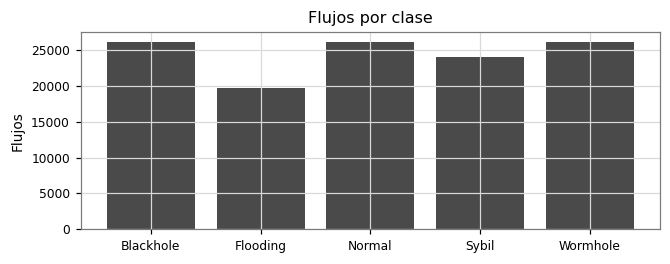

**Interpretación.** Normal es la clase mayoritaria, con 21,4 %, y Flooding la minoritaria, con 16,1 %, para una razón de 1,33 a 1. La entropía es de 2,314 bits frente a un máximo de $\log_2 5$ = 2,322 bits, es decir, el 99,7 % de la incertidumbre de un reparto uniforme.

Esto significa que no hay clases raras y que el desbalance es leve. Un clasificador trivial que responda siempre la clase mayoritaria tendría un F1 macro de 0,071, porque su F1 es cero en las otras cuatro clases, y ese es el piso real de comparación.

Por tal motivo, se conservan todas las clases, sin remuestrear, y se pondera la entropía cruzada, con pesos que se calculan después de eliminar las filas repetidas, porque esa limpieza cambia las proporciones, como muestra la sección 2.1.2.

**Decisión de preprocesamiento.** No se elimina ni se duplica ninguna muestra por desbalance; los pesos de clase se calculan solo con entrenamiento en la sección 2.2.5.

**Impacto en la arquitectura.** La capa de salida tiene 5 neuronas con entropía cruzada ponderada, y la selección de modelos se hace con F1 macro.

**Riesgos.** La proporción de clases es una decisión de quien construyó el archivo, no una frecuencia real de ataques. Por ello, las métricas no anticipan el desempeño en una red donde los ataques sean raros.

In [5]:
conteo = np.bincount(y, minlength=K)
p = conteo / conteo.sum()
razon = conteo.max() / conteo.min()
entropia = float(-(p * np.log2(p)).sum())
display(pd.DataFrame({"Clase": CLASES, "Flujos": conteo, "%": 100 * p}).style.hide(axis="index").format({"%": "{:.2f}"}))
fig, eje = plt.subplots(figsize=(6.2, 2.5))
eje.bar(CLASES, conteo, color=GRIS_OSCURO)
eje.set(ylabel="Flujos", title="Flujos por clase")
plt.tight_layout()
plt.show()
f1_trivial = (2 * p.max() / (1 + p.max())) / K
interpretar(f'''**Interpretación.** {CLASES[int(conteo.argmax())]} es la clase mayoritaria, con {num(100 * p.max(), 1)} %, y {CLASES[int(conteo.argmin())]} la minoritaria, con {num(100 * p.min(), 1)} %, para una razón de {num(razon, 2)} a 1. La entropía es de {num(entropia, 3)} bits frente a un máximo de $\\log_2 {K}$ = {num(np.log2(K), 3)} bits, es decir, el {num(100 * entropia / np.log2(K), 1)} % de la incertidumbre de un reparto uniforme.

Esto significa que no hay clases raras y que el desbalance es leve. Un clasificador trivial que responda siempre la clase mayoritaria tendría un F1 macro de {num(f1_trivial, 3)}, porque su F1 es cero en las otras cuatro clases, y ese es el piso real de comparación.

Por tal motivo, se conservan todas las clases, sin remuestrear, y se pondera la entropía cruzada, con pesos que se calculan después de eliminar las filas repetidas, porque esa limpieza cambia las proporciones, como muestra la sección 2.1.2.

**Decisión de preprocesamiento.** No se elimina ni se duplica ninguna muestra por desbalance; los pesos de clase se calculan solo con entrenamiento en la sección 2.2.5.

**Impacto en la arquitectura.** La capa de salida tiene {K} neuronas con entropía cruzada ponderada, y la selección de modelos se hace con F1 macro.

**Riesgos.** La proporción de clases es una decisión de quien construyó el archivo, no una frecuencia real de ataques. Por ello, las métricas no anticipan el desempeño en una red donde los ataques sean raros.''')

#### 2.1.2 Calidad del dataset

Se buscan valores faltantes, explícitos o disfrazados, datos fuera de rango físico, inconsistencias entre atributos y duplicados. Los casi duplicados se buscan redondeando el logaritmo de cada atributo a dos decimales, lo que equivale a una diferencia de cerca de 1 %, y el ruido de etiquetas se estima con los grupos de flujos idénticos o casi idénticos que tienen clases distintas.

In [6]:
nulos = int(datos.isna().sum().sum())
no_finitos = int((~np.isfinite(x_crudo)).sum())
negativos = int((x_crudo < 0).sum())
constantes = [c for c in datos.columns if datos[c].nunique() == 1]
rx_mayor = int((datos["RxPackets"] > datos["TxPackets"]).sum())
perdidos_distintos = int((datos["LostPackets"] != datos["TxPackets"] - datos["RxPackets"]).sum())
tasa_fuera = int((datos["PacketDropRate"] > 1).sum())
sin_recepcion = (datos["RxPackets"] == 0).to_numpy()
retardo_nulo = int(((datos["MeanDelay/s"] == 0) & sin_recepcion).sum())
tabla_rx = pd.crosstab(nombre_clase, sin_recepcion).reindex(CLASES)
chi_rx = stats.chi2_contingency(tabla_rx.to_numpy())
v_rx = cramer(tabla_rx.to_numpy())
display(pd.DataFrame({"Revisión": ["Valores nulos", "Valores no finitos", "Valores negativos", "Columnas constantes", "RxPackets mayor que TxPackets", "LostPackets distinto de TxPackets - RxPackets", "PacketDropRate mayor que 1", "Flujos sin ningún paquete recibido", "De ellos, con retardo igual a 0"],
                      "Resultado": [nulos, no_finitos, negativos, ", ".join(constantes) or "ninguna", rx_mayor, perdidos_distintos, tasa_fuera, int(sin_recepcion.sum()), retardo_nulo]}).style.hide(axis="index"))
display((100 * tabla_rx[True] / tabla_rx.sum(axis=1)).round(2).rename("% de flujos sin recepción").to_frame().T)

repetidas = datos[ATRIBUTOS + ["label"]].duplicated()
sin_flowid = datos.drop(columns="FlowID").duplicated()
repetidas_clase = pd.DataFrame({"Clase": CLASES, "Flujos": conteo, "Filas repetidas": np.bincount(y[repetidas.to_numpy()], minlength=K)})
repetidas_clase["% de la clase"] = 100 * repetidas_clase["Filas repetidas"] / repetidas_clase["Flujos"]
repetidas_clase["% del archivo sin repetidas"] = 100 * (repetidas_clase["Flujos"] - repetidas_clase["Filas repetidas"]) / (N - repetidas.sum())
display(repetidas_clase.style.hide(axis="index").format({"% de la clase": "{:.1f}", "% del archivo sin repetidas": "{:.1f}"}))
exactas_trafico = datos[ATRIBUTOS].duplicated(keep=False)
conflictos_exactos = int((datos[exactas_trafico].groupby(ATRIBUTOS)["label"].nunique() > 1).sum())
casi = pd.DataFrame(np.round(np.log1p(x_crudo), 2))
huella = pd.util.hash_pandas_object(casi, index=False)
grupos_casi = pd.DataFrame({"huella": huella.to_numpy(), "clase": y})
resumen_casi = grupos_casi.groupby("huella")["clase"].agg(["size", "nunique"])
en_grupo_casi = resumen_casi.loc[resumen_casi["size"] > 1]
conflictos_casi = int((en_grupo_casi["nunique"] > 1).sum())
filas_conflicto = int(en_grupo_casi.loc[en_grupo_casi["nunique"] > 1, "size"].sum())
display(pd.DataFrame({"Revisión": ["Filas repetidas sin contar FlowID", "Filas repetidas en los atributos de tráfico, con la misma etiqueta", "Grupos idénticos en tráfico con más de una clase", "Filas en grupos de casi duplicados", "Grupos de casi duplicados", "Grupos de casi duplicados con más de una clase", "Filas en esos grupos"],
                      "Resultado": [int(sin_flowid.sum()), int(repetidas.sum()), conflictos_exactos, int(en_grupo_casi["size"].sum()), len(en_grupo_casi), conflictos_casi, filas_conflicto]}).style.hide(axis="index"))

Revisión,Resultado
Valores nulos,0
Valores no finitos,0
Valores negativos,0
Columnas constantes,Protocol
RxPackets mayor que TxPackets,0
LostPackets distinto de TxPackets - RxPackets,24554
PacketDropRate mayor que 1,81
Flujos sin ningún paquete recibido,30
"De ellos, con retardo igual a 0",30


label,Blackhole,Flooding,Normal,Sybil,Wormhole
% de flujos sin recepción,0.0,0.15,0.0,0.0,0.0


Clase,Flujos,Filas repetidas,% de la clase,% del archivo sin repetidas
Blackhole,26110,0,0.0,22.9
Flooding,19726,7950,40.3,10.3
Normal,26172,0,0.0,23.0
Sybil,24077,269,1.1,20.9
Wormhole,26086,0,0.0,22.9


Revisión,Resultado
Filas repetidas sin contar FlowID,8205
"Filas repetidas en los atributos de tráfico, con la misma etiqueta",8219
Grupos idénticos en tráfico con más de una clase,0
Filas en grupos de casi duplicados,33025
Grupos de casi duplicados,7932
Grupos de casi duplicados con más de una clase,187
Filas en esos grupos,547


In [7]:
clase_mas_rx = tabla_rx[True].div(tabla_rx.sum(axis=1)).idxmax()
pct_rx = 100 * sin_recepcion.mean()
fila_rep = repetidas_clase.loc[repetidas_clase["% de la clase"].idxmax()]
interpretar(f'''**Interpretación.** El archivo no tiene valores nulos ni no finitos, y ningún atributo es negativo, así que no hay faltantes explícitos. Sin embargo, {num(sin_recepcion.sum(), 0)} flujos, el {num(pct_rx, 2)} %, no recibieron ningún paquete, y en los {num(retardo_nulo, 0)} el retardo aparece como 0. Ese cero no es un retardo nulo, sino un valor no observado, es decir, un faltante disfrazado. Su mecanismo no es MCAR, porque todos están en {clase_mas_rx} (V de Cramér = {num(v_rx, 3)}, {valor_p(chi_rx[1])}), y corresponde a MNAR, ya que el retardo falta justamente porque ningún paquete llegó. Aun así, son tan pocos que su efecto es despreciable.

En cuanto a la consistencia, {num(tasa_fuera, 0)} flujos tienen una tasa de pérdida mayor que 1, imposible por definición, y en {num(perdidos_distintos, 0)} flujos los paquetes perdidos no coinciden con la diferencia entre enviados y recibidos, lo que indica que el simulador los contabiliza con otro criterio. Así mismo, al ignorar `FlowID` aparecen {num(repetidas.sum(), 0)} filas repetidas en los atributos de tráfico, todas con la misma etiqueta, concentradas en {fila_rep["Clase"]}, donde son el {num(fila_rep["% de la clase"], 1)} % de la clase. Es decir, al eliminarlas, esa clase pasa de {num(100 * p[CLASES.index(fila_rep["Clase"])], 1)} % a {num(fila_rep["% del archivo sin repetidas"], 1)} % del archivo. Además, hay {num(len(en_grupo_casi), 0)} grupos de casi duplicados, de los cuales {num(conflictos_casi, 0)} mezclan clases.

Hay que tener en cuenta que esos {num(conflictos_casi, 0)} grupos reúnen {num(filas_conflicto, 0)} filas, el {num(100 * filas_conflicto / N, 1)} % del archivo, y que se toman como una cota del ruido de etiquetas: son flujos casi iguales con distinta etiqueta, lo que apunta a tráfico sin relación con el ataque que recibe la etiqueta de su escenario. Esto significa que el F1 macro no puede llegar a 1 aunque el modelo sea perfecto.

**Decisión de preprocesamiento.** Se eliminan las filas repetidas antes de partir, se recorta `PacketDropRate` a 1 y se conserva el cero del retardo, porque la falta de recepción se expresa también en `RxPackets`. Los casi duplicados se conservan, porque son flujos cortos y parecidos, propios del tráfico, y su efecto sobre la partición se mide en la sección 2.1.3.

**Impacto en la arquitectura.** Ninguno en la estructura. La reducción de {fila_rep["Clase"]} sí aumenta su peso en la pérdida, como se calcula en la sección 2.2.5.

**Riesgos.** Una fila repetida en entrenamiento y en prueba sería fuga directa, y por eso se elimina. El ruido de etiquetas no se puede corregir, porque el archivo no permite saber qué flujos participan en el ataque.''')

**Interpretación.** El archivo no tiene valores nulos ni no finitos, y ningún atributo es negativo, así que no hay faltantes explícitos. Sin embargo, 30 flujos, el 0,02 %, no recibieron ningún paquete, y en los 30 el retardo aparece como 0. Ese cero no es un retardo nulo, sino un valor no observado, es decir, un faltante disfrazado. Su mecanismo no es MCAR, porque todos están en Flooding (V de Cramér = 0,036, p < 0,001), y corresponde a MNAR, ya que el retardo falta justamente porque ningún paquete llegó. Aun así, son tan pocos que su efecto es despreciable.

En cuanto a la consistencia, 81 flujos tienen una tasa de pérdida mayor que 1, imposible por definición, y en 24 554 flujos los paquetes perdidos no coinciden con la diferencia entre enviados y recibidos, lo que indica que el simulador los contabiliza con otro criterio. Así mismo, al ignorar `FlowID` aparecen 8 219 filas repetidas en los atributos de tráfico, todas con la misma etiqueta, concentradas en Flooding, donde son el 40,3 % de la clase. Es decir, al eliminarlas, esa clase pasa de 16,1 % a 10,3 % del archivo. Además, hay 7 932 grupos de casi duplicados, de los cuales 187 mezclan clases.

Hay que tener en cuenta que esos 187 grupos reúnen 547 filas, el 0,4 % del archivo, y que se toman como una cota del ruido de etiquetas: son flujos casi iguales con distinta etiqueta, lo que apunta a tráfico sin relación con el ataque que recibe la etiqueta de su escenario. Esto significa que el F1 macro no puede llegar a 1 aunque el modelo sea perfecto.

**Decisión de preprocesamiento.** Se eliminan las filas repetidas antes de partir, se recorta `PacketDropRate` a 1 y se conserva el cero del retardo, porque la falta de recepción se expresa también en `RxPackets`. Los casi duplicados se conservan, porque son flujos cortos y parecidos, propios del tráfico, y su efecto sobre la partición se mide en la sección 2.1.3.

**Impacto en la arquitectura.** Ninguno en la estructura. La reducción de Flooding sí aumenta su peso en la pérdida, como se calcula en la sección 2.2.5.

**Riesgos.** Una fila repetida en entrenamiento y en prueba sería fuga directa, y por eso se elimina. El ruido de etiquetas no se puede corregir, porque el archivo no permite saber qué flujos participan en el ataque.

#### 2.1.3 Partición del dataset

La estrategia depende de la estructura de dependencia, así que primero se mide. Si las filas fueran independientes, cada clase ocuparía posiciones al azar en el archivo y dos filas vecinas se parecerían como dos filas cualesquiera. Para saberlo se mide cuántas filas vecinas comparten clase y la correlación de rangos de Spearman entre los atributos de filas de la misma clase separadas por distintos rezagos.

Clase,Rezago 1,Rezago 10,Rezago 100,Rezago 500,Rezago 1000,Rezago 2000,Rezago 5000
Blackhole,0.565,0.401,0.212,0.156,0.115,0.085,0.098
Flooding,0.610,0.470,0.330,0.177,0.089,0.046,0.081
Normal,0.678,0.542,0.466,0.346,0.253,0.139,0.070
Sybil,0.830,0.827,0.608,0.374,0.122,0.147,0.141
Wormhole,0.684,0.632,0.594,0.522,0.462,0.365,0.333


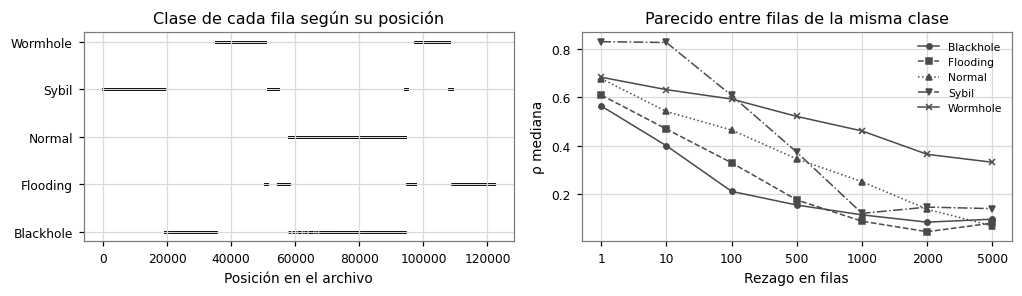

Mediana entre clases por rezago: {'Rezago 1': 0.678, 'Rezago 10': 0.542, 'Rezago 100': 0.466, 'Rezago 500': 0.346, 'Rezago 1000': 0.122, 'Rezago 2000': 0.139, 'Rezago 5000': 0.098}


**Interpretación.** El 93,0 % de las filas vecinas comparte clase, frente a 20,2 % bajo un orden aleatorio, y el tramo más largo de una sola clase tiene 19 180 filas. Además, entre filas de la misma clase, la ρ de Spearman mediana es de 0,678 en el rezago 1 y de 0,098 en el rezago 5000, frente a 0,000 con un orden aleatorio.

Esto significa que las filas no son independientes: el archivo conserva bloques de flujos muy parecidos, que sugieren un origen común en una misma simulación, aunque no trae el identificador que permitiría comprobarlo. Por eso, una partición aleatoria deja flujos casi gemelos en entrenamiento y en prueba, y mide en parte la capacidad de reconocer esa cercanía y no el ataque. Esa dependencia tampoco sigue a una entidad como el cliente: 125 de las 176 direcciones de origen aparecen en dos o más clases, y los tramos contiguos de una misma dirección tienen un largo mediano de 1 fila, de modo que agrupar por dirección no separaría a los flujos vecinos.

Por tal motivo, se declara la serie como unidad de independencia y, como el archivo no marca dónde empieza y termina cada una, se aproxima con una partición agrupada por bloques de filas contiguas, en la que un bloque completo queda en una sola partición.

**Decisión de preprocesamiento.** Cada fila se asigna a un bloque según su posición en el archivo, y los bloques se reparten entre las particiones, estratificando por clase.

**Impacto en la arquitectura.** Ninguno directo. La partición agrupada sí cambia el error con el que se comparan las arquitecturas, porque ahora mide la generalización a bloques no vistos.

**Riesgos.** El bloque es una aproximación, y no equivale a la simulación: los flujos a ambos lados del borde de un bloque siguen siendo parecidos, y un mismo escenario largo puede aportar bloques a varias particiones. Es decir, la partición agrupada reduce la fuga, pero no la elimina. Se declara como amenaza a la validez interna en la sección 5.5.

In [8]:
# Un tramo con un atributo constante no define ρ, y la mediana lo descarta
warnings.filterwarnings("ignore", category=stats.ConstantInputWarning)
vecinas = float((y[1:] == y[:-1]).mean())
azar_vecinas = float((p ** 2).sum())
tramos = pd.Series(y).ne(pd.Series(y).shift()).cumsum().value_counts()
REZAGOS = (1, 10, 100, 500, 1000, 2000, 5000)
x_log = np.log1p(x_crudo)
filas = []
for k, nombre in enumerate(CLASES):
    fila = {"Clase": nombre}
    pos = np.flatnonzero(y == k)
    for rezago in REZAGOS:
        a = pos[pos + rezago < N]
        a = a[y[a + rezago] == k]
        # Algunos atributos son constantes dentro de una clase: esos no aportan a la mediana
        rhos = [stats.spearmanr(x_log[a, j], x_log[a + rezago, j]).statistic for j in range(len(ATRIBUTOS)) if x_log[a, j].std() > 0 and x_log[a + rezago, j].std() > 0] if len(a) > 50 else []
        fila[f"Rezago {rezago}"] = float(np.nanmedian(rhos)) if rhos else np.nan
    filas.append(fila)
autocorrelacion = pd.DataFrame(filas)
display(autocorrelacion.style.hide(axis="index").format(precision=3, na_rep="sin pares"))
rng = np.random.default_rng(SEMILLA)
referencia = rng.permutation(N)
rho_azar = float(np.median([stats.spearmanr(x_log[:, j], x_log[referencia, j]).statistic for j in range(len(ATRIBUTOS))]))

fig, ejes = plt.subplots(1, 2, figsize=(9.4, 2.8))
ejes[0].scatter(np.arange(0, N, 15), y[::15], s=0.6, color=NEGRO)
ejes[0].set(yticks=range(K), yticklabels=CLASES, xlabel="Posición en el archivo", title="Clase de cada fila según su posición")
for fila, estilo in zip(autocorrelacion.to_dict("records"), [("-", "o"), ("--", "s"), (":", "^"), ("-.", "v"), ("-", "x")]):
    ejes[1].plot([str(r) for r in REZAGOS], [fila[f"Rezago {r}"] for r in REZAGOS], color=GRIS_OSCURO, linestyle=estilo[0], marker=estilo[1], markersize=3.5, linewidth=1, label=fila["Clase"])
ejes[1].set(xlabel="Rezago en filas", ylabel="ρ mediana", title="Parecido entre filas de la misma clase")
ejes[1].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()
mediana_por_rezago = autocorrelacion.drop(columns="Clase").median()
print("Mediana entre clases por rezago:", mediana_por_rezago.round(3).to_dict())
# Contraste con «cliente», la otra unidad de la lista del enunciado que podría aplicar
n_origenes = int(datos["SrcAddr"].nunique())
origenes_varias_clases = int((datos.groupby("SrcAddr")["label"].nunique() > 1).sum())
tramos_origen = datos["SrcAddr"].ne(datos["SrcAddr"].shift()).cumsum().value_counts()
interpretar(f'''**Interpretación.** El {num(100 * vecinas, 1)} % de las filas vecinas comparte clase, frente a {num(100 * azar_vecinas, 1)} % bajo un orden aleatorio, y el tramo más largo de una sola clase tiene {num(tramos.max(), 0)} filas. Además, entre filas de la misma clase, la ρ de Spearman mediana es de {num(mediana_por_rezago.iloc[0], 3)} en el rezago 1 y de {num(mediana_por_rezago.iloc[-1], 3)} en el rezago {REZAGOS[-1]}, frente a {num(abs(rho_azar), 3)} con un orden aleatorio.

Esto significa que las filas no son independientes: el archivo conserva bloques de flujos muy parecidos, que sugieren un origen común en una misma simulación, aunque no trae el identificador que permitiría comprobarlo. Por eso, una partición aleatoria deja flujos casi gemelos en entrenamiento y en prueba, y mide en parte la capacidad de reconocer esa cercanía y no el ataque. Esa dependencia tampoco sigue a una entidad como el cliente: {origenes_varias_clases} de las {n_origenes} direcciones de origen aparecen en dos o más clases, y los tramos contiguos de una misma dirección tienen un largo mediano de {num(tramos_origen.median(), 0)} fila, de modo que agrupar por dirección no separaría a los flujos vecinos.

Por tal motivo, se declara la serie como unidad de independencia y, como el archivo no marca dónde empieza y termina cada una, se aproxima con una partición agrupada por bloques de filas contiguas, en la que un bloque completo queda en una sola partición.

**Decisión de preprocesamiento.** Cada fila se asigna a un bloque según su posición en el archivo, y los bloques se reparten entre las particiones, estratificando por clase.

**Impacto en la arquitectura.** Ninguno directo. La partición agrupada sí cambia el error con el que se comparan las arquitecturas, porque ahora mide la generalización a bloques no vistos.

**Riesgos.** El bloque es una aproximación, y no equivale a la simulación: los flujos a ambos lados del borde de un bloque siguen siendo parecidos, y un mismo escenario largo puede aportar bloques a varias particiones. Es decir, la partición agrupada reduce la fuga, pero no la elimina. Se declara como amenaza a la validez interna en la sección 5.5.''')

In [9]:
LARGO_BLOQUE = 1000
RUTA_PARTICION = RESULTADOS / "particion.npz"
indices = np.flatnonzero(~datos[ATRIBUTOS + ["label"]].duplicated().to_numpy())
bloques = (datos["FlowID"].to_numpy() - 1) // LARGO_BLOQUE
if RUTA_PARTICION.exists():
    particion = np.load(RUTA_PARTICION)
    id_ent, id_val, id_pru = particion["entrenamiento"], particion["validacion"], particion["prueba"]
else:
    pos_resto, pos_pru = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEMILLA).split(indices, y[indices], bloques[indices]))
    id_pru, resto = indices[pos_pru], indices[pos_resto]
    pos_ent, pos_val = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEMILLA).split(resto, y[resto], bloques[resto]))
    id_ent, id_val = resto[pos_ent], resto[pos_val]
    np.savez(RUTA_PARTICION, entrenamiento=id_ent, validacion=id_val, prueba=id_pru)
assert not (set(bloques[id_ent]) & set(bloques[id_pru])) and not (set(bloques[id_ent]) & set(bloques[id_val])) and not (set(bloques[id_val]) & set(bloques[id_pru]))
SHA_PRUEBA = hashlib.sha256(np.sort(id_pru).tobytes()).hexdigest()
(RESULTADOS / "prueba.sha256").write_text(SHA_PRUEBA)
print("SHA-256 del conjunto de prueba:", SHA_PRUEBA)

PARTES = {"Entrenamiento": id_ent, "Validación": id_val, "Prueba": id_pru}
tabla_particion = pd.DataFrame({n: 100 * np.bincount(y[i], minlength=K) / len(i) for n, i in PARTES.items()}, index=CLASES)
tabla_particion.loc["Filas"] = [len(i) for i in PARTES.values()]
tabla_particion.loc["% del total"] = [100 * len(i) / len(indices) for i in PARTES.values()]
tabla_particion.loc["Bloques"] = [len(np.unique(bloques[i])) for i in PARTES.values()]
display(tabla_particion.round(2))
tabla_chi = np.array([np.bincount(y[i], minlength=K) for i in PARTES.values()])
chi_clase = stats.chi2_contingency(tabla_chi)
v_clase = cramer(tabla_chi)
brecha_clase = float(np.abs(tabla_particion.iloc[:K].sub(tabla_particion.iloc[:K].mean(axis=1), axis=0)).to_numpy().max())

ks = pd.Series({c: stats.ks_2samp(datos[c].to_numpy()[id_ent], datos[c].to_numpy()[id_pru]).statistic for c in ATRIBUTOS}).sort_values(ascending=False)
huellas_ent = set(huella.to_numpy()[id_ent])
casi_cruzan = float(np.mean([h in huellas_ent for h in huella.to_numpy()[id_pru]]))
exactas_cruzan = len(pd.merge(datos.iloc[id_ent][ATRIBUTOS], datos.iloc[id_pru][ATRIBUTOS], on=ATRIBUTOS, how="inner"))
print(f"Filas de prueba con un casi duplicado en entrenamiento: {100 * casi_cruzan:.1f} % | coincidencias exactas entre entrenamiento y prueba: {exactas_cruzan}")
interpretar(f'''**Interpretación.** Tras eliminar las filas repetidas quedan {num(len(indices), 0)} flujos, repartidos en bloques de {LARGO_BLOQUE} filas, porque en ese rezago la ρ mediana entre filas de la misma clase ya cayó a {num(mediana_por_rezago[f"Rezago {LARGO_BLOQUE}"], 3)}, sin dejar grupos tan grandes que la estratificación pierda sentido. Ningún bloque aparece en dos particiones. La proporción de clases {"difiere" if chi_clase[1] < 0.05 else "no difiere de forma significativa"} entre particiones ({valor_p(chi_clase[1])}), con un efecto de V de Cramér = {num(v_clase, 3)} y una brecha máxima de {num(brecha_clase, 2)} puntos porcentuales frente al promedio. En los atributos, la mayor distancia de Kolmogorov-Smirnov entre entrenamiento y prueba es de {num(ks.iloc[0], 3)}, en `{ks.index[0]}`.

Así mismo, el {num(100 * casi_cruzan, 1)} % de las filas de prueba tiene un casi duplicado en entrenamiento y hay {num(exactas_cruzan, 0)} coincidencias exactas, de modo que entre particiones casi no quedan flujos gemelos. Hay que tener en cuenta que eso no garantiza que una partición contenga solo simulaciones nuevas, porque el archivo no las identifica.

Por lo anterior, se conserva esta partición y se congela la prueba con su suma SHA-256.

**Decisión de preprocesamiento.** Partición estratificada por clase y agrupada por bloques, de 64, 16 y 20 %, con semilla {SEMILLA}, que se guarda en un archivo para reutilizarla en los Entregables 2 y 3.

**Impacto en la arquitectura.** Ninguno directo; todas las arquitecturas se comparan sobre las mismas particiones.

**Riesgos.** Con pocos bloques por clase, la composición de la prueba depende de qué bloques le tocaron. Por eso, la variabilidad entre semillas no incluye la de la partición, lo que se declara en la sección 7.''')

SHA-256 del conjunto de prueba: 2a2dab99c08ed1f19f24add07f5c6b0375e5ce0df7951a99090f54f4f2cd32b4


,Entrenamiento,Validación,Prueba
Blackhole,23.67,22.07,21.15
Flooding,10.33,10.35,10.34
Normal,22.79,23.46,23.15
Sybil,20.59,21.65,21.27
Wormhole,22.62,22.47,24.09
Filas,73267.00,17802.00,22883.00
% del total,64.30,15.62,20.08
Bloques,78.00,19.00,24.00


Filas de prueba con un casi duplicado en entrenamiento: 1.8 % | coincidencias exactas entre entrenamiento y prueba: 0


**Interpretación.** Tras eliminar las filas repetidas quedan 113 952 flujos, repartidos en bloques de 1000 filas, porque en ese rezago la ρ mediana entre filas de la misma clase ya cayó a 0,122, sin dejar grupos tan grandes que la estratificación pierda sentido. Ningún bloque aparece en dos particiones. La proporción de clases difiere entre particiones (p < 0,001), con un efecto de V de Cramér = 0,019 y una brecha máxima de 1,37 puntos porcentuales frente al promedio. En los atributos, la mayor distancia de Kolmogorov-Smirnov entre entrenamiento y prueba es de 0,128, en `TxPacketRate/s`.

Así mismo, el 1,8 % de las filas de prueba tiene un casi duplicado en entrenamiento y hay 0 coincidencias exactas, de modo que entre particiones casi no quedan flujos gemelos. Hay que tener en cuenta que eso no garantiza que una partición contenga solo simulaciones nuevas, porque el archivo no las identifica.

Por lo anterior, se conserva esta partición y se congela la prueba con su suma SHA-256.

**Decisión de preprocesamiento.** Partición estratificada por clase y agrupada por bloques, de 64, 16 y 20 %, con semilla 42, que se guarda en un archivo para reutilizarla en los Entregables 2 y 3.

**Impacto en la arquitectura.** Ninguno directo; todas las arquitecturas se comparan sobre las mismas particiones.

**Riesgos.** Con pocos bloques por clase, la composición de la prueba depende de qué bloques le tocaron. Por eso, la variabilidad entre semillas no incluye la de la partición, lo que se declara en la sección 7.

In [10]:
# Solo con entrenamiento y validación: el conjunto de prueba ya está congelado
id_dev = np.concatenate([id_ent, id_val])
x_dev = np.log1p(x_crudo)


def probar_boosting(columnas, ent, val):
    modelo = HistGradientBoostingClassifier(max_iter=150, random_state=SEMILLA).fit(columnas[ent], y[ent])
    return f1_score(y[val], modelo.predict(columnas[val]), average="macro")


ent_azar, val_azar = train_test_split(id_dev, test_size=len(id_val), stratify=y[id_dev], random_state=SEMILLA)
f1_azar = probar_boosting(x_dev, ent_azar, val_azar)
f1_grupos = probar_boosting(x_dev, id_ent, id_val)
display(pd.DataFrame({"Partición de validación": ["Aleatoria estratificada, como en la literatura", f"Agrupada por bloques de {LARGO_BLOQUE} filas"], "F1 macro de referencia (boosting)": [f1_azar, f1_grupos]}).style.hide(axis="index").format({"F1 macro de referencia (boosting)": "{:.4f}"}))
filas_largo = []
for largo in (100, 500, 1000, 2000, 5000):
    grupos_dev = (datos["FlowID"].to_numpy()[id_dev] - 1) // largo
    valores = []
    for pos_a, pos_b in GroupShuffleSplit(3, test_size=0.2, random_state=SEMILLA).split(id_dev, groups=grupos_dev):
        modelo = HistGradientBoostingClassifier(max_iter=100, random_state=SEMILLA).fit(x_dev[id_dev[pos_a]], y[id_dev[pos_a]])
        valores.append(f1_score(y[id_dev[pos_b]], modelo.predict(x_dev[id_dev[pos_b]]), average="macro"))
    filas_largo.append({"Filas por bloque": largo, "Bloques": len(np.unique(grupos_dev)), "F1 macro medio": np.mean(valores), "Desviación entre particiones": np.std(valores, ddof=1)})
sensibilidad = pd.DataFrame(filas_largo)
display(sensibilidad.style.hide(axis="index").format({"F1 macro medio": "{:.4f}", "Desviación entre particiones": "{:.4f}"}))
interpretar(f'''**Interpretación.** Con el mismo modelo de referencia y los mismos atributos, el F1 macro de validación es de {num(f1_azar, 4)} con partición aleatoria y de {num(f1_grupos, 4)} con partición agrupada, una diferencia de {num(f1_azar - f1_grupos, 4)}. Al variar el largo del bloque dentro de entrenamiento y validación, con tres particiones por largo, el F1 macro medio va de {num(sensibilidad["F1 macro medio"].max(), 3)} a {num(sensibilidad["F1 macro medio"].min(), 3)}, y la desviación entre particiones llega a {num(sensibilidad["Desviación entre particiones"].max(), 3)}. Con los bloques más largos, esa desviación crece porque quedan muy pocos bloques y una partición puede quedarse casi sin una clase, y por eso no se usan.

Esto quiere decir que parte del desempeño de una partición aleatoria proviene de reconocer flujos vecinos en el archivo, y esa magnitud supera ampliamente el margen δ = 0,01. Por lo tanto, los valores de la literatura y los de este trabajo no son directamente comparables si la literatura usa partición aleatoria, lo que se examina en la sección 3.4.

En consecuencia, se decide reportar el baseline con la partición agrupada, por ser la que estima mejor la generalización a tráfico no visto.''')

Partición de validación,F1 macro de referencia (boosting)
"Aleatoria estratificada, como en la literatura",0.9555
Agrupada por bloques de 1000 filas,0.8866


Filas por bloque,Bloques,F1 macro medio,Desviación entre particiones
100,948,0.9468,0.0031
500,193,0.8926,0.0577
1000,97,0.8913,0.0669
2000,60,0.8979,0.0561
5000,25,0.7638,0.1682


**Interpretación.** Con el mismo modelo de referencia y los mismos atributos, el F1 macro de validación es de 0,9555 con partición aleatoria y de 0,8866 con partición agrupada, una diferencia de 0,0689. Al variar el largo del bloque dentro de entrenamiento y validación, con tres particiones por largo, el F1 macro medio va de 0,947 a 0,764, y la desviación entre particiones llega a 0,168. Con los bloques más largos, esa desviación crece porque quedan muy pocos bloques y una partición puede quedarse casi sin una clase, y por eso no se usan.

Esto quiere decir que parte del desempeño de una partición aleatoria proviene de reconocer flujos vecinos en el archivo, y esa magnitud supera ampliamente el margen δ = 0,01. Por lo tanto, los valores de la literatura y los de este trabajo no son directamente comparables si la literatura usa partición aleatoria, lo que se examina en la sección 3.4.

En consecuencia, se decide reportar el baseline con la partición agrupada, por ser la que estima mejor la generalización a tráfico no visto.

#### 2.1.4 Sesgos y desplazamientos de distribución

En esta parte se revisan los sesgos de representación, temporales, espaciales y de dominio; luego se mide si algún atributo funciona como atajo (Geirhos et al., 2020), es decir, si reconoce la clase sin decir nada del comportamiento del tráfico, y finalmente un clasificador adversarial intenta distinguir las particiones entre sí, de modo que un AUC cercano a 0,5 indica que no hay desplazamiento de covariables (Lopez-Paz y Oquab, 2017).

In [11]:
ip_origen = datos["SrcAddr"].astype("category").cat.codes.to_numpy(dtype=float)
ip_destino = datos["DstAddr"].astype("category").cat.codes.to_numpy(dtype=float)
CONJUNTOS = {"Solo FlowID": datos[["FlowID"]].to_numpy(dtype=float), "Solo direcciones IP": np.column_stack([ip_origen, ip_destino]),
             "Solo puertos": datos[["SrcPort", "DstPort"]].to_numpy(dtype=float), "Solo atributos de tráfico y desempeño": x_dev}
atajos = pd.DataFrame([{"Atributos": n, "F1 macro, partición aleatoria": probar_boosting(c, ent_azar, val_azar) if n != "Solo atributos de tráfico y desempeño" else f1_azar,
                        "F1 macro, partición agrupada": probar_boosting(c, id_ent, id_val) if n != "Solo atributos de tráfico y desempeño" else f1_grupos} for n, c in CONJUNTOS.items()])
display(atajos.style.hide(axis="index").format(precision=4))
tabla_puerto = pd.crosstab(nombre_clase, datos["SrcPort"]).reindex(CLASES)
display(tabla_puerto)
ip_una_clase = int((datos.groupby("SrcAddr")["label"].nunique() == 1).sum())
por_nombre = atajos.set_index("Atributos")
clases_sin_654 = [c for c in CLASES if tabla_puerto.loc[c, 654] == 0]
interpretar(f'''**Interpretación.** En sesgos de representación, las cinco clases tienen entre {num(100 * p.min(), 1)} % y {num(100 * p.max(), 1)} % de los flujos, sin subpoblaciones que se puedan comparar dentro de cada clase. En sesgos temporales y espaciales, el archivo no trae marcas de tiempo ni coordenadas, de modo que solo se puede auditar el orden de las filas, como se hizo en la sección 2.1.3. En cuanto al dominio, todos los flujos provienen de un solo simulador y de una sola configuración de radio y enrutamiento.

En atajos, `FlowID`, que es solo un índice, alcanza por sí solo un F1 macro de {num(por_nombre.loc["Solo FlowID", "F1 macro, partición aleatoria"], 3)} con partición aleatoria, y baja a {num(por_nombre.loc["Solo FlowID", "F1 macro, partición agrupada"], 3)} con partición agrupada. Las direcciones IP alcanzan {num(por_nombre.loc["Solo direcciones IP", "F1 macro, partición aleatoria"], 3)} y {num(por_nombre.loc["Solo direcciones IP", "F1 macro, partición agrupada"], 3)}, y {ip_una_clase} direcciones de origen aparecen en una sola clase. Los puertos alcanzan {num(por_nombre.loc["Solo puertos", "F1 macro, partición aleatoria"], 3)}, porque el puerto 654, el del enrutamiento AODV, no aparece en {" ni en ".join(clases_sin_654)}.

Esto significa que estos atributos reconocen el escenario simulado y no el comportamiento del ataque. Un modelo que los use obtendría un resultado alto que no se traslada a otra red, donde los índices, las direcciones y la mezcla de tráfico serían otros.

**Decisión de preprocesamiento.** Se excluyen `FlowID`, `SrcAddr`, `DstAddr`, `SrcPort` y `DstPort`, además de `Protocol`, que es constante. Quedan {len(ATRIBUTOS)} atributos de tráfico y desempeño, los mismos que recomiendan los autores del conjunto de datos.

**Impacto en la arquitectura.** La entrada es un vector de {len(ATRIBUTOS)} valores numéricos, sin variables categóricas, de modo que no se necesitan capas de *embedding* para entidades.

**Riesgos.** Los atributos de tráfico también pueden reflejar la configuración de cada escenario, como la duración de la simulación o la tasa de envío. Esa parte no se puede separar del ataque con estos datos, y se declara como amenaza a la validez externa en la sección 5.5. Además, `FlowID` conserva {num(por_nombre.loc["Solo FlowID", "F1 macro, partición agrupada"], 3)} con partición agrupada, a solo {num(por_nombre.loc["Solo atributos de tráfico y desempeño", "F1 macro, partición agrupada"] - por_nombre.loc["Solo FlowID", "F1 macro, partición agrupada"], 3)} de la referencia con atributos de tráfico, porque los tramos de una sola clase, de hasta {num(tramos.max(), 0)} filas, son más largos que el bloque, y muchos bloques de validación quedan rodeados de bloques de entrenamiento de la misma clase. Esto quiere decir que la partición no impide reconocer el tramo del archivo, y un modelo cuyos atributos delaten ese tramo conservaría parte de esa ventaja.''')

Atributos,"F1 macro, partición aleatoria","F1 macro, partición agrupada"
Solo FlowID,0.9260,0.8593
Solo direcciones IP,0.5920,0.5280
Solo puertos,0.2006,0.2087
Solo atributos de tráfico y desempeño,0.9555,0.8866


SrcPort,9,654
label,,
Blackhole,11248,14862
Flooding,19726,0
Normal,11294,14878
Sybil,24077,0
Wormhole,25494,592


**Interpretación.** En sesgos de representación, las cinco clases tienen entre 16,1 % y 21,4 % de los flujos, sin subpoblaciones que se puedan comparar dentro de cada clase. En sesgos temporales y espaciales, el archivo no trae marcas de tiempo ni coordenadas, de modo que solo se puede auditar el orden de las filas, como se hizo en la sección 2.1.3. En cuanto al dominio, todos los flujos provienen de un solo simulador y de una sola configuración de radio y enrutamiento.

En atajos, `FlowID`, que es solo un índice, alcanza por sí solo un F1 macro de 0,926 con partición aleatoria, y baja a 0,859 con partición agrupada. Las direcciones IP alcanzan 0,592 y 0,528, y 51 direcciones de origen aparecen en una sola clase. Los puertos alcanzan 0,201, porque el puerto 654, el del enrutamiento AODV, no aparece en Flooding ni en Sybil.

Esto significa que estos atributos reconocen el escenario simulado y no el comportamiento del ataque. Un modelo que los use obtendría un resultado alto que no se traslada a otra red, donde los índices, las direcciones y la mezcla de tráfico serían otros.

**Decisión de preprocesamiento.** Se excluyen `FlowID`, `SrcAddr`, `DstAddr`, `SrcPort` y `DstPort`, además de `Protocol`, que es constante. Quedan 16 atributos de tráfico y desempeño, los mismos que recomiendan los autores del conjunto de datos.

**Impacto en la arquitectura.** La entrada es un vector de 16 valores numéricos, sin variables categóricas, de modo que no se necesitan capas de *embedding* para entidades.

**Riesgos.** Los atributos de tráfico también pueden reflejar la configuración de cada escenario, como la duración de la simulación o la tasa de envío. Esa parte no se puede separar del ataque con estos datos, y se declara como amenaza a la validez externa en la sección 5.5. Además, `FlowID` conserva 0,859 con partición agrupada, a solo 0,027 de la referencia con atributos de tráfico, porque los tramos de una sola clase, de hasta 19 180 filas, son más largos que el bloque, y muchos bloques de validación quedan rodeados de bloques de entrenamiento de la misma clase. Esto quiere decir que la partición no impide reconocer el tramo del archivo, y un modelo cuyos atributos delaten ese tramo conservaría parte de esa ventaja.

In [12]:
def auc_adversarial(a, b, n=20000):
    rng_adv = np.random.default_rng(SEMILLA)
    a, b = rng_adv.permutation(a)[:n], rng_adv.permutation(b)[:n]
    matriz = x_dev[np.concatenate([a, b])]
    objetivo = np.r_[np.zeros(len(a)), np.ones(len(b))]
    prob = cross_val_predict(HistGradientBoostingClassifier(max_iter=100, random_state=SEMILLA), matriz, objetivo, cv=3, method="predict_proba")[:, 1]
    return roc_auc_score(objetivo, prob)


auc_val, auc_pru = auc_adversarial(id_ent, id_val), auc_adversarial(id_ent, id_pru)
print(f"Clasificador adversarial, AUC: entrenamiento frente a validación {auc_val:.3f} | entrenamiento frente a prueba {auc_pru:.3f}")
pruebas_ks = pd.DataFrame([{"Atributo": c, "KS": stats.ks_2samp(datos[c].to_numpy()[id_ent], datos[c].to_numpy()[id_pru]).statistic, "p": stats.ks_2samp(datos[c].to_numpy()[id_ent], datos[c].to_numpy()[id_pru]).pvalue} for c in ATRIBUTOS])
pruebas_ks["p Holm"] = multipletests(pruebas_ks["p"], method="holm")[1]
display(pruebas_ks.sort_values("KS", ascending=False).head(6).style.hide(axis="index").format({"KS": "{:.3f}", "p": "{:.2e}", "p Holm": "{:.2e}"}))
desplazado = max(abs(auc_val - 0.5), abs(auc_pru - 0.5)) >= 0.05
interpretar(f'''**Interpretación.** El clasificador adversarial obtiene un AUC de {num(auc_val, 3)} al separar entrenamiento de validación y de {num(auc_pru, 3)} al separar entrenamiento de prueba. La mayor distancia de Kolmogorov-Smirnov es de {num(pruebas_ks["KS"].max(), 3)}.

{"Esto significa que hay un desplazamiento de covariables entre particiones, esperable al partir por bloques, porque cada partición reúne tramos distintos del archivo." if desplazado else "Esto significa que no se detecta un desplazamiento apreciable de covariables entre particiones."} Hay que tener en cuenta que, con particiones de este tamaño, cualquier diferencia pequeña alcanza significancia, de modo que el AUC, como tamaño de efecto, pesa más que el valor p.

**Decisión de preprocesamiento.** Se conserva la partición, porque ese desplazamiento es justamente lo que un modelo enfrentará con tráfico de tramos no vistos, y se ajustan las transformaciones solo con entrenamiento.

**Impacto en la arquitectura.** Ninguno en la estructura. Este desplazamiento justifica regularizar y seleccionar con validación agrupada.

**Riesgos.** Esta prueba solo observa los atributos, no la relación entre atributos y clase, de modo que no descarta un cambio en esa relación.''')

Clasificador adversarial, AUC: entrenamiento frente a validación 0.889 | entrenamiento frente a prueba 0.848


Atributo,KS,p,p Holm
TxPacketRate/s,0.128,2.30e-251,3.67e-250
TxPackets,0.118,1.79e-212,2.68e-211
TxByteRate/s,0.107,6.04e-175,8.45e-174
TxBytes,0.104,1.20e-165,1.56e-164
RxPacketRate/s,0.104,4.06e-163,4.87e-162
AverageHopCount,0.101,3.83e-154,4.22e-153


**Interpretación.** El clasificador adversarial obtiene un AUC de 0,889 al separar entrenamiento de validación y de 0,848 al separar entrenamiento de prueba. La mayor distancia de Kolmogorov-Smirnov es de 0,128.

Esto significa que hay un desplazamiento de covariables entre particiones, esperable al partir por bloques, porque cada partición reúne tramos distintos del archivo. Hay que tener en cuenta que, con particiones de este tamaño, cualquier diferencia pequeña alcanza significancia, de modo que el AUC, como tamaño de efecto, pesa más que el valor p.

**Decisión de preprocesamiento.** Se conserva la partición, porque ese desplazamiento es justamente lo que un modelo enfrentará con tráfico de tramos no vistos, y se ajustan las transformaciones solo con entrenamiento.

**Impacto en la arquitectura.** Ninguno en la estructura. Este desplazamiento justifica regularizar y seleccionar con validación agrupada.

**Riesgos.** Esta prueba solo observa los atributos, no la relación entre atributos y clase, de modo que no descarta un cambio en esa relación.

### 2.2 EDA específico: clasificación con datos tabulares

En esta parte se aplica el bloque de datos tabulares del enunciado: la estructura de los atributos, su relación con el objetivo y la complejidad de la tarea. Desde aquí se trabaja solo con el conjunto de entrenamiento.

#### 2.2.1 Estructura de atributos

Se tipifica cada columna y se describe su escala, su asimetría y sus valores atípicos, con el criterio del rango intercuartílico: un valor es atípico si queda a más de 1,5 veces ese rango por fuera de los cuartiles.

Columna,Tipo,Cardinalidad,Uso
FlowID,Índice,122171,Excluida
SrcAddr,Categórica nominal,176,Excluida
SrcPort,Categórica de puerto,2,Excluida
DstAddr,Categórica nominal,218,Excluida
DstPort,Categórica de puerto,2,Excluida
Protocol,Categórica nominal,1,Excluida


Atributo,Valores distintos,Mediana,Máximo,Asimetría,Curtosis,% atípicos,Asimetría tras log,% atípicos tras log
FlowDuration/s,42145,246.012,10591.800,1.857,11.829,0.925,-0.739,1.086
TxPackets,2050,50.000,220886.000,61.415,5337.110,16.889,0.441,0.040
RxPackets,2605,23.000,63653.000,12.181,285.215,18.785,0.560,0.085
LostPackets,641,13.000,212557.000,104.356,12029.881,15.938,0.217,0.031
TxBytes,8030,2888.000,11265075.000,41.199,2953.558,17.646,0.490,0.187
RxBytes,5762,1334.000,3246018.000,9.980,144.446,19.516,0.512,0.203
TxPacketRate/s,51405,0.194,33116.600,162.261,29079.142,6.044,2.645,2.107
RxPacketRate/s,55333,0.059,13115.800,145.827,22492.069,4.621,2.718,1.475
TxByteRate/s,51464,10.742,2516860.000,163.375,29366.831,5.798,0.475,0.082
RxByteRate/s,56521,3.436,996800.000,145.908,22509.087,4.399,0.649,0.027


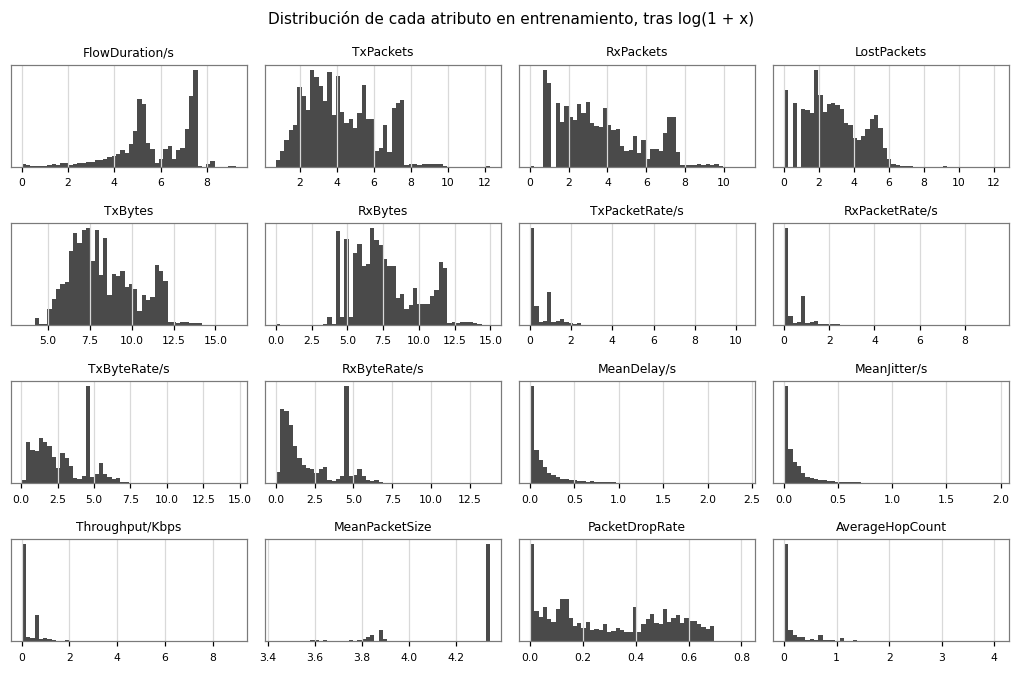

**Interpretación.** Las 6 columnas de conexión son categóricas o índices, y ya se excluyeron; los 16 atributos restantes son numéricos. Su asimetría es extrema: la mayor es de 163,4, en `TxByteRate/s`, y la mediana de esa asimetría entre atributos es de 29,4, con una mediana de 8,0 % de valores atípicos. Tras aplicar $\log(1 + x)$, la asimetría mediana baja a 0,54 y los atípicos a 0,2 %.

Esto significa que unos pocos flujos muy grandes dominarían el gradiente si se usaran las escalas originales, cuyos máximos llegan a 11 265 075. Además, varios histogramas tienen más de una moda, lo que apunta a mezclas de tipos de flujo.

Por tal motivo, se opta por transformar con $\log(1 + x)$, que conserva los ceros, y estandarizar después con la media y la desviación de entrenamiento.

**Decisión de preprocesamiento.** Recorte de `PacketDropRate` a 1, $\log(1 + x)$ en todos los atributos y estandarización ajustada solo con entrenamiento. No se eliminan atípicos, porque son flujos válidos y pueden ser la huella del ataque.

**Impacto en la arquitectura.** Con la entrada en escala comparable, un perceptrón multicapa no necesita capas de normalización para arrancar. No hay variables categóricas que codificar.

**Riesgos.** Ajustar la transformación con todo el archivo sería una fuga, y por eso solo se usa entrenamiento. Los atípicos pueden seguir pesando en modelos sin regularización.

In [13]:
def atipicos(valores):
    q1, q3 = np.percentile(valores, [25, 75])
    return float(100 * ((valores < q1 - 1.5 * (q3 - q1)) | (valores > q3 + 1.5 * (q3 - q1))).mean())


x_ent_crudo = x_crudo[id_ent]
filas = [{"Columna": c, "Tipo": "Categórica nominal" if c in ("SrcAddr", "DstAddr", "Protocol") else "Categórica de puerto" if c in ("SrcPort", "DstPort") else "Índice", "Cardinalidad": int(datos[c].nunique()), "Uso": "Excluida"} for c in IDENTIFICADORES]
display(pd.DataFrame(filas).style.hide(axis="index"))
estructura = pd.DataFrame([{"Atributo": c, "Valores distintos": len(np.unique(x_ent_crudo[:, j])), "Mediana": np.median(x_ent_crudo[:, j]), "Máximo": x_ent_crudo[:, j].max(), "Asimetría": stats.skew(x_ent_crudo[:, j]), "Curtosis": stats.kurtosis(x_ent_crudo[:, j]),
                            "% atípicos": atipicos(x_ent_crudo[:, j]), "Asimetría tras log": stats.skew(np.log1p(x_ent_crudo[:, j])), "% atípicos tras log": atipicos(np.log1p(x_ent_crudo[:, j]))} for j, c in enumerate(ATRIBUTOS)])
display(estructura.style.hide(axis="index").format(precision=3))
fig, ejes = plt.subplots(4, 4, figsize=(9.4, 6.2))
for eje, (j, c) in zip(ejes.ravel(), enumerate(ATRIBUTOS)):
    eje.hist(np.log1p(x_ent_crudo[:, j]), bins=50, color=GRIS_OSCURO)
    eje.set_title(c, fontsize=8)
    eje.set_yticks([])
    eje.tick_params(labelsize=7)
fig.suptitle("Distribución de cada atributo en entrenamiento, tras log(1 + x)", fontsize=10)
plt.tight_layout()
plt.show()
mas_asimetrico = estructura.loc[estructura["Asimetría"].idxmax()]
interpretar(f'''**Interpretación.** Las {len(IDENTIFICADORES)} columnas de conexión son categóricas o índices, y ya se excluyeron; los {len(ATRIBUTOS)} atributos restantes son numéricos. Su asimetría es extrema: la mayor es de {num(mas_asimetrico["Asimetría"], 1)}, en `{mas_asimetrico["Atributo"]}`, y la mediana de esa asimetría entre atributos es de {num(estructura["Asimetría"].median(), 1)}, con una mediana de {num(estructura["% atípicos"].median(), 1)} % de valores atípicos. Tras aplicar $\\log(1 + x)$, la asimetría mediana baja a {num(estructura["Asimetría tras log"].median(), 2)} y los atípicos a {num(estructura["% atípicos tras log"].median(), 1)} %.

Esto significa que unos pocos flujos muy grandes dominarían el gradiente si se usaran las escalas originales, cuyos máximos llegan a {num(estructura["Máximo"].max(), 0)}. Además, varios histogramas tienen más de una moda, lo que apunta a mezclas de tipos de flujo.

Por tal motivo, se opta por transformar con $\\log(1 + x)$, que conserva los ceros, y estandarizar después con la media y la desviación de entrenamiento.

**Decisión de preprocesamiento.** Recorte de `PacketDropRate` a 1, $\\log(1 + x)$ en todos los atributos y estandarización ajustada solo con entrenamiento. No se eliminan atípicos, porque son flujos válidos y pueden ser la huella del ataque.

**Impacto en la arquitectura.** Con la entrada en escala comparable, un perceptrón multicapa no necesita capas de normalización para arrancar. No hay variables categóricas que codificar.

**Riesgos.** Ajustar la transformación con todo el archivo sería una fuga, y por eso solo se usa entrenamiento. Los atípicos pueden seguir pesando en modelos sin regularización.''')

#### 2.2.2 Relación entre atributos y objetivo

Se miden las correlaciones lineales y de rango entre atributos, la información mutua de cada atributo con la clase, para captar relaciones no lineales, y la multicolinealidad, con el factor de inflación de varianza, $VIF_j = 1 / (1 - R_j^2)$, y el número de condición de la matriz de correlación.

Atributo,Información mutua (nats),VIF
TxByteRate/s,0.982,449.6
FlowDuration/s,0.934,82.6
TxPacketRate/s,0.932,24.8
RxByteRate/s,0.853,367.7
Throughput/Kbps,0.853,192.0
TxBytes,0.843,"2,209.3"
RxPacketRate/s,0.825,289.8
PacketDropRate,0.817,9.4
RxBytes,0.725,616.6
TxPackets,0.639,"2,156.6"


|r| de Pearson,|ρ| de Spearman,Atributo,Atributo 2
0.9940,0.9927,RxPackets,RxBytes
0.9934,0.9899,RxPacketRate/s,Throughput/Kbps
0.9928,0.9907,TxPackets,TxBytes
0.9347,0.9112,TxPackets,RxPackets
0.9313,0.9000,RxPackets,TxBytes
0.9286,0.9028,TxBytes,RxBytes
0.9212,0.9059,TxByteRate/s,RxByteRate/s
0.9207,0.8990,TxPackets,RxBytes


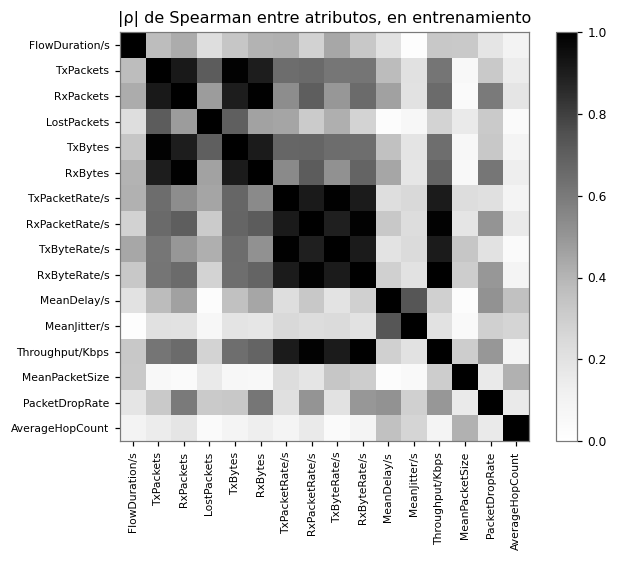

**Interpretación.** El atributo con más información sobre la clase es `TxByteRate/s`, con 0,982 nats, y el de menos es `MeanDelay/s`, con 0,231 nats, frente a una entropía de la clase de 1,604 nats. En multicolinealidad, el VIF llega a 2 209, el número de condición es de 190 y 0 pares tienen $|r|$ mayor que 0,999.

Esto se explica por la construcción de los atributos: las tasas son cocientes de los conteos sobre la duración, y, en la escala original, `Throughput/Kbps` equivale a `RxByteRate/s` en otras unidades. Es decir, varios atributos repiten la misma información, y los coeficientes de un modelo lineal no serían interpretables. Así mismo, ningún atributo alcanza por sí solo la entropía de la clase, de modo que la clasificación requiere combinarlos.

En ese sentido, se conservan los 16 atributos para los modelos de Deep Learning, porque la literatura usa los mismos y porque una red con regularización tolera la colinealidad, aunque sí se usa regularización L2 en el modelo lineal de referencia.

**Decisión de preprocesamiento.** No se eliminan atributos por colinealidad. No se detectan atributos derivados de la etiqueta entre los 16 que se conservan; los candidatos a fuga, `FlowID`, IP y puertos, ya se excluyeron en la sección 2.1.4.

**Impacto en la arquitectura.** La redundancia reduce la dimensión efectiva, de modo que no se justifican capas muy anchas y conviene la regularización. Además, el orden de los atributos no tiene significado físico, lo cual cuestiona el sesgo inductivo de los modelos que leen el vector como una secuencia.

**Riesgos.** La información mutua se estima sobre una muestra de 30 000 flujos y no capta interacciones entre atributos.

In [14]:
TOPE_TASA = np.where(np.array(ATRIBUTOS) == "PacketDropRate", 1.0, np.inf)


def transformar(matriz):
    return np.log1p(np.minimum(matriz, TOPE_TASA))


x_ent_log = transformar(x_ent_crudo)
pearson = np.corrcoef(x_ent_log, rowvar=False)
spearman = stats.spearmanr(x_ent_log).statistic
autovalores = np.linalg.eigvalsh(pearson)
condicion = float(np.sqrt(autovalores.max() / max(autovalores.min(), 1e-12)))
vif = np.diag(np.linalg.pinv(pearson))
rng_mi = np.random.default_rng(SEMILLA)
muestra_mi = rng_mi.permutation(len(id_ent))[:30000]
info_mutua = mutual_info_classif(x_ent_log[muestra_mi], y[id_ent][muestra_mi], random_state=SEMILLA)
relacion = pd.DataFrame({"Atributo": ATRIBUTOS, "Información mutua (nats)": info_mutua, "VIF": vif}).sort_values("Información mutua (nats)", ascending=False)
display(relacion.style.hide(axis="index").format({"Información mutua (nats)": "{:.3f}", "VIF": "{:,.1f}"}))
pares = sorted([(abs(pearson[i, j]), abs(spearman[i, j]), ATRIBUTOS[i], ATRIBUTOS[j]) for i in range(len(ATRIBUTOS)) for j in range(i + 1, len(ATRIBUTOS))], reverse=True)
display(pd.DataFrame(pares[:8], columns=["|r| de Pearson", "|ρ| de Spearman", "Atributo", "Atributo 2"]).style.hide(axis="index").format(precision=4))
fig, eje = plt.subplots(figsize=(6.2, 5.2))
imagen = eje.imshow(np.abs(spearman), vmin=0, vmax=1)
eje.set_xticks(range(len(ATRIBUTOS)), ATRIBUTOS, rotation=90, fontsize=7)
eje.set_yticks(range(len(ATRIBUTOS)), ATRIBUTOS, fontsize=7)
eje.grid(False)
eje.set_title("|ρ| de Spearman entre atributos, en entrenamiento")
fig.colorbar(imagen, fraction=0.046)
plt.tight_layout()
plt.show()
perfectos = [(a, b) for r, _, a, b in pares if r > 0.999]
interpretar(f'''**Interpretación.** El atributo con más información sobre la clase es `{relacion.iloc[0]["Atributo"]}`, con {num(relacion.iloc[0]["Información mutua (nats)"], 3)} nats, y el de menos es `{relacion.iloc[-1]["Atributo"]}`, con {num(relacion.iloc[-1]["Información mutua (nats)"], 3)} nats, frente a una entropía de la clase de {num(entropia * np.log(2), 3)} nats. En multicolinealidad, el VIF llega a {num(relacion["VIF"].max(), 0)}, el número de condición es de {num(condicion, 0)} y {len(perfectos)} pares tienen $|r|$ mayor que 0,999{", como `" + perfectos[0][0] + "` y `" + perfectos[0][1] + "`" if perfectos else ""}.

Esto se explica por la construcción de los atributos: las tasas son cocientes de los conteos sobre la duración, y, en la escala original, `Throughput/Kbps` equivale a `RxByteRate/s` en otras unidades. Es decir, varios atributos repiten la misma información, y los coeficientes de un modelo lineal no serían interpretables. Así mismo, ningún atributo alcanza por sí solo la entropía de la clase, de modo que la clasificación requiere combinarlos.

En ese sentido, se conservan los {len(ATRIBUTOS)} atributos para los modelos de Deep Learning, porque la literatura usa los mismos y porque una red con regularización tolera la colinealidad, aunque sí se usa regularización L2 en el modelo lineal de referencia.

**Decisión de preprocesamiento.** No se eliminan atributos por colinealidad. No se detectan atributos derivados de la etiqueta entre los {len(ATRIBUTOS)} que se conservan; los candidatos a fuga, `FlowID`, IP y puertos, ya se excluyeron en la sección 2.1.4.

**Impacto en la arquitectura.** La redundancia reduce la dimensión efectiva, de modo que no se justifican capas muy anchas y conviene la regularización. Además, el orden de los atributos no tiene significado físico, lo cual cuestiona el sesgo inductivo de los modelos que leen el vector como una secuencia.

**Riesgos.** La información mutua se estima sobre una muestra de 30 000 flujos y no capta interacciones entre atributos.''')

#### 2.2.3 Complejidad de la tarea

Se ajusta una regresión logística con regularización L2 para estimar la separabilidad lineal y dimensionar el margen de mejora disponible. Esta es una referencia de contexto, no un modelo base, y el boosting de la sección 2.1.3 se usa como referencia de lo que alcanza un modelo no lineal sin Deep Learning.

In [15]:
MEDIA = transformar(x_crudo[id_ent]).mean(0)
DESVIACION = transformar(x_crudo[id_ent]).std(0)
X_std = (transformar(x_crudo) - MEDIA) / DESVIACION
logistico = LogisticRegression(C=1.0, max_iter=3000).fit(X_std[id_ent], y[id_ent])
pred_log = logistico.predict(X_std[id_val])
f1_log_val = f1_score(y[id_val], pred_log, average="macro")
f1_log_ent = f1_score(y[id_ent], logistico.predict(X_std[id_ent]), average="macro")
boosting = HistGradientBoostingClassifier(max_iter=150, random_state=SEMILLA).fit(X_std[id_ent], y[id_ent])
pred_boost = boosting.predict(X_std[id_val])
complejidad = pd.DataFrame({"Clase": CLASES, "F1 logístico": f1_score(y[id_val], pred_log, average=None), "F1 boosting": f1_score(y[id_val], pred_boost, average=None)})
display(complejidad.style.hide(axis="index").format(precision=4))
f1_boost_val = f1_score(y[id_val], pred_boost, average="macro")
clase_lineal = complejidad.loc[complejidad["F1 logístico"].idxmin(), "Clase"]
margen_lineal = f1_boost_val - f1_log_val
gana_lineal = enumerar(complejidad.loc[complejidad["F1 logístico"] > complejidad["F1 boosting"], "Clase"])
gana_boosting = enumerar(complejidad.loc[complejidad["F1 boosting"] > complejidad["F1 logístico"], "Clase"])
interpretar(f'''**Interpretación.** En validación, la regresión logística obtiene un F1 macro de {num(f1_log_val, 4)}, con {num(f1_log_ent, 4)} en entrenamiento, y el boosting obtiene {num(f1_boost_val, 4)}. Por clase, el modelo lineal es mejor en {gana_lineal}, mientras que el boosting lo es en {gana_boosting}. La clase más difícil para el modelo lineal es {clase_lineal}, con F1 de {num(complejidad["F1 logístico"].min(), 3)}.

Esto significa que la tarea es en buena parte separable con una frontera lineal sobre los logaritmos, y que, en estos bloques de validación y sin ajustar el boosting, la no linealidad aporta {num(margen_lineal, 4)}, {"menos que" if margen_lineal < 0.01 else "más que"} el margen δ = 0,01. Es decir, el costo de una red no se justifica de antemano, y hay que comprobarlo sobre la prueba.

Por lo anterior, conviene usar el modelo logístico como piso de comparación de los modelos base en la sección 5.3.

**Decisión de preprocesamiento.** Se mantiene la transformación definida en la sección 2.2.1.

**Impacto en la arquitectura.** La distancia de {num(margen_lineal, 4)} entre el modelo lineal y el boosting indica que basta con pocas capas ocultas para capturar la no linealidad, y no justifica por sí sola una arquitectura profunda.

**Riesgos.** El boosting es una referencia de contexto; no compite como modelo base y sus hiperparámetros no se ajustaron.''')

Clase,F1 logístico,F1 boosting
Blackhole,0.8283,0.8693
Flooding,0.8648,0.8144
Normal,0.9523,0.9901
Sybil,0.9652,0.8939
Wormhole,0.7905,0.8696


**Interpretación.** En validación, la regresión logística obtiene un F1 macro de 0,8803, con 0,8875 en entrenamiento, y el boosting obtiene 0,8875. Por clase, el modelo lineal es mejor en Flooding y Sybil, mientras que el boosting lo es en Blackhole, Normal y Wormhole. La clase más difícil para el modelo lineal es Wormhole, con F1 de 0,791.

Esto significa que la tarea es en buena parte separable con una frontera lineal sobre los logaritmos, y que, en estos bloques de validación y sin ajustar el boosting, la no linealidad aporta 0,0072, menos que el margen δ = 0,01. Es decir, el costo de una red no se justifica de antemano, y hay que comprobarlo sobre la prueba.

Por lo anterior, conviene usar el modelo logístico como piso de comparación de los modelos base en la sección 5.3.

**Decisión de preprocesamiento.** Se mantiene la transformación definida en la sección 2.2.1.

**Impacto en la arquitectura.** La distancia de 0,0072 entre el modelo lineal y el boosting indica que basta con pocas capas ocultas para capturar la no linealidad, y no justifica por sí sola una arquitectura profunda.

**Riesgos.** El boosting es una referencia de contexto; no compite como modelo base y sus hiperparámetros no se ajustaron.

#### 2.2.4 Implicaciones clave

Las decisiones de este bloque condicionan los modelos de la sección 4, y se resumen en cuatro puntos:

| Aspecto | Decisión | Sustento |
|---|---|---|
| Diseño del perceptrón multicapa | Pocas capas ocultas, de ancho moderado y con regularización | La dimensión efectiva es baja y el margen no lineal es acotado (secciones 2.2.2 y 2.2.3) |
| Variables categóricas | No se usan | Las columnas categóricas funcionan como atajos (sección 2.1.4) |
| Función de pérdida | Entropía cruzada con pesos de clase | Al eliminar las filas repetidas, Flooding queda como clase minoritaria (secciones 2.1.2 y 2.2.5) |
| Partición | Estratificada por clase y agrupada por bloques | Las filas vecinas no son independientes (sección 2.1.3) |

#### 2.2.5 Preparación de los datos para entrenar

Con la transformación definida, los datos se guardan listos para entrenar, con la media y la desviación de entrenamiento y los pesos de clase, $w_c = n / (K n_c)$, que hacen que cada clase aporte lo mismo a la pérdida total, porque $n_c w_c = n / K$.

In [16]:
frecuencia = np.bincount(y[id_ent], minlength=K)
PESOS_CLASE = (frecuencia.sum() / (K * frecuencia)).astype(np.float32)
np.savez(RESULTADOS / "datos_preparados.npz", largo_bloque=LARGO_BLOQUE, X=X_std.astype(np.float32), y=y, media=MEDIA, desviacion=DESVIACION, pesos=PESOS_CLASE, atributos=np.array(ATRIBUTOS), clases=np.array(CLASES), tx_packets=datos["TxPackets"].to_numpy())
display(pd.DataFrame({"Clase": CLASES, "Entrenamiento": frecuencia, "Peso": PESOS_CLASE}).style.hide(axis="index").format({"Peso": "{:.3f}"}))
print(f"Datos preparados: {len(ATRIBUTOS)} atributos | entrenamiento {len(id_ent):,} | validación {len(id_val):,} | prueba {len(id_pru):,}")

Clase,Entrenamiento,Peso
Blackhole,17342,0.845
Flooding,7569,1.936
Normal,16698,0.878
Sybil,15085,0.971
Wormhole,16573,0.884


Datos preparados: 16 atributos | entrenamiento 73,267 | validación 17,802 | prueba 22,883


## 3. Revisión del estado del arte y extracción de los tres modelos base

En esta sección se documenta la búsqueda de literatura, se identifican los modelos de Deep Learning más básicos que los estudios emplean como referencia al detectar intrusiones en redes de drones y se justifica la elección de los tres modelos base. Su resultado central es la tabla de frecuencia, de la cual salen esos tres modelos, y esto es primordial porque el baseline de todo el proyecto depende de esa elección.

### 3.1 Estrategia de búsqueda

**Cadenas de búsqueda.** Se usaron tres cadenas booleanas sobre título y resumen, para publicaciones de 2019 a 2026, es decir, los últimos ocho años. La primera es general; la segunda se concentra en los ataques de red de este proyecto, y la tercera busca el uso directo del conjunto de datos.

| Cadena | Consulta |
|---|---|
| C1 | (drone OR UAV OR "unmanned aerial" OR FANET) AND ("intrusion detection" OR "attack detection") AND ("deep learning" OR "neural network" OR CNN OR LSTM OR MLP) |
| C2 | (drone OR UAV OR "unmanned aerial" OR FANET) AND (swarm OR "ad hoc" OR "network traffic") AND (blackhole OR wormhole OR sybil OR flooding OR cyberattack) AND ("deep learning" OR "neural network" OR CNN OR LSTM OR MLP) |
| C3 | UAVIDS OR "UAVIDS-2025" |

**Bases de datos.** Las consultas se ejecutaron el 3 de noviembre de 2026. OpenAlex y arXiv se exportaron completas; Web of Science, Scopus e IEEE Xplore siguen pendientes por falta de acceso.

| Base | C1 | C2 | C3 | Estado |
|---|---|---|---|---|
| OpenAlex | 323 | 40 | 220 | Exportada |
| arXiv | 11 | 3 | 29 | Exportada; 28 registros de C3 dentro del periodo |
| IEEE Xplore | Pendiente | Pendiente | Pendiente | Sin acceso |
| Web of Science | Pendiente | Pendiente | Pendiente | Sin acceso |
| Scopus | Pendiente | Pendiente | Pendiente | Sin acceso |

**Criterios de inclusión y exclusión.** Se incluye un estudio si detecta o clasifica intrusiones o ataques en redes o sistemas de drones a partir de datos tabulares de tráfico o del sistema, si usa Deep Learning, si reporta métricas verificables y si compara contra al menos un modelo de Deep Learning de referencia. Se excluye si no describe lo suficiente el modelo de referencia o el protocolo experimental, si no es un estudio primario, como las revisiones y los artículos solo de datos, y si trabaja con cámaras, señales de radio o solo suplantación de GPS.

**Trazabilidad del proceso.** El diagrama de flujo sigue el formato PRISMA (Page et al., 2021). Las decisiones de cada registro, con su motivo, están en `literatura/registros_depurados.csv`.

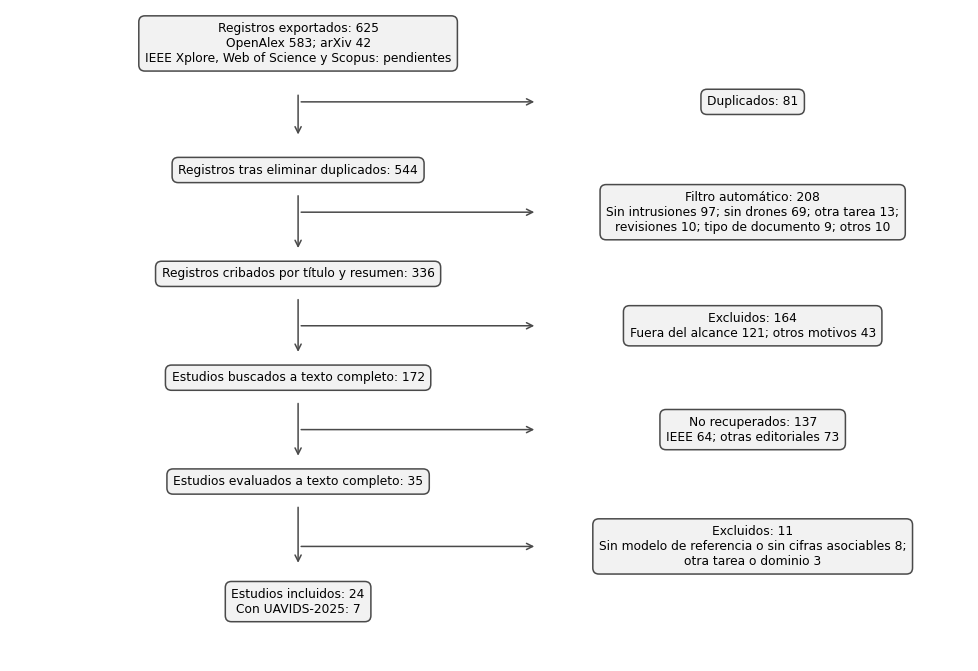

In [17]:
CONTEOS_PRISMA = {'exportados': 625, 'duplicados': 81, 'depurados': 544, 'filtro': 208, 'cribados': 336, 'excluidos_cribado': 164, 'buscados': 172, 'no_recuperados': 137, 'evaluados': 35, 'incluidos': 24, 'excluidos_texto': 11}
fig, eje = plt.subplots(figsize=(9, 6.2))
eje.axis("off")
eje.set(xlim=(0, 10), ylim=(0, 10))
c = CONTEOS_PRISMA


def caja(x, y, texto):
    eje.text(x, y, texto, ha="center", va="center", fontsize=8, bbox={"boxstyle": "round,pad=0.5", "facecolor": "#f2f2f2", "edgecolor": "#4a4a4a"})


def flecha(inicio, fin):
    eje.annotate("", xy=fin, xytext=inicio, arrowprops={"arrowstyle": "->", "color": "#4a4a4a"})


caja(3, 9.5, f"Registros exportados: {c['exportados']}\nOpenAlex 583; arXiv 42\nIEEE Xplore, Web of Science y Scopus: pendientes")
caja(3, 7.55, f"Registros tras eliminar duplicados: {c['depurados']}")
caja(3, 5.95, f"Registros cribados por título y resumen: {c['cribados']}")
caja(3, 4.35, f"Estudios buscados a texto completo: {c['buscados']}")
caja(3, 2.75, f"Estudios evaluados a texto completo: {c['evaluados']}")
caja(3, 0.9, f"Estudios incluidos: {c['incluidos']}\nCon UAVIDS-2025: 7")
caja(7.75, 8.6, f"Duplicados: {c['duplicados']}")
caja(7.75, 6.9, f"Filtro automático: {c['filtro']}\nSin intrusiones 97; sin drones 69; otra tarea 13;\nrevisiones 10; tipo de documento 9; otros 10")
caja(7.75, 5.15, f"Excluidos: {c['excluidos_cribado']}\nFuera del alcance 121; otros motivos 43")
caja(7.75, 3.55, f"No recuperados: {c['no_recuperados']}\nIEEE 64; otras editoriales 73")
caja(7.75, 1.75, f"Excluidos: {c['excluidos_texto']}\nSin modelo de referencia o sin cifras asociables 8;\notra tarea o dominio 3")
for a, b in [(8.75, 8.05), (7.2, 6.3), (5.6, 4.7), (4.0, 3.1), (2.4, 1.45)]:
    flecha((3, a), (3, b))
for y in (8.6, 6.9, 5.15, 3.55, 1.75):
    flecha((3, y), (5.5, y))
plt.tight_layout()
plt.show()

**Interpretación.** De 625 registros exportados, 81 son duplicados, el filtro automático retira 208 y el cribado por título y resumen retira 164. Quedan 172 estudios elegibles, de los cuales se pudieron evaluar 35, es decir, el 20 %, y finalmente se incluyen 24. El artículo que presenta el conjunto de datos no menciona Deep Learning en su resumen y el filtro automático lo retiró; se rescató a mano, y al no recuperarse a texto completo, sus valores se toman del repositorio de los autores.

Hay que tener en cuenta que esta cobertura introduce un sesgo: 64 de los 137 estudios no recuperados son de IEEE, y además falta consultar IEEE Xplore, Web of Science y Scopus. Por tanto, la tabla de frecuencia describe sobre todo la literatura de acceso abierto, y no se puede afirmar que represente a toda la literatura del tema.

Por lo anterior, conviene leer los conteos como una estimación de la práctica en el área y completar estas fuentes antes de cerrar la revisión.

**Quién realizó la selección.** Al ser un trabajo de autor único, hubo un solo revisor y no hubo desacuerdos que resolver, lo cual es una limitación frente a un cribado doble. El cribado y la extracción se hicieron con apoyo de un asistente de inteligencia artificial (Claude, de Anthropic) bajo la supervisión del autor. La extracción se apoyó en la búsqueda dirigida de las tablas y los pasajes de comparación de cada texto, de modo que un dato que no se halló queda como no reportado o no identificado, aunque podría estar en una figura o en un material suplementario.

**Evaluación de la calidad de los estudios.** Para cada estudio se valoró la partición, las repeticiones, la dispersión, las pruebas estadísticas y el riesgo de fuga. Ninguno de los 24 estudios agrupa filas relacionadas, 19 no reportan repeticiones, solo 2 reportan dispersión y 4 aplican alguna prueba.

| Estudio | Partición | Repeticiones | Dispersión | Prueba estadística | Riesgo de fuga | Nota |
|---|---|---|---|---|---|---|
| Abdulhammed et al. (2026) | aleatoria 80/20 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | No menciona excluir FlowID ni las IP, y un 100 % sugiere fuga |
| Aburasain (2024) | aleatoria 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Conjuntos de IoT |
| Alharthi (2024) | aleatoria 70/30 | no reportadas | no | t de Student entre los dos mejores | Alto: no agrupa filas relacionadas | Conjuntos genéricos |
| Alotaibi et al. (2024) | aleatoria 80/20 y 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Alruwaili y Tunc (2026) | aleatoria 80/20 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Preprint; conjuntos genéricos |
| Alshammari et al. (2024) | aleatoria 80/20 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Conjuntos genéricos |
| Arulalan et al. (2023) | aleatoria 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Ashraf et al. (2023) | aleatoria 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Conjunto genérico, no de drones |
| Attaullah et al. (2026) | entrenamiento y prueba, no identifica agrupación | 10 | sí | t de Student | Alto: no agrupa filas relacionadas |  |
| Babu et al. (2024) | aleatoria 80/20 y 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Repite las cifras de comparación de 10.1109/access.2024.3392618 |
| Balgoon (2026) | aleatoria estratificada, 72 % de entrenamiento | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Usa las IP como nodos del grafo |
| Cengiz et al. (2024) | 5 pliegues | 5 pliegues | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Gharami y Moni (2025) | aleatoria 80/20 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Hakeem et al. (2025) | aleatoria 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Hamad et al. (2025) | no identificada | no reportadas | no | ninguna | No evaluable | Conjunto genérico; compara con cifras publicadas |
| Katbar et al. (2024) | aleatoria 80/20 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Menssouri et al. (2024) | aleatoria | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Ozsoy et al. (2026) | aleatoria 80/20, con 176 clientes por IP de origen | no reportadas | no | ninguna sobre modelos | Alto: no agrupa filas relacionadas |  |
| SureshBabu y Geetha (2026) | no identificada | no reportadas | no | ninguna | No evaluable | Compara con cifras publicadas de otros conjuntos |
| Tan et al. (2019) | aleatoria; usa 10 % del archivo | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Conjunto genérico, no de drones |
| Wang et al. (2026) | aleatoria, con validación cruzada | 5 semillas | sí | t de Student pareada | Alto: no agrupa filas relacionadas | No menciona excluir FlowID ni las IP; sus cifras superan a las de los autores |
| Zarkadis y Douligeris (2026) | aleatoria estratificada 80/20, con 10 pliegues en entrenamiento | 10 pliegues | no | permutación sobre atributos, no sobre modelos | Alto: no agrupa filas relacionadas | Codifica las IP por frecuencia |
| Zeng et al. (2025) | aleatoria estratificada 80/20 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Valores del repositorio de los autores; el artículo no se recuperó a texto completo |
| Zhou et al. (2026) | 5 pliegues | 5 pliegues | no | ninguna | Alto: no agrupa filas relacionadas | Conjuntos genéricos |

### 3.2 Identificación de los tres modelos base de Deep Learning

**Procedimiento de extracción.** En cada estudio incluido se revisó qué modelos de Deep Learning se emplean como referencia, se registró su arquitectura y configuración cuando se reportan, y se normalizó cada modelo por familia. Con esto se construye la tabla de frecuencia, se ordenan los candidatos por frecuencia y complejidad, se seleccionan tres y se verifica que no sean redundantes.

**Tabla de síntesis.** Los valores se transcriben como los reporta cada estudio, en su propia métrica y con su propio conjunto de datos.

| Referencia | Problema | Dataset | Modelos de Deep Learning de referencia | Métricas reportadas y valores |
|---|---|---|---|---|
| Abdulhammed et al. (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 y UAV-GCS | FFN de 128 y 64, LSTM de 64 y CNN 1D (DNN/MLP; LSTM; CNN) | En UAVIDS-2025, el texto da 97,65 % de exactitud para FFN y 100 % para LightGBM |
| Aburasain (2024) | Detección de intrusiones en drones: flujos de red | ToN-IoT y Edge-IIoTset | LSTM y GRU (LSTM; GRU) | Exactitud: LSTM de 96,20 a 96,95 %, GRU de 96,00 a 96,50 % |
| Alharthi (2024) | Detección de intrusiones en drones: flujos de red | KDD Cup 99, NSL-KDD, WSN-DS y CICIDS | CNN, LSTM y CNN-LSTM (CNN; LSTM; CNN-LSTM) | Exactitud en una de las tablas: CNN 89,10 %, LSTM 92,25 %, CNN-LSTM 95,11 %; propuesto 99,99 % |
| Alotaibi et al. (2024) | Detección de intrusiones en drones: flujos de red | no identificado | IDBN y DPC-DBN (DBN) | Exactitud: IDBN 95,32 %, DPC-DBN 94,39 % |
| Alruwaili y Tunc (2026) | Detección de intrusiones en drones: flujos de red | UNSW-NB15 y Edge-IIoT | DNN, CNN 1D y CNN 1D con LSTM (DNN/MLP; CNN; CNN-LSTM) | Mejora de exactitud de 0,83 a 4,98 % en UNSW-NB15 |
| Alshammari et al. (2024) | Detección de intrusiones en drones: flujos de red | NSL-KDD y TON_IoT | LSTM-RNN y CNN (LSTM; CNN) | Exactitud en NSL-KDD: LSTM-RNN 95,91 %, CNN 86,54 %; propuesto 99,32 % |
| Arulalan et al. (2023) | Detección de intrusiones en drones: flujos de red | CICIDS2017 | CNN-LSTM, CNN y EDFFNN (CNN-LSTM; CNN; DNN/MLP) | No se pudieron asociar las cifras a cada modelo en el texto |
| Ashraf et al. (2023) | Detección de intrusiones en drones: flujos de red | CICIDS2017 y otros | RNN, LSTM y Bi-LSTM de 64 unidades, GRU y perceptrón (RNN; LSTM; BiLSTM; GRU; DNN/MLP) | Exactitud: Bi-LSTM 91,36 %, LSTM 91,00 %, RNN 90,16 %, GRU 89,13 %, perceptrón 85,02 % |
| Attaullah et al. (2026) | Detección de intrusiones en drones: datos del sistema | T-ITS, ciberfísico de UAV | DNN (DNN/MLP) | Exactitud: DNN 96,43 ± 0,22 %; propuesto 98,74 ± 0,07 % |
| Babu et al. (2024) | Detección de intrusiones en drones: flujos de red | no identificado | IDBN y DPC-DBN (DBN) | Exactitud: IDBN 95,32 %, DPC-DBN 94,39 %; propuesto 99,63 % |
| Balgoon (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 y T-ITS | BiLSTM, GNN y autoencoder (BiLSTM; GNN; Autoencoder) | F1 macro: BiLSTM 77,87 %, GNN 94,60 %; propuesto 98,18 % |
| Cengiz et al. (2024) | Detección de intrusiones en drones: datos del sistema | UAV con ataques de GPS | Red de retropropagación, con y sin una capa adicional (DNN/MLP) | Exactitud: BPN 0,895, BPN con una capa más 0,9324 |
| Gharami y Moni (2025) | Detección de intrusiones en drones: flujos de red | UAV IDS, UKM IDS y otros | MLP-AE, L-MADE y FFCNN (Autoencoder; CNN) | Exactitud en UAV IDS: FFCNN 99,99 %, MLP-AE 98,81 %; propuesto 99,99 % |
| Hakeem et al. (2025) | Detección de intrusiones en drones: datos del sistema | datos ciberfísicos de GPS | MLP, CNN, LSTM y ResNet (DNN/MLP; CNN; LSTM; ResNet) | Exactitud: ResNet 90,99 %, MLP 89,49 %, CNN 86,36 %, LSTM 82,45 % |
| Hamad et al. (2025) | Detección de intrusiones en drones: flujos de red | CIC-IDS 2017 | CNN-GRU y LSTM-CNN, tomados de trabajos publicados (CNN-LSTM; GRU) | Exactitud: CNN-GRU 98,73 %, LSTM-CNN 99,21 %; propuesto: F1 99,28 % |
| Katbar et al. (2024) | Detección de intrusiones en drones: flujos de red | no identificado | LSTM y CNN (LSTM; CNN) | Exactitud: LSTM 93 %, CNN 93 %; propuesto 95 % |
| Menssouri et al. (2024) | Detección de intrusiones en drones: flujos convertidos a matriz | UAV-IDS-2020 | CNN 1D y CNN 1D con PCA (CNN) | CNN 1D: exactitud cerca de 75 % en modo BF; propuesto 99,99 % |
| Ozsoy et al. (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 y T-ITS | MLP compacto federado; DNN, CNN y LSTM de los autores del conjunto de datos (DNN/MLP; CNN; LSTM) | F1: FedAvg 93 %, FedProx 84 %; referencias de los autores: DNN 93 %, CNN 93 %, LSTM 94 % |
| SureshBabu y Geetha (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 | ANN-GA y ConvLSTM, tomados de trabajos publicados (DNN/MLP; CNN-LSTM) | Exactitud: ANN-GA 91,8 %, ConvLSTM 95,3 %; propuesto 98,7 % |
| Tan et al. (2019) | Detección de intrusiones en drones: flujos de red | KDD Cup 99 | ANN y DNN (DNN/MLP) | Exactitud: ANN 90,79 %, DNN 91,36 %; propuesto 92,44 % |
| Wang et al. (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 | CNN, RNN, LSTM, ANN y BiLSTM (CNN; LSTM; RNN; DNN/MLP; BiLSTM) | LSTM de dos capas: F1 98,60 %; propuesto: exactitud 99,68 ± 0,12 % |
| Zarkadis y Douligeris (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 | MLP y RealMLP (DNN/MLP) | F1 de prueba: MLP 90,66 %, RealMLP 94,28 % |
| Zeng et al. (2025) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 | DNN 16-128-64-32-5 con dropout de 0,2; CNN 1D de 32 y 64 filtros; LSTM de 64 unidades (DNN/MLP; CNN; LSTM) | F1: DNN 93 %, CNN 93 %, LSTM 94 %; regresión logística 82 %, XGBoost 96 % |
| Zhou et al. (2026) | Detección de intrusiones en drones: flujos de red | ISCXVPN2016, CICIDS-2018, TON IoT y CIC IoT 2023 | CNN, LSTM, Transformer y BPNN de 512, 256 y 128 (CNN; LSTM; Transformer; DNN/MLP) | Exactitud en ISCXVPN2016: LSTM 95,9 %, CNN 94,95 % |

**Tabla de frecuencia.** Un estudio cuenta una vez por familia, aunque use varias variantes.

| Modelo | Estudios (n = 24) | % | Estudios con UAVIDS-2025 (n = 7) | % con UAVIDS-2025 |
|---|---|---|---|---|
| DNN/MLP | 14 | 58,3 | 6 | 85,7 |
| CNN | 13 | 54,2 | 4 | 57,1 |
| LSTM | 11 | 45,8 | 4 | 57,1 |
| CNN-LSTM | 5 | 20,8 | 1 | 14,3 |
| BiLSTM | 3 | 12,5 | 2 | 28,6 |
| GRU | 3 | 12,5 | 0 | 0,0 |
| RNN | 2 | 8,3 | 1 | 14,3 |
| DBN | 2 | 8,3 | 0 | 0,0 |
| Autoencoder | 2 | 8,3 | 1 | 14,3 |
| ResNet | 1 | 4,2 | 0 | 0,0 |
| Transformer | 1 | 4,2 | 0 | 0,0 |
| GNN | 1 | 4,2 | 1 | 14,3 |

**Interpretación.** La DNN o MLP es la referencia más frecuente, con 14 estudios, seguida de la CNN, con 13, y de la LSTM, con 11. El cuarto lugar, la combinación de CNN con LSTM, tiene 5 estudios, así que el corte no es ambiguo. El orden se mantiene en los 7 estudios que usan UAVIDS-2025, donde estas tres familias también son las más usadas.

Esto significa que la selección no depende de un criterio personal, porque los tres primeros lugares están claramente separados del resto. Hay que tener en cuenta que un estudio adicional de las bases pendientes puede cambiar los conteos, pero difícilmente ese corte.

Por tal motivo, se opta por estas tres familias como modelos base.

**Selección de los tres modelos.** Dentro de cada familia se toma la variante más simple con arquitectura publicada, que es la que usan los autores del conjunto de datos (Zeng et al., 2025), de modo que no aplica la búsqueda de arquitectura de la sección 14 del Entregable 2.

| Modelo | Arquitectura tomada de | Parámetros | Capas con pesos | Multiplicaciones por muestra |
|---|---|---|---|---|
| DNN | Zeng et al. (2025) | 12 677 | 4 | 12 448 |
| LSTM | Zeng et al. (2025) | 17 477 | 2 | 266 560 |
| CNN 1D | Zeng et al. (2025) | 39 493 | 4 | 132 928 |

Los parámetros y las multiplicaciones se calculan para una entrada de 16 atributos y 5 clases, y el código de la sección 4.2.1 verifica el conteo de parámetros.

**Verificación de que no son redundantes.** Los tres modelos difieren en el sesgo inductivo que incorporan. La DNN combina todos los atributos desde la primera capa, sin suponer ningún orden entre ellos. La CNN 1D busca patrones locales entre atributos vecinos y comparte pesos a lo largo del vector. La LSTM lee los atributos uno a la vez y acumula un estado. Hay que tener en cuenta que el orden de las columnas de una tabla no tiene significado físico, de modo que la CNN y la LSTM imponen una estructura que los datos no garantizan, y justamente por eso la comparación permite medir si ese supuesto ayuda o estorba. Para que sea reproducible, la secuencia sigue el orden de las columnas del archivo.

**Equivalencia con los modelos clásicos de referencia.** El enunciado asigna a estos modelos el papel que cumple el modelo logístico en clasificación, y la equivalencia se sustenta en tres aspectos. En capacidad de representación, los tres modelos terminan en una capa lineal con softmax:

$$p_\theta(c \mid x) = \frac{\exp\left(w_c^\top \phi_\theta(x)\right)}{\sum_{k=1}^{K} \exp\left(w_k^\top \phi_\theta(x)\right)}$$

Es decir, son una regresión logística multinomial sobre una representación aprendida $\phi_\theta(x)$, y si $\phi_\theta$ fuera la identidad, el modelo sería exactamente el logístico. En supuestos, el logístico supone clases separables por un hiperplano en el espacio de entrada, mientras que estos modelos solo lo suponen en el espacio de $\phi_\theta$. En propósito comparativo, ambos fijan un piso con la misma pérdida, la entropía cruzada: un modelo avanzado que no los supere no justifica su mayor complejidad.

### 3.3 Análisis detallado por modelo base

Todos los modelos comparten la pérdida, la entropía cruzada ponderada $\mathcal{L}(\theta) = -\frac{1}{n}\sum_i w_{y_i} \log p_\theta(y_i \mid x_i)$, y resuelven la clasificación multiclase de flujos de red de la sección 1. Las referencias completas de cada estudio están en la sección 9, y la configuración habitual de entrenamiento es la de Zeng et al. (2025): Adam con tasa de aprendizaje de 0,001, lotes de 256, un máximo de 50 épocas y parada temprana. La figura siguiente resume el flujo de datos de los tres modelos, que después se detalla para cada uno.

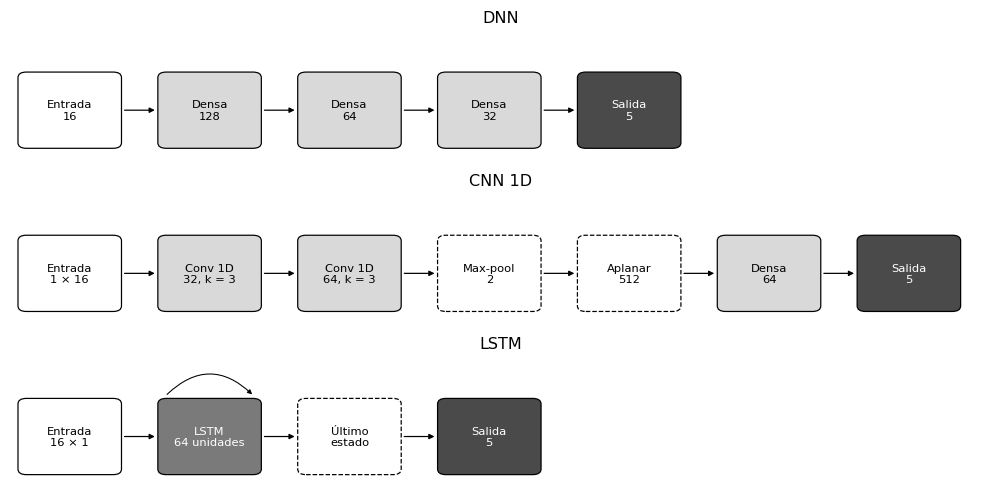

**Interpretación.** La figura muestra el flujo de datos de cada modelo, de izquierda a derecha. Los bloques claros son capas con pesos, el de gris medio es la capa recurrente, con su lazo arriba, los punteados no tienen pesos, y los oscuros son la capa de salida. La DNN recibe el vector completo, la CNN 1D lo recorre con filtros de tamaño 3 y la LSTM lo lee como una secuencia de 16 pasos.

Esto significa que los tres modelos difieren en cómo combinan los atributos, y no solo en su número de parámetros: la DNN no supone ningún orden, mientras que la CNN 1D y la LSTM dependen del orden de las columnas.

Por tal motivo, se conservan estas tres arquitecturas como base, porque sus diferencias responden a supuestos distintos.

In [18]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

BLOQUES = {"DNN": [("Entrada\n16", "entrada"), ("Densa\n128", "densa"), ("Densa\n64", "densa"), ("Densa\n32", "densa"), ("Salida\n5", "salida")],
           "CNN 1D": [("Entrada\n1 × 16", "entrada"), ("Conv 1D\n32, k = 3", "conv"), ("Conv 1D\n64, k = 3", "conv"), ("Max-pool\n2", "resumen"), ("Aplanar\n512", "resumen"), ("Densa\n64", "densa"), ("Salida\n5", "salida")],
           "LSTM": [("Entrada\n16 × 1", "entrada"), ("LSTM\n64 unidades", "recurrente"), ("Último\nestado", "resumen"), ("Salida\n5", "salida")]}
ESTILO_BLOQUE = {"entrada": ("white", NEGRO, "-"), "conv": (GRIS_CLARO, NEGRO, "-"), "recurrente": (GRIS_MEDIO, "white", "-"), "resumen": ("white", NEGRO, "--"), "densa": (GRIS_CLARO, NEGRO, "-"), "salida": (GRIS_OSCURO, "white", "-")}
fig, ejes = plt.subplots(len(BLOQUES), 1, figsize=(9.2, 4.6))
for eje, (nombre, capas_modelo) in zip(ejes, BLOQUES.items()):
    for i, (texto, tipo) in enumerate(capas_modelo):
        fondo, letra, linea = ESTILO_BLOQUE[tipo]
        eje.add_patch(FancyBboxPatch((i + 0.06, 0.1), 0.72, 0.8, boxstyle="round,pad=0.01,rounding_size=0.06", facecolor=fondo, edgecolor=NEGRO, linestyle=linea, linewidth=0.8))
        eje.text(i + 0.42, 0.5, texto, ha="center", va="center", fontsize=7.5, color=letra)
        if i < len(capas_modelo) - 1:
            eje.add_patch(FancyArrowPatch((i + 0.79, 0.5), (i + 1.05, 0.5), arrowstyle="-|>", mutation_scale=7, color=NEGRO, linewidth=0.8))
        if tipo == "recurrente":
            eje.add_patch(FancyArrowPatch((i + 0.1, 0.93), (i + 0.74, 0.93), connectionstyle="arc3,rad=-0.5", arrowstyle="-|>", mutation_scale=6, color=NEGRO, linewidth=0.7))
    eje.set(xlim=(0, 7), ylim=(0, 1.35), xticks=[], yticks=[], title=nombre)
    eje.set_frame_on(False)
    eje.grid(False)
plt.tight_layout()
plt.show()
interpretar('''**Interpretación.** La figura muestra el flujo de datos de cada modelo, de izquierda a derecha. Los bloques claros son capas con pesos, el de gris medio es la capa recurrente, con su lazo arriba, los punteados no tienen pesos, y los oscuros son la capa de salida. La DNN recibe el vector completo, la CNN 1D lo recorre con filtros de tamaño 3 y la LSTM lo lee como una secuencia de 16 pasos.

Esto significa que los tres modelos difieren en cómo combinan los atributos, y no solo en su número de parámetros: la DNN no supone ningún orden, mientras que la CNN 1D y la LSTM dependen del orden de las columnas.

Por tal motivo, se conservan estas tres arquitecturas como base, porque sus diferencias responden a supuestos distintos.''')

#### Modelo 1: DNN

- **Tipo de arquitectura.** Perceptrón multicapa.
- **Referencias que la respaldan.** Abdulhammed et al. (2026), <https://doi.org/10.70102/afts.2026.1836.229>, Alruwaili y Tunc (2026), <https://doi.org/10.48550/arxiv.2607.17025>, Arulalan et al. (2023), <https://doi.org/10.17762/ijritcc.v11i9.8338>, Ashraf et al. (2023), <https://doi.org/10.1038/s41598-023-45065-8>, Attaullah et al. (2026), <https://doi.org/10.1038/s41598-026-55446-4>, Cengiz et al. (2024), <https://doi.org/10.1109/access.2024.3349469>, Hakeem et al. (2025), <https://doi.org/10.3389/fcomp.2025.1545282>, Ozsoy et al. (2026), <https://doi.org/10.47000/tjmcs.1828534>, SureshBabu y Geetha (2026), <https://indianengineeringjournal.com/index.php/journal/article/view/270>, Tan et al. (2019), <https://doi.org/10.3390/s19245529>, Wang et al. (2026), <https://doi.org/10.1038/s41598-026-52524-5>, Zarkadis y Douligeris (2026), <https://doi.org/10.1109/cits70307.2026.11637173>, Zeng et al. (2025), <https://doi.org/10.1109/cns66487.2025.11194990>, Zhou et al. (2026), <https://doi.org/10.3389/fphy.2025.1660104>. La arquitectura exacta se toma de Zeng et al. (2025).

- **Descripción técnica.** Cada capa oculta aplica $z^{(l)} = \mathrm{Dropout}\big(\mathrm{ReLU}(W^{(l)} z^{(l-1)} + b^{(l)})\big)$, con *dropout* de 0,2. El flujo de datos es 16 → 128 → 64 → 32 → 5, y la capa de salida aplica softmax.
- **Supuestos y sesgo inductivo.** Supone que la clase depende de interacciones globales entre atributos, sin ninguna estructura local, lo cual es coherente con una tabla donde el orden de las columnas no tiene significado.
- **Tipo de problema que aborda.** Clasificación multiclase de flujos de red en los estudios revisados.
- **Datasets y métricas reportadas.** F1 de 93 % en UAVIDS-2025, sin dispersión (Zeng et al., 2025); F1 de 90,66 % en UAVIDS-2025, sin dispersión (Zarkadis y Douligeris, 2026); exactitud de 96,43 ± 0,22 % en T-ITS, con dispersión sobre 10 ejecuciones (Attaullah et al., 2026), y 91,36 % en KDD Cup 99, sin dispersión (Tan et al., 2019).
- **Fortalezas.** Es el modelo más simple y barato de los tres, fácil de reproducir y el más usado como referencia.
- **Limitaciones.** No aprovecha ninguna estructura de los datos y su capacidad depende del ancho, de modo que necesita regularización y es sensible a la tasa de aprendizaje.
- **Complejidad computacional.** Con $c = (16, 128, 64, 32, 5)$, el número de parámetros es $P = \sum_{l=1}^{4}(c_{l-1} + 1)c_l = 12\,677$. El costo por muestra es de orden $\mathcal{O}(\sum_l c_{l-1} c_l)$, unas 12 448 multiplicaciones; la inferencia requiere una pasada y el paso de entrenamiento agrega la retropropagación, del mismo orden. Los estudios no reportan un tiempo de entrenamiento comparable, por lo que se mide en la sección 4.2.1.

#### Modelo 2: CNN 1D

- **Tipo de arquitectura.** Red convolucional unidimensional poco profunda.

- **Referencias que la respaldan.** Abdulhammed et al. (2026), <https://doi.org/10.70102/afts.2026.1836.229>, Alharthi (2024), <https://doi.org/10.3389/fenrg.2024.1491332>, Alruwaili y Tunc (2026), <https://doi.org/10.48550/arxiv.2607.17025>, Alshammari et al. (2024), <https://doi.org/10.3934/math.2024348>, Arulalan et al. (2023), <https://doi.org/10.17762/ijritcc.v11i9.8338>, Gharami y Moni (2025), <https://doi.org/10.1109/dasc66011.2025.11257309>, Hakeem et al. (2025), <https://doi.org/10.3389/fcomp.2025.1545282>, Katbar et al. (2024), <https://doi.org/10.7546/crabs.2024.08.09>, Menssouri et al. (2024), <https://doi.org/10.1109/pimrc59610.2024.10817244>, Ozsoy et al. (2026), <https://doi.org/10.47000/tjmcs.1828534>, Wang et al. (2026), <https://doi.org/10.1038/s41598-026-52524-5>, Zeng et al. (2025), <https://doi.org/10.1109/cns66487.2025.11194990>, Zhou et al. (2026), <https://doi.org/10.3389/fphy.2025.1660104>. La arquitectura exacta se toma de Zeng et al. (2025).

- **Descripción técnica.** Cada convolución aplica $z^{(l)} = \mathrm{ReLU}(W^{(l)} * z^{(l-1)} + b^{(l)})$, con filtros de tamaño 3. El flujo de datos es 1 × 16 → 32 filtros → 64 filtros → reducción a 8 posiciones → aplanado de 512 → 64 → 5.
- **Supuestos y sesgo inductivo.** Supone que la información discriminante es local y puede aparecer en varias posiciones. En una tabla, ese supuesto depende del orden de las columnas, que aquí es el del archivo, por lo que se trata de un sesgo discutible.
- **Tipo de problema que aborda.** Clasificación multiclase de flujos de red en los estudios revisados.
- **Datasets y métricas reportadas.** F1 de 93 % en UAVIDS-2025, sin dispersión (Zeng et al., 2025); exactitud de 89,10 % en una de las tablas de Alharthi (2024), sin dispersión; 93 % (Katbar et al., 2024), sin dispersión, y 86,54 % en NSL-KDD, sin dispersión (Alshammari et al., 2024).
- **Fortalezas.** Comparte pesos a lo largo del vector, de modo que tiene pocos parámetros por capa convolucional, y es fácil de reproducir.
- **Limitaciones.** Es sensible al orden de los atributos, y la capa densa posterior al aplanado concentra 32 832 de sus 39 493 parámetros, el 83 %.
- **Complejidad computacional.** El número de parámetros es $P = (3 \cdot 1 + 1) \cdot 32 + (3 \cdot 32 + 1) \cdot 64 + (64 \cdot 8 + 1) \cdot 64 + (64 + 1) \cdot 5 = 39\,493$. El costo por muestra es de orden $\mathcal{O}(\sum_l L\, k\, c_{l-1} c_l)$, con $L = 16$ y $k = 3$, unas 132 928 multiplicaciones. Los estudios no reportan un tiempo de entrenamiento comparable, por lo que se mide en la sección 4.2.1.

#### Modelo 3: LSTM

- **Tipo de arquitectura.** Red recurrente de una capa (Hochreiter y Schmidhuber, 1997).

- **Referencias que la respaldan.** Abdulhammed et al. (2026), <https://doi.org/10.70102/afts.2026.1836.229>, Aburasain (2024), <https://doi.org/10.1109/access.2024.3359043>, Alharthi (2024), <https://doi.org/10.3389/fenrg.2024.1491332>, Alshammari et al. (2024), <https://doi.org/10.3934/math.2024348>, Ashraf et al. (2023), <https://doi.org/10.1038/s41598-023-45065-8>, Hakeem et al. (2025), <https://doi.org/10.3389/fcomp.2025.1545282>, Katbar et al. (2024), <https://doi.org/10.7546/crabs.2024.08.09>, Ozsoy et al. (2026), <https://doi.org/10.47000/tjmcs.1828534>, Wang et al. (2026), <https://doi.org/10.1038/s41598-026-52524-5>, Zeng et al. (2025), <https://doi.org/10.1109/cns66487.2025.11194990>, Zhou et al. (2026), <https://doi.org/10.3389/fphy.2025.1660104>. La arquitectura exacta se toma de Zeng et al. (2025).

- **Descripción técnica.** En cada paso $t$, la celda calcula las compuertas $f_t, i_t, o_t = \sigma(W h_{t-1} + V x_t + b)$, actualiza la memoria con $C_t = f_t \odot C_{t-1} + i_t \odot \tanh(W_c h_{t-1} + V_c x_t + b_c)$ y emite $h_t = o_t \odot \tanh(C_t)$. El flujo de datos es una secuencia de 16 pasos de un valor, 64 unidades, último estado y 5 salidas.
- **Supuestos y sesgo inductivo.** Supone que los elementos forman una secuencia con dependencias a lo largo de los pasos. Esto tiene sentido en series de tiempo, pero aquí los pasos son columnas de una tabla y no instantes, de modo que el sesgo no corresponde a la naturaleza de los datos.
- **Tipo de problema que aborda.** Clasificación multiclase de flujos de red en los estudios revisados.
- **Datasets y métricas reportadas.** F1 de 94 % en UAVIDS-2025, sin dispersión (Zeng et al., 2025); F1 de 98,60 % en UAVIDS-2025, sin dispersión para ese modelo (Wang et al., 2026); exactitud de 91,00 % en CICIDS2017, sin dispersión (Ashraf et al., 2023), y 95,91 % en NSL-KDD, sin dispersión (Alshammari et al., 2024).
- **Fortalezas.** Tiene pocos parámetros y gestiona el flujo del gradiente con sus compuertas.
- **Limitaciones.** Es la más costosa de las tres por muestra, porque repite el cálculo en cada paso, depende del orden de las columnas y no se puede paralelizar a lo largo de la secuencia.
- **Complejidad computacional.** Con entrada de dimensión 1 y $h = 64$ unidades, el número de parámetros es $P = 4\,[(1 + h)\,h + 2h] + (h + 1) \cdot 5 = 17\,477$, porque cada una de las cuatro compuertas tiene dos vectores de sesgo. El costo por muestra es de orden $\mathcal{O}(T\, h^2)$, con $T = 16$, unas 266 560 multiplicaciones. Los estudios no reportan un tiempo de entrenamiento comparable, por lo que se mide en la sección 4.2.1.

### 3.4 Comparación crítica

**Comparación estructurada.** La tabla resume los tres modelos con los valores de la sección 3.3, sin promediarlos, porque provienen de conjuntos de datos y protocolos distintos.

| Criterio | DNN | CNN 1D | LSTM |
|---|---|---|---|
| Desempeño en UAVIDS-2025, repositorio de los autores (F1) | 93 % | 93 % | 94 % |
| Robustez | Sin dependencia del orden de las columnas | Depende del orden de las columnas | Depende del orden de las columnas |
| Escalabilidad | Costo lineal en la dimensión de cada capa | Costo lineal en el número de atributos | Costo lineal en el número de pasos, sin paralelizar |
| Parámetros | 12 677 | 39 493 | 17 477 |

**Validez de los estudios revisados.** Ninguno de los 24 estudios agrupa filas relacionadas al partir los datos; 2 no permiten identificar la partición, 19 no reportan repeticiones, solo 2 reportan dispersión y 4 aplican alguna prueba, de las cuales tres comparan modelos, con la prueba $t$, y ninguna sobre particiones agrupadas. Además, la comparabilidad es baja: varios estudios usan conjuntos genéricos, como KDD Cup 99 o CICIDS2017, que no provienen de redes de drones, y dos estudios sobre IoT repiten las mismas cifras de comparación. Dos resultados merecen una alerta: Abdulhammed et al. (2026) reportan 100 % con LightGBM, y Wang et al. (2026) reportan 99,68 %, en ambos casos sin mencionar la exclusión de `FlowID` ni de las direcciones IP, que la sección 2.1.4 identifica como atajos.

**Brecha de desempeño.** La literatura reporta que los modelos propuestos superan a estas referencias, como 98,74 % frente a 96,43 % de la DNN (Attaullah et al., 2026), o 98,18 % frente a 94,60 % de una GNN en UAVIDS-2025 (Balgoon, 2026). Sin embargo, esa brecha se obtiene con particiones aleatorias, y la sección 2.1.3 mostró que cambiar a una partición agrupada mueve el F1 macro en una magnitud parecida o mayor. Por tanto, esta brecha se toma como contexto para interpretar el baseline, y no como una mejora demostrada.

**Vacío en la literatura.** Ninguno de los 24 estudios incluidos, y en particular ninguno de los 7 que usan UAVIDS-2025, compara modelos base de Deep Learning con una partición que respete la dependencia entre flujos contiguos y con inferencia estadística sobre repeticiones. Este trabajo atiende ese vacío, con la salvedad de que la revisión aún no incluye las bases de datos pendientes.

## 4. Implementación y evaluación de los tres modelos base

En esta sección se implementan los tres modelos bajo un mismo entorno experimental y se evalúan con el mismo protocolo, en el orden del enunciado: diseño experimental (sección 4.1), implementación (sección 4.2), requisitos experimentales (sección 4.3) y evaluación (sección 4.4). Lo que ya está guardado se salta, de modo que basta con volver a ejecutar si la corrida se interrumpe.

In [19]:
import platform

from scipy.stats import rankdata, studentized_range
from sklearn.metrics import accuracy_score, average_precision_score, balanced_accuracy_score, confusion_matrix, f1_score, matthews_corrcoef, precision_score, recall_score, roc_auc_score
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.power import TTestPower
from torch import nn

# Interruptores de cada fase: se activan en orden, cuando la fase anterior ya se revisó
CORRER_BUSQUEDA = True
CORRER_PILOTO = True
CORRER_DEFINITIVA = True

CORRIDAS = RESULTADOS / "corridas"
CORRIDAS.mkdir(parents=True, exist_ok=True)
preparados = np.load(RESULTADOS / "datos_preparados.npz")
particion = np.load(RESULTADOS / "particion.npz")
y_np = preparados["y"]
X = torch.from_numpy(preparados["X"])
Y = torch.from_numpy(y_np).long()
id_ent, id_val, id_pru = (torch.from_numpy(particion[n]) for n in ("entrenamiento", "validacion", "prueba"))
PESOS = torch.from_numpy(preparados["pesos"])
dispositivo = torch.device("cpu")
N_ATRIBUTOS, N_CLASES = X.shape[1], len(CLASES)
print(f"Entrada: {N_ATRIBUTOS} atributos | clases: {N_CLASES} | entrenamiento {len(id_ent):,} | validación {len(id_val):,} | prueba {len(id_pru):,} | {torch.get_num_threads()} hilos de CPU")

Entrada: 16 atributos | clases: 5 | entrenamiento 73,267 | validación 17,802 | prueba 22,883 | 10 hilos de CPU


### 4.1 Diseño experimental

En esta subsección se define el protocolo antes de entrenar, para que los tres modelos se comparen bajo las mismas condiciones y nada dependa de los resultados.

| Elemento | Definición |
|---|---|
| Variables de entrada | Vector de 16 atributos de tráfico y desempeño, recortado, transformado con $\log(1 + x)$ y estandarizado (secciones 2.2.1 y 2.2.5) |
| Variable objetivo | Una de las 5 clases del espacio $\mathcal{Y}$ (sección 1.1); no hay horizonte de predicción, porque cada flujo se clasifica por sí solo |
| División del dataset | Entrenamiento, validación y prueba de 64, 16 y 20 %, con semilla 42, y prueba congelada con su suma SHA-256; la estrategia se justifica en la sección 2.1.3 |
| Esquema de validación | Partición fija de validación, agrupada por bloques, para seleccionar hiperparámetros, porque hay decenas de miles de flujos y una validación anidada multiplicaría los entrenamientos sin cambiar la comparación |
| Preprocesamiento | Eliminación de filas repetidas y transformación con los estadísticos de entrenamiento, sin aumento de datos (secciones 2.1.2 y 2.2.1) |
| Entrenamiento | Mismo motor, pérdida y optimizador para los tres modelos (sección 4.2.2), con el mismo esfuerzo de ajuste (sección 4.2.3) |
| Evaluación | Mismas métricas sobre el mismo conjunto de prueba, evaluado una sola vez por corrida con el modelo ya fijado (sección 4.4) |

**Estudio piloto y dimensionamiento.** Antes de la ejecución definitiva, cinco ejecuciones por modelo estiman la variabilidad del F1 macro y fijan el número de ejecuciones. Se ejecuta en la sección 4.3.1 y no aquí, porque necesita los modelos y los hiperparámetros de la sección 4.2.

### 4.2 Implementación de los tres modelos base

Los modelos son los que resultan de la tabla de frecuencia de la literatura (sección 3.2), y se implementan con PyTorch, cuya versión se registra en la configuración del entorno. Todos tienen la arquitectura definida por Zeng et al. (2025), de modo que no aplica la búsqueda de arquitectura de la sección 14 del Entregable 2:

| Modelo | Origen de la arquitectura | Adaptación a estos datos |
|---|---|---|
| DNN | Zeng et al. (2025): perceptrón de 16 → 128 → 64 → 32 → 5, con ReLU y *dropout* de 0,2 | Ninguna |
| CNN 1D | Zeng et al. (2025): convoluciones 1D de 32 y 64 filtros de tamaño 3, *max-pooling* y capa densa de 64 | Ninguna |
| LSTM | Zeng et al. (2025): una capa de 64 unidades que lee los 16 atributos como una secuencia de largo 16 | Ninguna |

#### 4.2.1 Modelos y costo de entrenamiento

Antes de dimensionar los experimentos se mide la velocidad real de cada modelo en este equipo.

In [20]:
class DNN(nn.Module):
    def __init__(self, dropout=0.2):
        super().__init__()
        capas, entrada = [], N_ATRIBUTOS
        for ancho in (128, 64, 32):
            capas += [nn.Linear(entrada, ancho), nn.ReLU(), nn.Dropout(dropout)]
            entrada = ancho
        self.red = nn.Sequential(*capas, nn.Linear(entrada, N_CLASES))

    def forward(self, x):
        return self.red(x)


class CNN1D(nn.Module):
    def __init__(self):
        super().__init__()
        self.convoluciones = nn.Sequential(nn.Conv1d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv1d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool1d(2))
        self.densas = nn.Sequential(nn.Flatten(), nn.Linear(64 * (N_ATRIBUTOS // 2), 64), nn.ReLU(), nn.Linear(64, N_CLASES))

    def forward(self, x):
        return self.densas(self.convoluciones(x.unsqueeze(1)))


class LSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 64, batch_first=True)
        self.salida = nn.Linear(64, N_CLASES)

    def forward(self, x):
        return self.salida(self.lstm(x.unsqueeze(-1))[1][0][-1])


MODELOS = {"DNN": DNN, "CNN 1D": CNN1D, "LSTM": LSTM}
# Verificación de las expresiones analíticas de la sección 3.3
assert sum(p.numel() for p in DNN().parameters()) == (16 + 1) * 128 + (128 + 1) * 64 + (64 + 1) * 32 + (32 + 1) * 5 == 12677
assert sum(p.numel() for p in CNN1D().parameters()) == (3 * 1 + 1) * 32 + (3 * 32 + 1) * 64 + (64 * 8 + 1) * 64 + (64 + 1) * 5 == 39493
assert sum(p.numel() for p in LSTM().parameters()) == 4 * ((1 + 64) * 64 + 2 * 64) + (64 + 1) * 5 == 17477


def medir(constructor, segundos=8, lote=256):
    modelo = constructor().to(dispositivo).train()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    perdida = nn.CrossEntropyLoss(weight=PESOS)
    bloques = id_ent[torch.randperm(len(id_ent))[:lote * 400]].split(lote)
    inicio, muestras, parametros = time.time(), 0, sum(p.numel() for p in modelo.parameters())
    for bloque in bloques:
        optimizador.zero_grad(set_to_none=True)
        perdida(modelo(X[bloque]), Y[bloque]).backward()
        optimizador.step()
        muestras += len(bloque)
        if time.time() - inicio > segundos:
            break
    velocidad = muestras / (time.time() - inicio)
    return {"Parámetros": parametros, "Muestras por segundo": round(velocidad), "Segundos por época": round(len(id_ent) / velocidad, 1)}


RUTA_COSTO = RESULTADOS / "costo.json"
if RUTA_COSTO.exists():
    costo = json.loads(RUTA_COSTO.read_text())
else:
    costo = {nombre: medir(c) for nombre, c in MODELOS.items()}
    RUTA_COSTO.write_text(json.dumps(costo, indent=1))
display(pd.DataFrame(costo).T)

# Peor caso de cómputo: todas las corridas llegan al máximo de épocas
MAX_EPOCAS = 50
PRESUPUESTO_FASES = {"Búsqueda (6 configuraciones, 15 épocas)": 6 * 15, "Piloto (5 semillas, 50 épocas)": 5 * MAX_EPOCAS, "Definitiva (12 semillas, 50 épocas)": 12 * MAX_EPOCAS}
horas = pd.DataFrame({nombre: {fase: epocas * c["Segundos por época"] / 3600 for fase, epocas in PRESUPUESTO_FASES.items()} for nombre, c in costo.items()})
horas["Total"] = horas.sum(axis=1)
horas.loc["Total"] = horas.sum()
display(horas.round(2))
total_horas = float(horas.loc["Total", "Total"])
modelo_caro = max(costo, key=lambda n: costo[n]["Segundos por época"])
interpretar(f'''**Interpretación.** {modelo_caro} es el modelo más costoso, con {num(costo[modelo_caro]["Segundos por época"], 1)} segundos por época en CPU, y el total en el peor caso, con todas las corridas hasta el máximo de épocas, es de {num(total_horas, 1)} horas.

Esto significa que es un límite superior, porque la parada temprana lo reduce, y que el costo no restringe el número de ejecuciones que pida el estudio piloto.

Por lo anterior, se conserva este presupuesto, y cada corrida se guarda al terminar, de modo que una interrupción no obligue a repetir lo ya hecho.''')

,Parámetros,Muestras por segundo,Segundos por época
DNN,12677.0,33676.0,2.2
CNN 1D,39493.0,16629.0,4.4
LSTM,17477.0,10091.0,7.3


,DNN,CNN 1D,LSTM,Total
"Búsqueda (6 configuraciones, 15 épocas)",0.06,0.11,0.18,0.35
"Piloto (5 semillas, 50 épocas)",0.15,0.31,0.51,0.97
"Definitiva (12 semillas, 50 épocas)",0.37,0.73,1.22,2.32
Total,0.57,1.15,1.91,3.63


**Interpretación.** LSTM es el modelo más costoso, con 7,3 segundos por época en CPU, y el total en el peor caso, con todas las corridas hasta el máximo de épocas, es de 3,6 horas.

Esto significa que es un límite superior, porque la parada temprana lo reduce, y que el costo no restringe el número de ejecuciones que pida el estudio piloto.

Por lo anterior, se conserva este presupuesto, y cada corrida se guarda al terminar, de modo que una interrupción no obligue a repetir lo ya hecho.

#### 4.2.2 Motor de entrenamiento e hiperparámetros

Todos los modelos se entrenan con la misma función: entropía cruzada ponderada, Adam, como en Zeng et al. (2025), reducción de la tasa de aprendizaje por 10 si la pérdida de validación no mejora en 2 épocas y parada temprana sobre el F1 macro de validación. El conjunto de prueba solo se evalúa en la fase definitiva, una vez por corrida, con el modelo ya fijado. Se fijan las semillas de Python, NumPy y PyTorch, sin determinismo estricto, porque no se usa aleatoriedad del dispositivo más allá de la de PyTorch en CPU. La tabla que sigue a la celda reúne estas definiciones.

In [21]:
PACIENCIA = 6


def fijar_semilla(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)


def predecir(modelo, indices, lote=4096):
    modelo.eval()
    with torch.no_grad():
        return torch.cat([modelo(X[bloque]) for bloque in indices.split(lote)])


def entrenar(nombre, hp, semilla, ids_ent, ids_val, max_epocas=MAX_EPOCAS, paciencia=PACIENCIA):
    fijar_semilla(semilla)
    modelo = MODELOS[nombre]().to(dispositivo)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])
    planificador = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, factor=0.1, patience=2)
    perdida = nn.CrossEntropyLoss(weight=PESOS)
    generador = torch.Generator().manual_seed(semilla)
    mejor, mejor_estado, sin_mejora, curvas = -1.0, None, 0, []
    for epoca in range(1, max_epocas + 1):
        inicio = time.time()
        modelo.train()
        acumulado, n = 0.0, 0
        for bloque in ids_ent[torch.randperm(len(ids_ent), generator=generador)].split(hp["batch"]):
            if len(bloque) < 2:
                continue
            optimizador.zero_grad(set_to_none=True)
            valor = perdida(modelo(X[bloque]), Y[bloque])
            valor.backward()
            optimizador.step()
            acumulado += valor.item() * len(bloque)
            n += len(bloque)
        logits = predecir(modelo, ids_val)
        perdida_val = perdida(logits, Y[ids_val]).item()
        f1_val = f1_score(Y[ids_val].numpy(), logits.argmax(1).numpy(), average="macro", zero_division=0)
        planificador.step(perdida_val)
        curvas.append({"epoca": epoca, "perdida_ent": acumulado / max(n, 1), "perdida_val": perdida_val, "f1_val": f1_val,
                       "lr": optimizador.param_groups[0]["lr"], "segundos": round(time.time() - inicio, 2)})
        if f1_val > mejor:
            mejor, sin_mejora = f1_val, 0
            mejor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(mejor_estado)
    return modelo, curvas


def correr(fase, nombre, hp, semilla, ids_ent, ids_val, etiqueta="", evaluar_prueba=False, guardar_pesos=False, **opciones):
    ruta = CORRIDAS / f"{fase}_{nombre.replace(' ', '_')}_{semilla}{etiqueta}.json"
    if ruta.exists():
        return json.loads(ruta.read_text(encoding="utf-8"))
    inicio = time.time()
    modelo, curvas = entrenar(nombre, hp, semilla, ids_ent, ids_val, **opciones)
    pred_val = predecir(modelo, ids_val).argmax(1).numpy()
    y_val = Y[ids_val].numpy()
    registro = {"fase": fase, "modelo": nombre, "semilla": semilla, "hp": hp, "curvas": curvas, "segundos": round(time.time() - inicio, 1),
                "epocas": len(curvas), "parametros": sum(p.numel() for p in modelo.parameters()),
                "f1_val": f1_score(y_val, pred_val, average="macro", zero_division=0), "bacc_val": balanced_accuracy_score(y_val, pred_val),
                "acc_val": accuracy_score(y_val, pred_val), "dispositivo": f"CPU, {torch.get_num_threads()} hilos, {platform.processor()}"}
    muestra_ent = ids_ent[torch.randperm(len(ids_ent))[:len(ids_val)]]
    registro["f1_ent"] = f1_score(Y[muestra_ent].numpy(), predecir(modelo, muestra_ent).argmax(1).numpy(), average="macro", zero_division=0)
    if guardar_pesos:
        torch.save(modelo.state_dict(), ruta.with_suffix(".pt"))
    if evaluar_prueba:
        inicio_prueba = time.time()
        probabilidades = torch.softmax(predecir(modelo, id_pru), 1).numpy()
        registro["ms_por_muestra"] = round(1000 * (time.time() - inicio_prueba) / len(id_pru), 5)
        np.save(ruta.with_suffix(".npy"), probabilidades.astype(np.float32))
    temporal = ruta.with_suffix(".tmp")
    temporal.write_text(json.dumps(registro, ensure_ascii=False), encoding="utf-8")
    temporal.replace(ruta)
    print(f"{fase} | {nombre} | semilla {semilla}{etiqueta} | F1 macro de validación {registro['f1_val']:.4f} | {registro['epocas']} épocas | {registro['segundos'] / 60:.1f} min", flush=True)
    return registro


display(pd.DataFrame({"Definición": ["Capas y unidades", "Función de pérdida", "Optimizador", "Tasa de aprendizaje", "Planificador", "Decaimiento de pesos", "Tamaño de lote", "Dropout", "Máximo de épocas", "Parada temprana", "Registro de cada corrida"],
                      "Valor": ["Las de la sección 3.3", "Entropía cruzada ponderada", "Adam", "Se ajusta en la sección 4.2.3", "Reducción por 10 si la pérdida de validación no mejora en 2 épocas", "Se ajusta en la sección 4.2.3", "Se ajusta en la sección 4.2.3",
                                "0,2 en la DNN; las otras dos arquitecturas no lo usan", MAX_EPOCAS, f"Paciencia de {PACIENCIA} épocas sobre el F1 macro de validación", "Curvas, parámetros, semilla, hiperparámetros, tiempo y equipo"]}).style.hide(axis="index"))

Definición,Valor
Capas y unidades,Las de la sección 3.3
Función de pérdida,Entropía cruzada ponderada
Optimizador,Adam
Tasa de aprendizaje,Se ajusta en la sección 4.2.3
Planificador,Reducción por 10 si la pérdida de validación no mejora en 2 épocas
Decaimiento de pesos,Se ajusta en la sección 4.2.3
Tamaño de lote,Se ajusta en la sección 4.2.3
Dropout,"0,2 en la DNN; las otras dos arquitecturas no lo usan"
Máximo de épocas,50
Parada temprana,Paciencia de 6 épocas sobre el F1 macro de validación


#### 4.2.3 Ajuste de hiperparámetros con el mismo esfuerzo

Para que el baseline no quede subestimado, los tres modelos reciben exactamente el mismo presupuesto: las mismas configuraciones del mismo espacio, sobre todo el conjunto de entrenamiento y con un máximo de 15 épocas. La arquitectura no se ajusta, porque viene definida por la literatura.

In [22]:
ESPACIO = {"lr": [0.0001, 0.0005, 0.001], "weight_decay": [0.0, 1e-4], "batch": [128, 256]}
N_CONFIGURACIONES = 6
SEMILLA_BUSQUEDA = 42
rng_busqueda = random.Random(SEMILLA_BUSQUEDA)
todas = [{"lr": a, "weight_decay": b, "batch": c} for a in ESPACIO["lr"] for b in ESPACIO["weight_decay"] for c in ESPACIO["batch"]]
CONFIGURACIONES = rng_busqueda.sample(todas, N_CONFIGURACIONES)
RUTA_HP = RESULTADOS / "mejores_hiperparametros.json"

if CORRER_BUSQUEDA:
    filas = []
    for nombre in MODELOS:
        for n_conf, hp in enumerate(CONFIGURACIONES):
            r = correr("busqueda", nombre, hp, SEMILLA_BUSQUEDA, id_ent, id_val, etiqueta=f"_c{n_conf}", max_epocas=15, paciencia=15)
            filas.append({"Modelo": nombre, **hp, "F1 macro de validación": r["f1_val"], "Minutos": r["segundos"] / 60})
    busqueda = pd.DataFrame(filas)
    display(busqueda.round(4))
    mejores = {n: {k: v for k, v in zip(["lr", "weight_decay", "batch"], g.sort_values("F1 macro de validación", ascending=False).iloc[0][["lr", "weight_decay", "batch"]].tolist())} for n, g in busqueda.groupby("Modelo")}
    mejores = {n: {"lr": float(h["lr"]), "weight_decay": float(h["weight_decay"]), "batch": int(h["batch"])} for n, h in mejores.items()}
    RUTA_HP.write_text(json.dumps(mejores, indent=1))
if RUTA_HP.exists():
    display(pd.DataFrame(json.loads(RUTA_HP.read_text())).T)
    guardadas_busqueda = [json.loads(r.read_text(encoding="utf-8")) for r in CORRIDAS.glob("busqueda_*.json")]
    tabla_busqueda = pd.DataFrame([{"Modelo": r["modelo"], "F1": r["f1_val"]} for r in guardadas_busqueda]).groupby("Modelo")["F1"].agg(["max", "min"])
    tabla_busqueda["Rango"] = tabla_busqueda["max"] - tabla_busqueda["min"]
    display(tabla_busqueda.round(4))
    sensible = tabla_busqueda["Rango"].idxmax()
    display(Markdown(f'''**Interpretación.** La tabla resume, para cada modelo, el mejor y el peor F1 macro de validación entre las mismas {N_CONFIGURACIONES} configuraciones. {sensible} es el más sensible a los hiperparámetros, con un rango de {num(tabla_busqueda.loc[sensible, "Rango"], 3)}. Es decir, sin ajuste su desempeño podría subestimarse en esa magnitud, lo que justifica dar a todos el mismo esfuerzo de optimización.

Hay que tener en cuenta que esta búsqueda usa una sola semilla y 15 épocas, de modo que ordena configuraciones, pero sus valores no estiman el desempeño final. Por ello, ninguna conclusión sobre qué modelo es mejor se apoya en esta tabla.'''))
else:
    print("Búsqueda pendiente: aún no se activa")

,Modelo,lr,weight_decay,batch,F1 macro de validación,Minutos
0,DNN,0.0010,0.0001,128,0.9283,0.9067
1,DNN,0.0001,0.0000,256,0.9018,0.4917
2,DNN,0.0001,0.0000,128,0.9184,0.9317
3,DNN,0.0005,0.0000,128,0.9330,1.1517
4,DNN,0.0001,0.0001,256,0.9012,0.5717
5,DNN,0.0010,0.0001,256,0.9297,0.5633
6,CNN 1D,0.0010,0.0001,128,0.9298,2.7550
7,CNN 1D,0.0001,0.0000,256,0.9236,1.3717
8,CNN 1D,0.0001,0.0000,128,0.9293,0.9867
9,CNN 1D,0.0005,0.0000,128,0.9226,0.9533


,lr,weight_decay,batch
CNN 1D,0.0010,0.0001,128.0
DNN,0.0005,0.0000,128.0
LSTM,0.0005,0.0000,128.0


,max,min,Rango
Modelo,,,
CNN 1D,0.9298,0.9206,0.0092
DNN,0.9330,0.9012,0.0318
LSTM,0.8760,0.8033,0.0727


**Interpretación.** La tabla resume, para cada modelo, el mejor y el peor F1 macro de validación entre las mismas 6 configuraciones. LSTM es el más sensible a los hiperparámetros, con un rango de 0,073. Es decir, sin ajuste su desempeño podría subestimarse en esa magnitud, lo que justifica dar a todos el mismo esfuerzo de optimización.

Hay que tener en cuenta que esta búsqueda usa una sola semilla y 15 épocas, de modo que ordena configuraciones, pero sus valores no estiman el desempeño final. Por ello, ninguna conclusión sobre qué modelo es mejor se apoya en esta tabla.

### 4.3 Requisitos experimentales

En esta subsección se fijan las repeticiones y se ejecutan las corridas. Las semillas se controlan en cada corrida, sin determinismo estricto (sección 4.2.2). Cada modelo se ejecuta con semillas independientes y documentadas, y el mínimo de seis ejecuciones se ajusta con el piloto. La media, la desviación estándar y los intervalos de confianza se reportan en la sección 5.1. Cada corrida guarda en la carpeta de resultados su configuración, su semilla, su tiempo y el equipo usado, y las versiones de *software* se registran en la configuración del entorno. El entrenamiento usa solo CPU, de modo que no aplica el registro de GPU.

#### 4.3.1 Estudio piloto y dimensionamiento

Cinco ejecuciones por modelo, con semillas distintas y evaluadas sobre la partición de validación, estiman la variabilidad del F1 macro. Con ella se calcula el número de ejecuciones necesario para detectar δ con potencia de 0,80 y α = 0,05, mediante $R \approx (z_{1-\alpha/2} + z_{1-\beta})^2 \hat{\sigma}_d^2 / \delta^2$. Esto se registra en un preregistro fechado, antes de la fase definitiva.

El tope de ejecuciones solo acota el cómputo, y es alto porque cada corrida es barata en CPU. Si el cálculo lo supera, se usa el tope y la diferencia mínima detectable que resulte se declara como limitación explícita, tal como lo admite el enunciado.

In [23]:
SEMILLAS_PILOTO = [1001, 1002, 1003, 1004, 1005]
DELTA, ALFA, POTENCIA = 0.01, 0.05, 0.80
TOPE_EJECUCIONES = 30
RUTA_PREREGISTRO = RESULTADOS / "preregistro.json"

if CORRER_PILOTO and RUTA_HP.exists():
    mejores = json.loads(RUTA_HP.read_text())
    piloto = pd.DataFrame([{"Modelo": n, "Semilla": s, "F1": correr("piloto", n, mejores[n], s, id_ent, id_val)["f1_val"]} for n in MODELOS for s in SEMILLAS_PILOTO])
    resumen_piloto = piloto.groupby("Modelo")["F1"].agg(["mean", "std"])
    resumen_piloto["cv_%"] = 100 * resumen_piloto["std"] / resumen_piloto["mean"]
    display(resumen_piloto.round(5))
    ancho = piloto.pivot(index="Semilla", columns="Modelo", values="F1")
    nombres = list(ancho.columns)
    z = stats.norm.ppf(1 - ALFA / 2) + stats.norm.ppf(POTENCIA)
    filas = []
    for i in range(len(nombres)):
        for j in range(i + 1, len(nombres)):
            d = ancho[nombres[i]] - ancho[nombres[j]]
            sd = d.std(ddof=1)
            filas.append({"Par": f"{nombres[i]} - {nombres[j]}", "Diferencia media": d.mean(), "σ̂_d": sd, "δ/σ̂_d": DELTA / sd if sd > 0 else np.inf,
                          "Shapiro-Wilk, p": stats.shapiro(d).pvalue, "R necesario": int(np.ceil(z ** 2 * sd ** 2 / DELTA ** 2))})
    dimensionamiento = pd.DataFrame(filas)
    display(dimensionamiento.round(5))
    r_calculado = int(dimensionamiento["R necesario"].max())
    R = min(max(6, r_calculado), TOPE_EJECUCIONES)
    sd_max = dimensionamiento["σ̂_d"].max()
    RUTA_PREREGISTRO.write_text(json.dumps({
        "fecha": json.loads(RUTA_PREREGISTRO.read_text(encoding="utf-8"))["fecha"] if RUTA_PREREGISTRO.exists() else time.strftime("%Y-%m-%d %H:%M"), "metrica_primaria": "F1 macro", "delta": DELTA, "alfa": ALFA, "potencia": POTENCIA,
        "semillas_piloto": SEMILLAS_PILOTO, "piloto": resumen_piloto.round(6).to_dict(), "dimensionamiento": dimensionamiento.round(6).to_dict("records"),
        "supuesto": "normalidad de las diferencias pareadas; si no se cumple, Wilcoxon y bootstrap pareado", "ejecuciones_calculadas": r_calculado,
        "tope_por_presupuesto": TOPE_EJECUCIONES, "limitado_por_tope": bool(r_calculado > TOPE_EJECUCIONES), "ejecuciones_definitivas": R,
        "hiperparametros": mejores, "diferencia_minima_detectable": round(z * sd_max / np.sqrt(R), 6)}, ensure_ascii=False, indent=1), encoding="utf-8")
if RUTA_PREREGISTRO.exists():
    registro_previo = json.loads(RUTA_PREREGISTRO.read_text(encoding="utf-8"))
    print(json.dumps({k: registro_previo[k] for k in ("fecha", "ejecuciones_calculadas", "tope_por_presupuesto", "limitado_por_tope", "ejecuciones_definitivas", "diferencia_minima_detectable")}, ensure_ascii=False, indent=1))
    detectable = registro_previo["diferencia_minima_detectable"]
    cumple = detectable <= DELTA
    display(Markdown(f'''**Interpretación.** El preregistro, fechado el {registro_previo["fecha"]}, fija {registro_previo["ejecuciones_definitivas"]} ejecuciones por modelo. El cálculo con la mayor $\\hat{{\\sigma}}_d$ entre los tres pares pedía {registro_previo["ejecuciones_calculadas"]}{", por encima del tope de presupuesto" if registro_previo["limitado_por_tope"] else ""}.

En ese sentido, con estas ejecuciones la diferencia mínima detectable, con potencia de 0,80, es de {num(detectable, 4)}, que {"no supera" if cumple else "supera"} el margen δ = {num(DELTA, 2)}. {"Esto significa que el diseño tiene potencia suficiente para detectar una diferencia relevante, con la variabilidad que el piloto midió en validación; la sección 5.3 repite el cálculo con la variabilidad de la prueba." if cumple else "Esto significa que el diseño no alcanza a detectar diferencias del tamaño de δ, lo que se declara como limitación explícita: una ausencia de significancia no podrá leerse como equivalencia."}

Por tal motivo, las comparaciones finales se acompañan siempre de esta diferencia mínima detectable y del tamaño de efecto, y no solo del valor p.'''))
else:
    print("Piloto pendiente: aún no se activa")

,mean,std,cv_%
Modelo,,,
CNN 1D,0.92810,0.00389,0.41960
DNN,0.92862,0.00290,0.31207
LSTM,0.88189,0.00824,0.93487


,Par,Diferencia media,σ̂_d,δ/σ̂_d,"Shapiro-Wilk, p",R necesario
0,CNN 1D - DNN,-0.00053,0.00675,1.48061,0.80595,4
1,CNN 1D - LSTM,0.04620,0.00834,1.19878,0.87405,6
2,DNN - LSTM,0.04673,0.00891,1.12265,0.28783,7


{
 "fecha": "2026-11-03 23:16",
 "ejecuciones_calculadas": 7,
 "tope_por_presupuesto": 30,
 "limitado_por_tope": false,
 "ejecuciones_definitivas": 7,
 "diferencia_minima_detectable": 0.009432
}


**Interpretación.** El preregistro, fechado el 2026-11-03 23:16, fija 7 ejecuciones por modelo. El cálculo con la mayor $\hat{\sigma}_d$ entre los tres pares pedía 7.

En ese sentido, con estas ejecuciones la diferencia mínima detectable, con potencia de 0,80, es de 0,0094, que no supera el margen δ = 0,01. Esto significa que el diseño tiene potencia suficiente para detectar una diferencia relevante, con la variabilidad que el piloto midió en validación; la sección 5.3 repite el cálculo con la variabilidad de la prueba.

Por tal motivo, las comparaciones finales se acompañan siempre de esta diferencia mínima detectable y del tamaño de efecto, y no solo del valor p.

#### 4.3.2 Ejecución definitiva

Se ejecuta el número de corridas fijado en el preregistro, con las mismas semillas, partición y pipeline para los tres modelos. Es la única fase que toca el conjunto de prueba, y sus probabilidades se guardan para el análisis estadístico.

In [24]:
if CORRER_DEFINITIVA and RUTA_PREREGISTRO.exists():
    preregistro = json.loads(RUTA_PREREGISTRO.read_text(encoding="utf-8"))
    semillas = [2001 + i for i in range(preregistro["ejecuciones_definitivas"])]
    for s in semillas:
        for n in MODELOS:
            correr("definitiva", n, preregistro["hiperparametros"][n], s, id_ent, id_val, evaluar_prueba=True, guardar_pesos=s == semillas[0])
    (RESULTADOS / "resultados_listos.txt").write_text(time.strftime("%Y-%m-%d %H:%M"))
    print("Fase definitiva completa:", len(semillas), "semillas")
else:
    print("Fase definitiva pendiente: aún no se activa")
print("Corridas guardadas:", len(list(CORRIDAS.glob("*.json"))))

Fase definitiva completa: 7 semillas


Corridas guardadas: 54


### 4.4 Evaluación

En esta subsección se calculan, para cada corrida, las métricas declaradas a priori sobre el conjunto de prueba, y se revisa el comportamiento de los modelos: curvas de aprendizaje, desempeño por clase y por nivel de ruido, calibración y errores. Esto es primordial porque el promedio global no muestra en qué condiciones falla cada modelo, y justamente esas condiciones definen el margen que le queda a un modelo avanzado.

In [25]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import rankdata, studentized_range
from sklearn.metrics import average_precision_score, confusion_matrix, matthews_corrcoef, precision_score, recall_score, roc_auc_score
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import TTestPower

BANDAS_FLUJO = ["Muy cortos", "Cortos", "Medianos", "Largos"]
CORTES_FLUJO = np.quantile(preparados["tx_packets"][particion["entrenamiento"]], [0.25, 0.5, 0.75])
NEGRO, GRIS_OSCURO, GRIS_MEDIO, GRIS_CLARO = "#000000", "#4a4a4a", "#7a7a7a", "#d9d9d9"
ESTILOS = [{"color": NEGRO, "linestyle": "-", "marker": "o"}, {"color": GRIS_OSCURO, "linestyle": "--", "marker": "s"}, {"color": GRIS_MEDIO, "linestyle": ":", "marker": "^"}]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "image.cmap": "Greys", "axes.grid": True, "grid.color": GRIS_CLARO, "axes.edgecolor": GRIS_MEDIO,
                     "axes.titlesize": 10.5, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})


def valor_p(p):
    return "p < 0,001" if p < 0.001 else f"p = {num(p, 3)}"


def interpretar(texto):
    display(Markdown(texto))


def p_exacto(p):
    '''Valor p para las tablas: exacto, sin redondear a cero los muy pequeños.'''
    return f"{p:.2e}" if p < 1e-4 else f"{p:.5f}"


def error_calibracion(prob, verdad, bins=15):
    confianza, prediccion = prob.max(1), prob.argmax(1)
    bordes = np.linspace(0, 1, bins + 1)
    total = 0.0
    for a, b in zip(bordes[:-1], bordes[1:]):
        m = (confianza > a) & (confianza <= b)
        if m.any():
            total += m.mean() * abs((prediccion[m] == verdad[m]).mean() - confianza[m].mean())
    return total


def medir_corrida(prob, verdad, banda_prueba):
    prob = prob / prob.sum(1, keepdims=True)
    pred = prob.argmax(1)
    fila = {"F1 macro": f1_score(verdad, pred, average="macro", zero_division=0), "Accuracy": accuracy_score(verdad, pred), "Balanced accuracy": balanced_accuracy_score(verdad, pred),
            "F1 ponderado": f1_score(verdad, pred, average="weighted", zero_division=0), "Precision macro": precision_score(verdad, pred, average="macro", zero_division=0), "Recall macro": recall_score(verdad, pred, average="macro", zero_division=0),
            "Precision ponderada": precision_score(verdad, pred, average="weighted", zero_division=0), "Recall ponderado": recall_score(verdad, pred, average="weighted", zero_division=0), "AUC-ROC macro": roc_auc_score(verdad, prob, multi_class="ovr", average="macro"),
            "AUC-PR macro": np.mean([average_precision_score(verdad == c, prob[:, c]) for c in range(prob.shape[1])]), "MCC": matthews_corrcoef(verdad, pred), "ECE": error_calibracion(prob, verdad)}
    for c, nombre in enumerate(CLASES):
        fila[f"F1 {nombre}"] = f1_score(verdad == c, pred == c, zero_division=0)
        fila[f"Precision {nombre}"] = precision_score(verdad == c, pred == c, zero_division=0)
        fila[f"Recall {nombre}"] = recall_score(verdad == c, pred == c, zero_division=0)
    for b, nombre in enumerate(BANDAS_FLUJO):
        m = banda_prueba == b
        fila[f"F1 {nombre}"] = f1_score(verdad[m], pred[m], average="macro", zero_division=0)
    return fila


rutas_definitivas = sorted(CORRIDAS.glob("definitiva_*.json"))
hay_resultados = len(rutas_definitivas) > 0 and (RESULTADOS / "preregistro.json").exists()
if hay_resultados:
    y_prueba, tx_prueba = y_np[particion["prueba"]], preparados["tx_packets"][particion["prueba"]]
    banda_prueba = np.searchsorted(CORTES_FLUJO, tx_prueba, side="left")
    preregistro = json.loads((RESULTADOS / "preregistro.json").read_text(encoding="utf-8"))
    registros, PROBABILIDADES = [], {}
    for ruta in rutas_definitivas:
        r = json.loads(ruta.read_text(encoding="utf-8"))
        probabilidades = np.load(ruta.with_suffix(".npy")).astype(np.float64)
        PROBABILIDADES[(r["modelo"], r["semilla"])] = probabilidades
        registros.append({"Modelo": r["modelo"], "Semilla": r["semilla"], "Épocas": r["epocas"], "Minutos": r["segundos"] / 60, "ms por muestra": r["ms_por_muestra"], "Parámetros": r["parametros"],
                          "F1 de validación": r["f1_val"], "F1 de entrenamiento": r["f1_ent"], **medir_corrida(probabilidades, y_prueba, banda_prueba)})
    METRICAS = pd.DataFrame(registros)
    # Cada comparación es pareada por semilla: solo cuentan las semillas que terminaron en los tres modelos
    completas = METRICAS.groupby("Semilla")["Modelo"].nunique()
    METRICAS = METRICAS[METRICAS["Semilla"].isin(completas[completas == METRICAS["Modelo"].nunique()].index)].reset_index(drop=True)
    SEMILLAS = sorted(METRICAS["Semilla"].unique())
    NOMBRES = sorted(METRICAS["Modelo"].unique(), key=lambda n: -METRICAS.loc[METRICAS["Modelo"] == n, "F1 macro"].mean())
    MATRIZ_F1 = METRICAS.pivot(index="Semilla", columns="Modelo", values="F1 macro")[NOMBRES]
    METRICAS.to_csv(RESULTADOS / "metricas_definitiva.csv", index=False)
    print(f"Corridas analizadas: {len(METRICAS)} | Semillas pareadas: {len(SEMILLAS)} | Observaciones de prueba: {len(y_prueba)}")
else:
    print("Evaluación pendiente: aún no hay corridas definitivas")

Corridas analizadas: 21 | Semillas pareadas: 7 | Observaciones de prueba: 22883


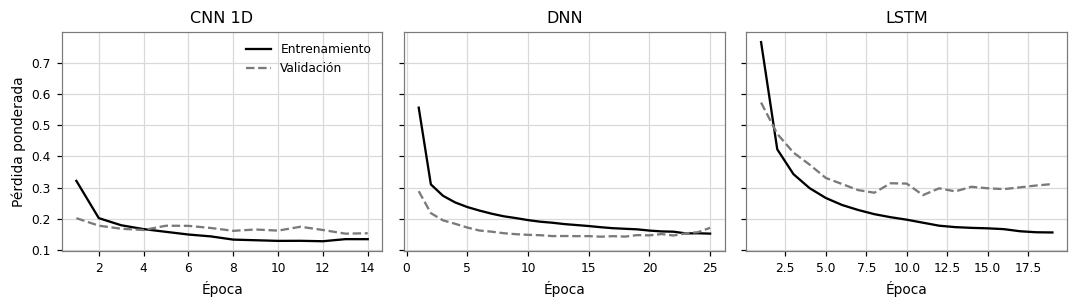

,F1 de entrenamiento,F1 de validación,F1 de prueba,Épocas,Brecha entrenamiento - validación,Brecha validación - prueba
Modelo,,,,,,
CNN 1D,0.9292,0.9241,0.8549,10.5714,0.0051,0.0691
DNN,0.9287,0.9272,0.8548,17.1429,0.0015,0.0725
LSTM,0.9137,0.8771,0.8423,15.0000,0.0367,0.0348


**Interpretación.** Las curvas promedian la pérdida de las 7 semillas de cada modelo, y hay que leerlas con una salvedad: la de entrenamiento se acumula durante la época, con *dropout* activo, mientras que la de validación se calcula al cerrarla. La mayor brecha de F1 macro entre entrenamiento y validación es la de LSTM, con 0,037, y las corridas se detienen en promedio entre 10,6 y 17,1 épocas de un máximo de 50.

Lo anterior indica que esa brecha mide cuánto se ajusta cada modelo a particularidades del entrenamiento que no se trasladan a datos nuevos, de modo que una brecha alta apunta a sobreajuste y una brecha baja con F1 bajo apuntaría a subajuste. Así mismo, la diferencia entre validación y prueba llega a 0,072 en valor absoluto. Como supera δ = 0,01, el F1 de validación no sirve como estimación final: puede ser optimista porque sobre él se eligieron la época y los hiperparámetros, y además los bloques de prueba pueden ser más difíciles que los de validación, sin que esta tabla permita separar ambas causas.

Por lo anterior, se conserva la parada temprana sobre el F1 macro de validación y las comparaciones de la sección 5 se hacen solo con el F1 de prueba.

In [26]:
if hay_resultados:
    fig, ejes = plt.subplots(1, len(NOMBRES), figsize=(3.3 * len(NOMBRES), 2.9), sharey=True)
    for eje, nombre in zip(np.atleast_1d(ejes), NOMBRES):
        curvas = pd.concat([pd.DataFrame(json.loads(r.read_text(encoding="utf-8"))["curvas"]) for r in rutas_definitivas if f"_{nombre.replace(' ', '_')}_" in r.stem])
        media = curvas.groupby("epoca")[["perdida_ent", "perdida_val"]].mean()
        eje.plot(media.index, media["perdida_ent"], color=NEGRO, linestyle="-", label="Entrenamiento")
        eje.plot(media.index, media["perdida_val"], color=GRIS_MEDIO, linestyle="--", label="Validación")
        eje.set_title(nombre)
        eje.set_xlabel("Época")
    np.atleast_1d(ejes)[0].set_ylabel("Pérdida ponderada")
    np.atleast_1d(ejes)[0].legend(frameon=False)
    plt.tight_layout()
    plt.show()
    brecha = METRICAS.groupby("Modelo").agg(**{"F1 de entrenamiento": ("F1 de entrenamiento", "mean"), "F1 de validación": ("F1 de validación", "mean"), "F1 de prueba": ("F1 macro", "mean"), "Épocas": ("Épocas", "mean")}).loc[NOMBRES]
    brecha["Brecha entrenamiento - validación"] = brecha["F1 de entrenamiento"] - brecha["F1 de validación"]
    brecha["Brecha validación - prueba"] = brecha["F1 de validación"] - brecha["F1 de prueba"]
    display(brecha.round(4))
    mayor_brecha = brecha["Brecha entrenamiento - validación"].idxmax()
    brecha_prueba = brecha["Brecha validación - prueba"].abs().max()
    interpretar(f'''**Interpretación.** Las curvas promedian la pérdida de las {len(SEMILLAS)} semillas de cada modelo, y hay que leerlas con una salvedad: la de entrenamiento se acumula durante la época, con *dropout* activo, mientras que la de validación se calcula al cerrarla. La mayor brecha de F1 macro entre entrenamiento y validación es la de {mayor_brecha}, con {num(brecha.loc[mayor_brecha, "Brecha entrenamiento - validación"], 3)}, y las corridas se detienen en promedio entre {num(brecha["Épocas"].min(), 1)} y {num(brecha["Épocas"].max(), 1)} épocas de un máximo de {MAX_EPOCAS}.

Lo anterior indica que esa brecha mide cuánto se ajusta cada modelo a particularidades del entrenamiento que no se trasladan a datos nuevos, de modo que una brecha alta apunta a sobreajuste y una brecha baja con F1 bajo apuntaría a subajuste. Así mismo, la diferencia entre validación y prueba llega a {num(brecha_prueba, 3)} en valor absoluto. {"Como supera δ = 0,01, el F1 de validación no sirve como estimación final: puede ser optimista porque sobre él se eligieron la época y los hiperparámetros, y además los bloques de prueba pueden ser más difíciles que los de validación, sin que esta tabla permita separar ambas causas." if brecha_prueba > 0.01 else "Como no supera δ = 0,01, no se aprecia un optimismo relevante por elegir la época y los hiperparámetros sobre validación."}

Por lo anterior, se conserva la parada temprana sobre el F1 macro de validación y las comparaciones de la sección 5 se hacen solo con el F1 de prueba.''')

Modelo,CNN 1D,DNN,LSTM
Blackhole,0.8334,0.8257,0.8240
Flooding,0.8017,0.8075,0.7824
Normal,0.9688,0.9739,0.9569
Sybil,0.8517,0.8560,0.8302
Wormhole,0.8192,0.8108,0.8178


,Precision,Recall,F1
Blackhole,0.8451,0.8223,0.8334
Flooding,0.7209,0.9059,0.8017
Normal,0.9785,0.9596,0.9688
Sybil,0.9530,0.7710,0.8517
Wormhole,0.7830,0.8592,0.8192


Modelo,CNN 1D,DNN,LSTM
Muy cortos,0.7921,0.7240,0.7098
Cortos,0.8137,0.8075,0.8083
Medianos,0.8029,0.8295,0.7573
Largos,0.7536,0.7647,0.7330


,CNN 1D,DNN,LSTM
σ = 0.0,0.8537,0.8586,0.8326
σ = 0.1,0.8340,0.8390,0.8080
σ = 0.25,0.7622,0.7767,0.7437
σ = 0.5,0.6515,0.6723,0.6399
σ = 1.0,0.4918,0.5193,0.4880


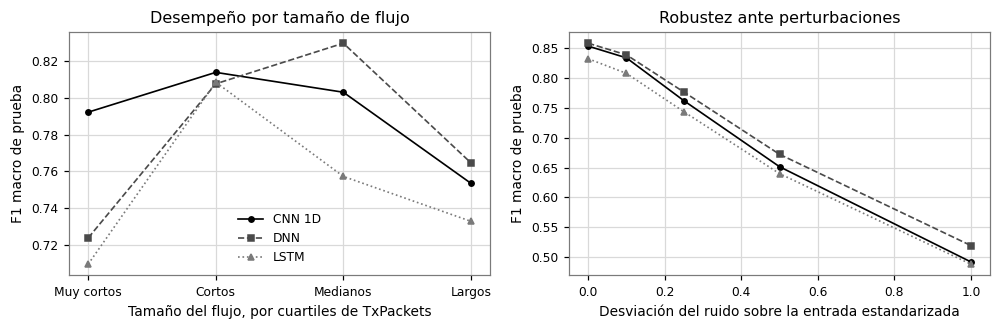

**Interpretación.** Para CNN 1D, la clase más difícil es Flooding, con F1 de 0,802, y la mayor diferencia entre precision y recall aparece en Flooding, con 0,721 y 0,906, lo que muestra hacia qué tipo de error se inclina el modelo en esa clase. Por tamaño de flujo, su F1 macro va de 0,754 en los flujos largos a 0,814 en los cortos. Con un ruido gaussiano de σ = 0,5 sobre la entrada estandarizada, el F1 macro baja 0,202 en CNN 1D, la mayor caída de los tres modelos.

En ese sentido, la comparación global oculta diferencias entre tipos de flujo, de modo que un promedio no basta para decidir dónde conviene mejorar. Hay que tener en cuenta que esta robustez se mide con los pesos de la primera semilla y con un ruido simulado, por lo que orienta la lectura, pero no reemplaza una prueba con tráfico real.

Por esta razón, lo indicado es exigir a cualquier modelo avanzado que reporte el resultado por clase y por tamaño de flujo junto con el global, y juzgar su aporte principalmente donde el baseline todavía tiene margen.

In [27]:
if hay_resultados:
    columnas_clase = [f"F1 {c}" for c in CLASES]
    por_clase = METRICAS.groupby("Modelo")[columnas_clase].mean().loc[NOMBRES].T
    por_clase.index = CLASES
    display(por_clase.round(4))
    detalle_clase = pd.DataFrame({m: [METRICAS.loc[METRICAS["Modelo"] == NOMBRES[0], f"{m} {c}"].mean() for c in CLASES] for m in ["Precision", "Recall", "F1"]}, index=CLASES)
    display(detalle_clase.round(4))
    columnas_banda = [f"F1 {b}" for b in BANDAS_FLUJO]
    por_banda = METRICAS.groupby("Modelo")[columnas_banda].mean().loc[NOMBRES].T
    por_banda.index = BANDAS_FLUJO
    display(por_banda.round(4))

    # Robustez ante perturbaciones: ruido gaussiano sobre la entrada estandarizada, con los pesos de la primera semilla
    RUIDOS = (0.0, 0.1, 0.25, 0.5, 1.0)
    robustez = {}
    for nombre in NOMBRES:
        modelo = MODELOS[nombre]()
        modelo.load_state_dict(torch.load(sorted(CORRIDAS.glob(f"definitiva_{nombre.replace(' ', '_')}_*.pt"))[0]))
        modelo.eval()
        generador_ruido = torch.Generator().manual_seed(SEMILLA)
        valores = []
        for sigma in RUIDOS:
            with torch.no_grad():
                salida = modelo(X[id_pru] + sigma * torch.randn(X[id_pru].shape, generator=generador_ruido))
            valores.append(f1_score(y_prueba, salida.argmax(1).numpy(), average="macro"))
        robustez[nombre] = valores
    robustez = pd.DataFrame(robustez, index=[f"σ = {s}" for s in RUIDOS])
    display(robustez.round(4))

    fig, ejes = plt.subplots(1, 2, figsize=(9.2, 3.1))
    for nombre, estilo in zip(NOMBRES, ESTILOS):
        ejes[0].plot(BANDAS_FLUJO, por_banda[nombre], label=nombre, markersize=3.5, linewidth=1.1, **estilo)
        ejes[1].plot(RUIDOS, robustez[nombre], label=nombre, markersize=3.5, linewidth=1.1, **estilo)
    ejes[0].set(xlabel="Tamaño del flujo, por cuartiles de TxPackets", ylabel="F1 macro de prueba", title="Desempeño por tamaño de flujo")
    ejes[1].set(xlabel="Desviación del ruido sobre la entrada estandarizada", ylabel="F1 macro de prueba", title="Robustez ante perturbaciones")
    ejes[0].legend(frameon=False)
    plt.tight_layout()
    plt.show()

    mejor = NOMBRES[0]
    clase_dificil = por_clase[mejor].idxmin()
    clase_sesgada = (detalle_clase["Precision"] - detalle_clase["Recall"]).abs().idxmax()
    banda_dificil = por_banda[mejor].idxmin()
    caida = robustez.loc["σ = 0.0"] - robustez.loc["σ = 0.5"]
    interpretar(f'''**Interpretación.** Para {mejor}, la clase más difícil es {clase_dificil}, con F1 de {num(por_clase.loc[clase_dificil, mejor], 3)}, y la mayor diferencia entre precision y recall aparece en {clase_sesgada}, con {num(detalle_clase.loc[clase_sesgada, "Precision"], 3)} y {num(detalle_clase.loc[clase_sesgada, "Recall"], 3)}, lo que muestra hacia qué tipo de error se inclina el modelo en esa clase. Por tamaño de flujo, su F1 macro va de {num(por_banda[mejor].min(), 3)} en los flujos {banda_dificil.lower()} a {num(por_banda[mejor].max(), 3)} en los {por_banda[mejor].idxmax().lower()}. Con un ruido gaussiano de σ = 0,5 sobre la entrada estandarizada, el F1 macro baja {num(caida[mejor], 3)} en {mejor}{", la mayor caída de los tres modelos" if caida.idxmax() == mejor else f", y la mayor caída es de {num(caida.max(), 3)}, en {caida.idxmax()}"}.

En ese sentido, la comparación global oculta diferencias entre tipos de flujo, de modo que un promedio no basta para decidir dónde conviene mejorar. Hay que tener en cuenta que esta robustez se mide con los pesos de la primera semilla y con un ruido simulado, por lo que orienta la lectura, pero no reemplaza una prueba con tráfico real.

Por esta razón, lo indicado es exigir a cualquier modelo avanzado que reporte el resultado por clase y por tamaño de flujo junto con el global, y juzgar su aporte principalmente donde el baseline todavía tiene margen.''')

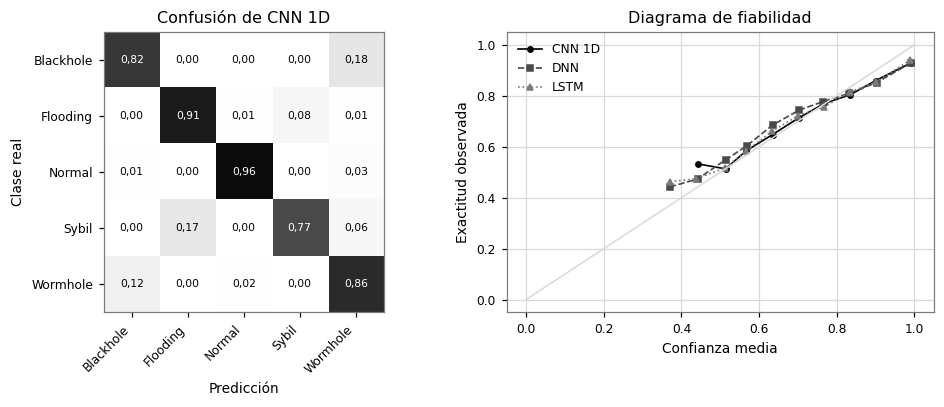

**Interpretación.** La matriz acumula las 7 semillas de CNN 1D y se normaliza por fila, de modo que la diagonal es la exhaustividad de cada clase. La confusión más frecuente es la de Blackhole predicha como Wormhole, en el 17,6 % de sus muestras. En calibración, el error esperado $ECE = \sum_b \frac{n_b}{n} |\mathrm{acc}(b) - \mathrm{conf}(b)|$ va de 0,040 a 0,052, y el mayor corresponde a DNN.

Esto significa que el error no se reparte al azar, sino que se concentra en pares concretos, lo que orienta dónde buscar la mejora. Así mismo, un ECE alto indica que las probabilidades del modelo no se pueden leer como frecuencias, aunque la clase predicha sea correcta, y esto importa porque el Entregable 3 lleva el modelo a un tablero donde se muestra esa confianza.

En consecuencia, se decide reportar el ECE junto con el F1 macro y dejar la recalibración como una decisión posterior, ajustada solo con validación, sin que altere el baseline de este entregable.

In [28]:
if hay_resultados:
    mejor = NOMBRES[0]
    acumulada = sum(confusion_matrix(y_prueba, PROBABILIDADES[(mejor, s)].argmax(1), labels=range(len(CLASES))) for s in SEMILLAS)
    normalizada = acumulada / acumulada.sum(1, keepdims=True)
    fig, ejes = plt.subplots(1, 2, figsize=(9.2, 3.8))
    ejes[0].imshow(normalizada, vmin=0, vmax=1)
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            ejes[0].text(j, i, f"{normalizada[i, j]:.2f}".replace(".", ","), ha="center", va="center", fontsize=7, color="white" if normalizada[i, j] > 0.55 else "black")
    ejes[0].set(xticks=range(len(CLASES)), yticks=range(len(CLASES)), xlabel="Predicción", ylabel="Clase real", title=f"Confusión de {mejor}")
    ejes[0].set_xticklabels(CLASES, rotation=45, ha="right")
    ejes[0].set_yticklabels(CLASES)
    ejes[0].grid(False)

    bordes = np.linspace(0, 1, 16)
    for nombre, estilo in zip(NOMBRES, ESTILOS):
        probabilidad = np.vstack([PROBABILIDADES[(nombre, s)] for s in SEMILLAS])
        verdad = np.tile(y_prueba, len(SEMILLAS))
        confianza, acierto = probabilidad.max(1), probabilidad.argmax(1) == verdad
        puntos = [(confianza[(confianza > a) & (confianza <= b)].mean(), acierto[(confianza > a) & (confianza <= b)].mean()) for a, b in zip(bordes[:-1], bordes[1:]) if ((confianza > a) & (confianza <= b)).sum() > 50]
        ejes[1].plot(*zip(*puntos), label=nombre, markersize=3.5, linewidth=1.1, **estilo)
    ejes[1].plot([0, 1], [0, 1], color=GRIS_CLARO, linewidth=1)
    ejes[1].set(xlabel="Confianza media", ylabel="Exactitud observada", title="Diagrama de fiabilidad")
    ejes[1].legend(frameon=False)
    plt.tight_layout()
    plt.show()

    sin_diagonal = normalizada.copy()
    np.fill_diagonal(sin_diagonal, 0)
    real, predicho = np.unravel_index(int(np.argmax(sin_diagonal)), sin_diagonal.shape)
    ece = METRICAS.groupby("Modelo")["ECE"].mean().loc[NOMBRES]
    peor_ece = ece.idxmax()
    interpretar(f'''**Interpretación.** La matriz acumula las {len(SEMILLAS)} semillas de {mejor} y se normaliza por fila, de modo que la diagonal es la exhaustividad de cada clase. La confusión más frecuente es la de {CLASES[real]} predicha como {CLASES[predicho]}, en el {num(100 * sin_diagonal[real, predicho], 1)} % de sus muestras. En calibración, el error esperado $ECE = \\sum_b \\frac{{n_b}}{{n}} |\\mathrm{{acc}}(b) - \\mathrm{{conf}}(b)|$ va de {num(ece.min(), 3)} a {num(ece.max(), 3)}, y el mayor corresponde a {peor_ece}.

Esto significa que el error no se reparte al azar, sino que se concentra en pares concretos, lo que orienta dónde buscar la mejora. Así mismo, un ECE alto indica que las probabilidades del modelo no se pueden leer como frecuencias, aunque la clase predicha sea correcta, y esto importa porque el Entregable 3 lleva el modelo a un tablero donde se muestra esa confianza.

En consecuencia, se decide reportar el ECE junto con el F1 macro y dejar la recalibración como una decisión posterior, ajustada solo con validación, sin que altere el baseline de este entregable.''')

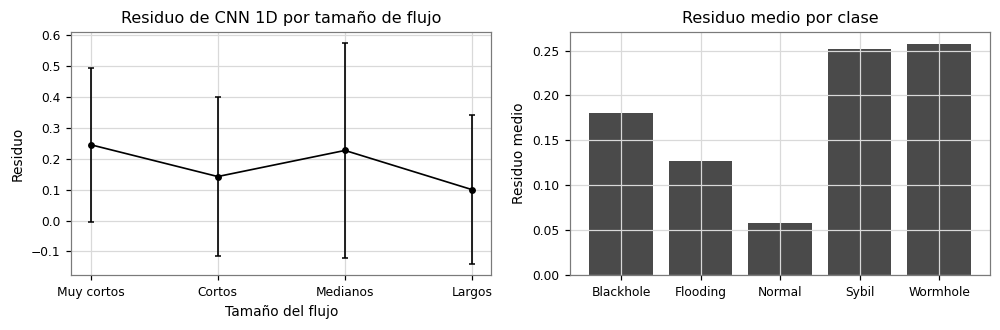

**Interpretación.** En clasificación, el residuo de una muestra se define como $1 - p_\theta(y_i \mid x_i)$, la probabilidad que el modelo no asignó a su clase real, promediada entre semillas. Para CNN 1D, el residuo medio va de 0,100 a 0,245 entre rangos de tamaño de flujo, con un ρ de Spearman de -0,259 frente a `TxPackets` (p < 0,001), y la prueba de Levene entre rangos da p < 0,001. Por clase, el residuo medio va de 0,058 a 0,258, y el mayor corresponde a Wormhole.

Esto significa que el residuo tiene estructura, porque depende del tamaño del flujo y no se comporta como un error aleatorio. Así mismo, la dispersión cambia entre rangos, es decir, hay heterocedasticidad, de modo que un promedio global describe mal a cada rango. Hay que tener en cuenta que la diferencia entre clases mide un sesgo que persiste pese a la ponderación de la pérdida.

Por tal motivo, se reportan los resultados por tamaño de flujo y por clase, y no solo el promedio global.

In [29]:
if hay_resultados:
    # En clasificación, el residuo de una muestra es la probabilidad que el modelo no asignó a su clase real
    mejor = NOMBRES[0]
    filas_prueba = np.arange(len(y_prueba))
    residuo = np.mean([1 - PROBABILIDADES[(mejor, s)][filas_prueba, y_prueba] for s in SEMILLAS], axis=0)
    grupos_banda = [residuo[banda_prueba == b] for b in range(len(BANDAS_FLUJO))]
    medias_residuo = np.array([g.mean() for g in grupos_banda])
    por_clase_residuo = pd.Series(residuo).groupby(y_prueba).mean().reindex(range(len(CLASES)))
    fig, ejes = plt.subplots(1, 2, figsize=(9.2, 3.1))
    ejes[0].errorbar(BANDAS_FLUJO, medias_residuo, yerr=[g.std() for g in grupos_banda], color=NEGRO, linestyle="-", marker="o", markersize=3.5, capsize=2, linewidth=1.1)
    ejes[0].set(xlabel="Tamaño del flujo", ylabel="Residuo", title=f"Residuo de {mejor} por tamaño de flujo")
    ejes[1].bar(CLASES, por_clase_residuo.to_numpy(), color=GRIS_OSCURO)
    ejes[1].set(ylabel="Residuo medio", title="Residuo medio por clase")
    plt.tight_layout()
    plt.show()
    rho_residuo, p_rho_residuo = stats.spearmanr(tx_prueba, residuo)
    _, p_levene = stats.levene(*grupos_banda, center="median")
    lectura_estructura = "Esto significa que el residuo tiene estructura, porque depende del tamaño del flujo y no se comporta como un error aleatorio" if p_rho_residuo < ALFA else "Esto significa que no se detecta una relación monótona entre el residuo y el tamaño del flujo"
    lectura_varianza = "Así mismo, la dispersión cambia entre rangos, es decir, hay heterocedasticidad, de modo que un promedio global describe mal a cada rango" if p_levene < ALFA else "Así mismo, no se detecta que la dispersión cambie entre rangos"
    interpretar(f'''**Interpretación.** En clasificación, el residuo de una muestra se define como $1 - p_\\theta(y_i \\mid x_i)$, la probabilidad que el modelo no asignó a su clase real, promediada entre semillas. Para {mejor}, el residuo medio va de {num(medias_residuo.min(), 3)} a {num(medias_residuo.max(), 3)} entre rangos de tamaño de flujo, con un ρ de Spearman de {num(rho_residuo, 3)} frente a `TxPackets` ({valor_p(p_rho_residuo)}), y la prueba de Levene entre rangos da {valor_p(p_levene)}. Por clase, el residuo medio va de {num(por_clase_residuo.min(), 3)} a {num(por_clase_residuo.max(), 3)}, y el mayor corresponde a {CLASES[int(np.nanargmax(por_clase_residuo.to_numpy()))]}.

{lectura_estructura}. {lectura_varianza}. Hay que tener en cuenta que la diferencia entre clases mide un sesgo que persiste pese a la ponderación de la pérdida.

Por tal motivo, se reportan los resultados por tamaño de flujo y por clase, y no solo el promedio global.''')

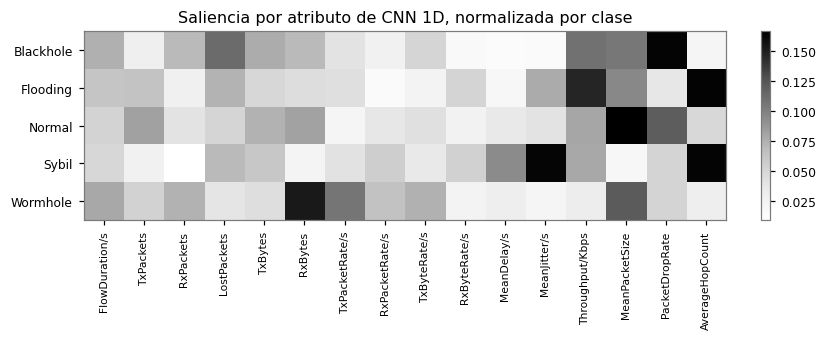

,"Blackhole, acierto",Blackhole predicho como Wormhole,"Wormhole, acierto",|fallo - acierto|
MeanPacketSize,-1.38,0.59,0.59,1.97
AverageHopCount,-0.51,1.07,1.21,1.58
LostPackets,0.09,-0.63,-0.63,0.72
TxPackets,-0.46,-1.09,-1.09,0.63
MeanJitter/s,-0.02,-0.60,0.57,0.58
RxBytes,-0.59,-1.14,-0.96,0.55


**Interpretación.** El mapa muestra, para CNN 1D con la semilla 2001, el valor medio de $|\partial f_c / \partial x_j|$ sobre los aciertos de cada clase. El atributo con más saliencia es `PacketDropRate` en Blackhole y `RxBytes` en Wormhole. La tabla contrasta, en desviaciones estándar frente a la media de entrenamiento, los 946 flujos de Blackhole predichos como Wormhole, que es el error más frecuente, con los aciertos de ambas clases; la mayor diferencia está en `MeanPacketSize`.

Es decir, los errores se concentran en flujos cuyos atributos se parecen más a los de la otra clase, lo cual es coherente con el ruido de etiquetas y el solapamiento de la sección 2.1.2. Hay que tener en cuenta que la saliencia es una derivada local, y que orienta la lectura, pero no demuestra por sí sola la ausencia de atajos.

Con base en esto, se propone contrastar esta inspección con el análisis de atajos de la sección 2.1.4, y mantener esa auditoría en los modelos avanzados del Entregable 2.

In [30]:
RUTAS_PESOS = sorted(CORRIDAS.glob("definitiva_*.pt"))
if hay_resultados and RUTAS_PESOS:
    mejor = NOMBRES[0]
    pesos = [r for r in RUTAS_PESOS if f"_{mejor.replace(' ', '_')}_" in r.stem]
    modelo = MODELOS[mejor]()
    modelo.load_state_dict(torch.load(pesos[0]))
    modelo.eval()
    semilla_pesos = int(pesos[0].stem.split("_")[-1])
    pred = PROBABILIDADES[(mejor, semilla_pesos)].argmax(1)
    ATRIBUTOS_NOMBRES = [str(a) for a in preparados["atributos"]]
    saliencia = np.zeros((len(CLASES), N_ATRIBUTOS))
    rng_cualitativo = np.random.default_rng(SEMILLA)
    for c in range(len(CLASES)):
        filas_clase = rng_cualitativo.permutation(np.flatnonzero((y_prueba == c) & (pred == c)))[:2000]
        entrada = X[id_pru[filas_clase]].clone().requires_grad_(True)
        modelo(entrada)[:, c].sum().backward()
        saliencia[c] = entrada.grad.abs().mean(0).numpy()
    saliencia = saliencia / saliencia.sum(1, keepdims=True)
    fig, eje = plt.subplots(figsize=(7.6, 3.2))
    imagen = eje.imshow(saliencia, aspect="auto")
    eje.set_xticks(range(N_ATRIBUTOS), ATRIBUTOS_NOMBRES, rotation=90, fontsize=7)
    eje.set_yticks(range(len(CLASES)), CLASES)
    eje.grid(False)
    eje.set_title(f"Saliencia por atributo de {mejor}, normalizada por clase")
    fig.colorbar(imagen, fraction=0.03)
    plt.tight_layout()
    plt.show()
    principales = {CLASES[c]: ATRIBUTOS_NOMBRES[int(saliencia[c].argmax())] for c in range(len(CLASES))}

    # Casos difíciles: el par de clases que más se confunde, comparado con los aciertos de la misma clase
    errores = confusion_matrix(y_prueba, pred, labels=range(len(CLASES))).astype(float)
    np.fill_diagonal(errores, 0)
    real, predicha = np.unravel_index(int(errores.argmax()), errores.shape)
    aciertos = id_pru.numpy()[(y_prueba == real) & (pred == real)]
    fallos = id_pru.numpy()[(y_prueba == real) & (pred == predicha)]
    otra_clase = id_pru.numpy()[(y_prueba == predicha) & (pred == predicha)]
    contraste = pd.DataFrame({f"{CLASES[real]}, acierto": np.median(X[aciertos].numpy(), axis=0), f"{CLASES[real]} predicho como {CLASES[predicha]}": np.median(X[fallos].numpy(), axis=0), f"{CLASES[predicha]}, acierto": np.median(X[otra_clase].numpy(), axis=0)}, index=ATRIBUTOS_NOMBRES)
    contraste["|fallo - acierto|"] = (contraste.iloc[:, 1] - contraste.iloc[:, 0]).abs()
    display(contraste.sort_values("|fallo - acierto|", ascending=False).head(6).round(2))
    atributo_error = contraste["|fallo - acierto|"].idxmax()
    del modelo
    interpretar(f'''**Interpretación.** El mapa muestra, para {mejor} con la semilla {semilla_pesos}, el valor medio de $|\\partial f_c / \\partial x_j|$ sobre los aciertos de cada clase. El atributo con más saliencia es `{principales[CLASES[0]]}` en {CLASES[0]} y `{principales[CLASES[-1]]}` en {CLASES[-1]}. La tabla contrasta, en desviaciones estándar frente a la media de entrenamiento, los {num(len(fallos), 0)} flujos de {CLASES[real]} predichos como {CLASES[predicha]}, que es el error más frecuente, con los aciertos de ambas clases; la mayor diferencia está en `{atributo_error}`.

Es decir, los errores se concentran en flujos cuyos atributos se parecen más a los de la otra clase, lo cual es coherente con el ruido de etiquetas y el solapamiento de la sección 2.1.2. Hay que tener en cuenta que la saliencia es una derivada local, y que orienta la lectura, pero no demuestra por sí sola la ausencia de atajos.

Con base en esto, se propone contrastar esta inspección con el análisis de atajos de la sección 2.1.4, y mantener esa auditoría en los modelos avanzados del Entregable 2.''')
elif hay_resultados:
    print("Análisis cualitativo pendiente: requiere los pesos de la primera semilla")

## 5. Benchmark de los modelos base y definición del baseline

En esta sección se comparan los tres modelos, se fija el baseline y se calcula el margen de mejora que debe superar un modelo avanzado, con pruebas de hipótesis formales. El orden es el siguiente: primero la tabla comparativa y el ranking, luego la definición del baseline y del umbral, después la verificación de supuestos y, finalmente, las pruebas. El nivel de significancia es α = 0,05, declarado en la sección 1 antes de ver cualquier resultado. Las observaciones pareadas son las semillas, que comparten partición y conjunto de prueba en los tres modelos.

### 5.1 Comparación tabular

In [31]:
def intervalo_t(valores):
    valores = np.asarray(valores, dtype=float)
    medio = stats.t.ppf(0.975, len(valores) - 1) * valores.std(ddof=1) / np.sqrt(len(valores))
    return valores.mean() - medio, valores.mean() + medio


if hay_resultados:
    filas_tabla = []
    for nombre in NOMBRES:
        g = METRICAS[METRICAS["Modelo"] == nombre]
        fila = {"Modelo": nombre}
        for metrica in ["F1 macro", "Accuracy", "Balanced accuracy", "Precision macro", "Recall macro", "F1 ponderado", "Precision ponderada", "Recall ponderado", "AUC-ROC macro", "AUC-PR macro", "MCC", "ECE"]:
            a, b = intervalo_t(g[metrica])
            fila[metrica] = f"{num(g[metrica].mean(), 4)} ± {num(g[metrica].std(ddof=1), 4)} [{num(a, 4)}; {num(b, 4)}]"
        fila["Parámetros"] = num(g["Parámetros"].iloc[0], 0)
        fila["Minutos de entrenamiento"] = f"{num(g['Minutos'].mean(), 1)} ± {num(g['Minutos'].std(ddof=1), 1)}"
        fila["ms por muestra"] = num(g["ms por muestra"].mean(), 3)
        filas_tabla.append(fila)
    tabla_benchmark = pd.DataFrame(filas_tabla).set_index("Modelo").T
    display(tabla_benchmark)
    tabla_benchmark.to_csv(RESULTADOS / "tabla_benchmark.csv")
    medias_f1 = MATRIZ_F1.mean()
    desv_f1 = MATRIZ_F1.std(ddof=1)
    medias_auc = METRICAS.groupby("Modelo")[["AUC-ROC macro", "AUC-PR macro", "ECE"]].mean()
    mejor_auc = medias_auc["AUC-ROC macro"].idxmax()
    interpretar(f'''**Interpretación.** La tabla reporta media ± desviación estándar sobre {len(SEMILLAS)} semillas y, entre corchetes, el intervalo de confianza al 95 % calculado con la $t$ de Student, $\\bar{{x}} \\pm t_{{0,975;\\,n-1}}\\, s / \\sqrt{{n}}$. En la métrica primaria, {NOMBRES[0]} obtiene {num(medias_f1[NOMBRES[0]], 4)}, {NOMBRES[1]} {num(medias_f1[NOMBRES[1]], 4)} y {NOMBRES[2]} {num(medias_f1[NOMBRES[2]], 4)}, con desviaciones entre semillas de {num(desv_f1.min(), 4)} a {num(desv_f1.max(), 4)}. {"" if mejor_auc == NOMBRES[0] else f"El orden cambia con la métrica: {mejor_auc} obtiene el mayor AUC-ROC macro, {num(medias_auc.loc[mejor_auc, 'AUC-ROC macro'], 4)}, y su AUC-PR macro es de {num(medias_auc.loc[mejor_auc, 'AUC-PR macro'], 4)}, con un ECE de {num(medias_auc.loc[mejor_auc, 'ECE'], 4)}."}

Hay que tener en cuenta que esa dispersión mide la inicialización y el orden de los lotes, no la selección de los datos, porque todas las corridas comparten la partición. Por eso los intervalos no deben leerse como la incertidumbre total de generalización, que se aborda con el remuestreo por bloques y con la validación cruzada repetida en la sección 5.4.

Por tal motivo, se opta por usar esta tabla para describir el desempeño y por apoyar toda afirmación comparativa en las pruebas pareadas de la sección 5.4, no en los promedios.''')

Modelo,CNN 1D,DNN,LSTM
F1 macro,"0,8549 ± 0,0091 [0,8466; 0,8633]","0,8548 ± 0,0110 [0,8446; 0,8649]","0,8423 ± 0,0135 [0,8298; 0,8547]"
Accuracy,"0,8607 ± 0,0088 [0,8526; 0,8689]","0,8604 ± 0,0111 [0,8502; 0,8707]","0,8499 ± 0,0134 [0,8375; 0,8623]"
Balanced accuracy,"0,8636 ± 0,0081 [0,8562; 0,8711]","0,8617 ± 0,0113 [0,8513; 0,8722]","0,8501 ± 0,0119 [0,8391; 0,8610]"
Precision macro,"0,8561 ± 0,0078 [0,8489; 0,8633]","0,8545 ± 0,0118 [0,8437; 0,8654]","0,8438 ± 0,0172 [0,8279; 0,8597]"
Recall macro,"0,8636 ± 0,0081 [0,8562; 0,8711]","0,8617 ± 0,0113 [0,8513; 0,8722]","0,8501 ± 0,0119 [0,8391; 0,8610]"
F1 ponderado,"0,8619 ± 0,0086 [0,8540; 0,8698]","0,8610 ± 0,0111 [0,8507; 0,8712]","0,8503 ± 0,0133 [0,8380; 0,8626]"
Precision ponderada,"0,8711 ± 0,0076 [0,8641; 0,8782]","0,8672 ± 0,0120 [0,8561; 0,8783]","0,8587 ± 0,0160 [0,8439; 0,8735]"
Recall ponderado,"0,8607 ± 0,0088 [0,8526; 0,8689]","0,8604 ± 0,0111 [0,8502; 0,8707]","0,8499 ± 0,0134 [0,8375; 0,8623]"
AUC-ROC macro,"0,9637 ± 0,0010 [0,9627; 0,9646]","0,9602 ± 0,0050 [0,9556; 0,9648]","0,9728 ± 0,0048 [0,9684; 0,9773]"
AUC-PR macro,"0,8511 ± 0,0066 [0,8450; 0,8571]","0,8336 ± 0,0104 [0,8239; 0,8432]","0,8791 ± 0,0235 [0,8574; 0,9008]"


**Interpretación.** La tabla reporta media ± desviación estándar sobre 7 semillas y, entre corchetes, el intervalo de confianza al 95 % calculado con la $t$ de Student, $\bar{x} \pm t_{0,975;\,n-1}\, s / \sqrt{n}$. En la métrica primaria, CNN 1D obtiene 0,8549, DNN 0,8548 y LSTM 0,8423, con desviaciones entre semillas de 0,0091 a 0,0135. El orden cambia con la métrica: LSTM obtiene el mayor AUC-ROC macro, 0,9728, y su AUC-PR macro es de 0,8791, con un ECE de 0,0402.

Hay que tener en cuenta que esa dispersión mide la inicialización y el orden de los lotes, no la selección de los datos, porque todas las corridas comparten la partición. Por eso los intervalos no deben leerse como la incertidumbre total de generalización, que se aborda con el remuestreo por bloques y con la validación cruzada repetida en la sección 5.4.

Por tal motivo, se opta por usar esta tabla para describir el desempeño y por apoyar toda afirmación comparativa en las pruebas pareadas de la sección 5.4, no en los promedios.

### 5.2 Ranking de los modelos base

Se ordenan los tres modelos por la métrica primaria y se contrasta ese orden con su costo: número de parámetros, tiempo de entrenamiento y tiempo de inferencia. El propósito es determinar si la mayor complejidad se traduce en mejor desempeño.

,Posición,F1 macro,Parámetros (M),Minutos,ms por muestra
Modelo,,,,,
CNN 1D,1,0.8549,0.0395,1.4674,0.0287
DNN,2,0.8548,0.0127,0.6455,0.0007
LSTM,3,0.8423,0.0175,2.2990,0.0100


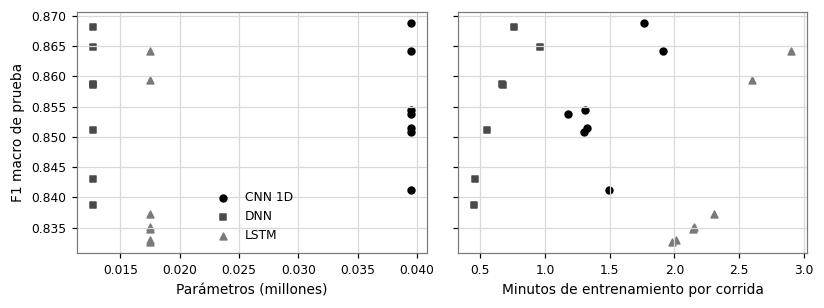

**Interpretación.** El orden por F1 macro es CNN 1D, DNN, LSTM. El modelo con más parámetros es CNN 1D, con 0,04 millones, y el más lento de entrenar es LSTM, con 2,3 minutos por corrida. El mejor modelo es también el más grande, aunque supera a DNN por solo 0,0002. Frente a DNN, CNN 1D usa 3,1 veces los parámetros, 2,3 veces el tiempo de entrenamiento y 41 veces el tiempo de inferencia por muestra.

Lo anterior indica que, entre estos tres modelos, más parámetros no se traducen de forma directa en mejor desempeño: LSTM tiene más parámetros que DNN y un F1 macro menor. Sin embargo, con tres modelos esa relación es solo una descripción, porque no hay grados de libertad para estimarla, y además mezcla capacidad con sesgo inductivo.

Por ello, se recomienda leer el *trade-off* junto con la significancia y la relevancia práctica de la sección 5.4: una diferencia pequeña no justifica por sí sola el costo de un modelo mayor.

In [32]:
if hay_resultados:
    ranking = METRICAS.groupby("Modelo").agg(**{"F1 macro": ("F1 macro", "mean"), "Parámetros (M)": ("Parámetros", lambda v: v.iloc[0] / 1e6), "Minutos": ("Minutos", "mean"), "ms por muestra": ("ms por muestra", "mean")}).loc[NOMBRES]
    ranking.insert(0, "Posición", range(1, len(ranking) + 1))
    display(ranking.round(4))
    fig, ejes = plt.subplots(1, 2, figsize=(7.6, 2.9), sharey=True)
    for nombre, estilo in zip(NOMBRES, ESTILOS):
        g = METRICAS[METRICAS["Modelo"] == nombre]
        ejes[0].scatter(g["Parámetros"] / 1e6, g["F1 macro"], color=estilo["color"], marker=estilo["marker"], s=20, label=nombre)
        ejes[1].scatter(g["Minutos"], g["F1 macro"], color=estilo["color"], marker=estilo["marker"], s=20)
    ejes[0].set(xlabel="Parámetros (millones)", ylabel="F1 macro de prueba")
    ejes[1].set(xlabel="Minutos de entrenamiento por corrida")
    ejes[0].legend(frameon=False)
    plt.tight_layout()
    plt.show()
    mas_grande = ranking["Parámetros (M)"].idxmax()
    mas_lento = ranking["Minutos"].idxmax()
    contraejemplo = next(((a, b) for a in NOMBRES for b in NOMBRES if ranking.loc[a, "Parámetros (M)"] > ranking.loc[b, "Parámetros (M)"] and ranking.loc[a, "F1 macro"] < ranking.loc[b, "F1 macro"]), None)
    interpretar(f'''**Interpretación.** El orden por F1 macro es {", ".join(NOMBRES)}. El modelo con más parámetros es {mas_grande}, con {num(ranking.loc[mas_grande, "Parámetros (M)"], 2)} millones, y el más lento de entrenar es {mas_lento}, con {num(ranking.loc[mas_lento, "Minutos"], 1)} minutos por corrida. {f"El mejor modelo es también el más grande, aunque supera a {NOMBRES[1]} por solo {num(ranking.loc[NOMBRES[0], 'F1 macro'] - ranking.loc[NOMBRES[1], 'F1 macro'], 4)}." if NOMBRES[0] == mas_grande else f"El mejor modelo no es el más grande: {NOMBRES[0]} tiene {num(ranking.loc[NOMBRES[0], 'Parámetros (M)'], 2)} millones."} Frente a {NOMBRES[1]}, {NOMBRES[0]} usa {num(ranking.loc[NOMBRES[0], "Parámetros (M)"] / ranking.loc[NOMBRES[1], "Parámetros (M)"], 1)} veces los parámetros, {num(ranking.loc[NOMBRES[0], "Minutos"] / ranking.loc[NOMBRES[1], "Minutos"], 1)} veces el tiempo de entrenamiento y {num(ranking.loc[NOMBRES[0], "ms por muestra"] / ranking.loc[NOMBRES[1], "ms por muestra"], 0)} veces el tiempo de inferencia por muestra.

Lo anterior indica {"que, entre estos tres modelos, más parámetros se acompañan de mejor desempeño" if contraejemplo is None else f"que, entre estos tres modelos, más parámetros no se traducen de forma directa en mejor desempeño: {contraejemplo[0]} tiene más parámetros que {contraejemplo[1]} y un F1 macro menor"}. Sin embargo, con tres modelos esa relación es solo una descripción, porque no hay grados de libertad para estimarla, y además mezcla capacidad con sesgo inductivo.

Por ello, se recomienda leer el *trade-off* junto con la significancia y la relevancia práctica de la sección 5.4: una diferencia pequeña no justifica por sí sola el costo de un modelo mayor.''')

### 5.3 Definición del baseline y margen de mejora disponible

Este es el objetivo central del entregable. Se identifica el mejor modelo, se cuantifican las diferencias absolutas y relativas con los demás y se define el umbral de mejora. La mejora mínima detectable sale de la potencia exacta de la prueba $t$ pareada con α = 0,05 y potencia de 0,80, y el umbral combina esa cifra con el margen de relevancia δ = 0,01 declarado a priori: $\text{umbral} = \overline{F1}_{\text{baseline}} + \max(\delta, \text{mejora mínima detectable})$.

In [33]:
ALFA, POTENCIA_OBJETIVO, DELTA = 0.05, 0.80, 0.01
# Valores publicados sobre UAVIDS-2025, con partición aleatoria: repositorio de Zeng et al. (2025) y Zarkadis y Douligeris (2026)
LITERATURA_F1 = [("DNN, Zeng et al. (2025)", 0.93), ("CNN, Zeng et al. (2025)", 0.93), ("LSTM, Zeng et al. (2025)", 0.94), ("MLP, Zarkadis y Douligeris (2026)", 0.9066), ("RealMLP, Zarkadis y Douligeris (2026)", 0.9428)]


def potencia_pareada(desviacion, n, efecto):
    return TTestPower().power(effect_size=abs(efecto) / desviacion, nobs=n, alpha=ALFA, alternative="two-sided") if desviacion > 0 else 1.0


def minima_detectable(desviacion, n):
    return TTestPower().solve_power(effect_size=None, nobs=n, alpha=ALFA, power=POTENCIA_OBJETIVO, alternative="two-sided") * desviacion


if hay_resultados:
    BASELINE = NOMBRES[0]
    a, b = intervalo_t(MATRIZ_F1[BASELINE])
    diferencias = []
    for nombre in NOMBRES[1:]:
        d = MATRIZ_F1[BASELINE] - MATRIZ_F1[nombre]
        sd = d.std(ddof=1)
        diferencias.append({"Comparación": f"{BASELINE} - {nombre}", "Diferencia absoluta": d.mean(), "Diferencia relativa (%)": 100 * d.mean() / MATRIZ_F1[nombre].mean(), "σ̂_d": sd, "δ/σ̂_d": DELTA / sd if sd > 0 else np.inf,
                            "d de Cohen pareada": d.mean() / sd if sd > 0 else np.inf, "Mínima detectable": minima_detectable(sd, len(d)), "Potencia para δ": potencia_pareada(sd, len(d), DELTA)})
    diferencias = pd.DataFrame(diferencias)
    display(diferencias.round(4))
    # Referencias de contexto, sin Deep Learning, ajustadas solo con entrenamiento y evaluadas una vez en prueba
    logistico_ref = LogisticRegression(C=1.0, max_iter=3000).fit(X[id_ent].numpy(), y_np[particion["entrenamiento"]])
    boosting_ref = HistGradientBoostingClassifier(max_iter=150, random_state=SEMILLA).fit(X[id_ent].numpy(), y_np[particion["entrenamiento"]])
    f1_logistico_ref = f1_score(y_prueba, logistico_ref.predict(X[id_pru].numpy()), average="macro")
    f1_boosting_ref = f1_score(y_prueba, boosting_ref.predict(X[id_pru].numpy()), average="macro")
    filas_referencia = [{"Modelo": f"{n}, este trabajo", "Partición": "Agrupada por bloques", "F1": METRICAS.loc[METRICAS["Modelo"] == n, "F1 macro"].mean(), "Promedio": "Macro"} for n in NOMBRES]
    filas_referencia += [{"Modelo": "Regresión logística, este trabajo (contexto)", "Partición": "Agrupada por bloques", "F1": f1_logistico_ref, "Promedio": "Macro"}, {"Modelo": "Boosting, este trabajo (contexto)", "Partición": "Agrupada por bloques", "F1": f1_boosting_ref, "Promedio": "Macro"}]
    filas_referencia += [{"Modelo": m, "Partición": "Aleatoria estratificada", "F1": v, "Promedio": "Según lo publicado"} for m, v in LITERATURA_F1]
    display(pd.DataFrame(filas_referencia).style.hide(axis="index").format({"F1": "{:.4f}"}))
    sigma_referencia = float(diferencias["σ̂_d"].max())
    MINIMA = minima_detectable(sigma_referencia, len(SEMILLAS))
    UMBRAL = MATRIZ_F1[BASELINE].mean() + max(DELTA, MINIMA)
    SEMILLAS_PARA_DELTA = next(n for n in range(3, 501) if potencia_pareada(sigma_referencia, n, DELTA) >= POTENCIA_OBJETIVO)
    ventaja_lineal = MATRIZ_F1.mean().min() - f1_logistico_ref

    (RESULTADOS / "baseline.json").write_text(json.dumps({"modelo": BASELINE, "f1_macro": float(MATRIZ_F1[BASELINE].mean()), "desviacion": float(MATRIZ_F1[BASELINE].std(ddof=1)), "ic95": [float(a), float(b)],
                                                          "minima_detectable": float(MINIMA), "delta": DELTA, "umbral": float(UMBRAL), "sigma_d": sigma_referencia, "semillas": [int(s) for s in SEMILLAS]}, ensure_ascii=False, indent=1), encoding="utf-8")
    interpretar(f'''**Interpretación.** El baseline es {BASELINE}, con F1 macro de {num(MATRIZ_F1[BASELINE].mean(), 4)} ± {num(MATRIZ_F1[BASELINE].std(ddof=1), 4)} e IC 95 % de [{num(a, 4)}; {num(b, 4)}]. Con {len(SEMILLAS)} semillas y la mayor $\\hat{{\\sigma}}_d$ de sus comparaciones, {num(sigma_referencia, 4)}, la mejora mínima detectable es de {num(MINIMA, 4)}, que {"no supera" if MINIMA <= DELTA else "supera"} el margen δ = {num(DELTA, 2)}. Como referencias de contexto, en este mismo conjunto de prueba la regresión logística obtiene {num(f1_logistico_ref, 4)}, de modo que el peor modelo base la supera en {num(ventaja_lineal, 4)}, y el boosting, sin ajuste de hiperparámetros, obtiene {num(f1_boosting_ref, 4)}, {"por encima" if f1_boosting_ref > MATRIZ_F1[BASELINE].mean() else "por debajo"} del baseline y {"por encima" if f1_boosting_ref > UMBRAL else "por debajo"} del umbral que se define enseguida. La tabla agrega los valores publicados, que hay que leer con dos salvedades: usan partición aleatoria, y la sección 2.1.3 mostró que esa partición sube el F1 macro de referencia en unas {num(f1_azar - f1_grupos, 3)}, de modo que una diferencia puede deberse a la partición y no al modelo; además, se transcriben como F1 tal como los publican sus autores, sin que en todos los casos se pueda confirmar que el promedio sea macro.

Esto quiere decir que un modelo avanzado debe alcanzar un F1 macro medio de al menos {num(UMBRAL, 4)} para superar el baseline de forma distinguible y relevante. {"Por la definición del promedio macro, ese margen equivale a mejorar 0,05 el F1 de una sola clase, dejando iguales las demás." if MINIMA <= DELTA else "Como la mínima detectable supera δ, el umbral queda fijado por la variabilidad medida y no por la relevancia práctica, lo que se declara como limitación del diseño."} Con esa misma $\\hat{{\\sigma}}_d$, detectar δ con potencia de {num(POTENCIA_OBJETIVO, 2)} exigiría {SEMILLAS_PARA_DELTA} semillas pareadas. Así mismo, la ventaja sobre el modelo lineal responde la pregunta que dejó abierta la sección 2.2.3: en prueba, la no linealidad {"sí aporta más que" if ventaja_lineal > DELTA else "no aporta más que"} δ.

En consecuencia, se decide heredar en el Entregable 2 este umbral y la $\\hat{{\\sigma}}_d$ medida como punto de partida para dimensionar las semillas, y conservar el archivo `baseline.json` como referencia. El margen hasta el F1 macro perfecto es de {num(1 - MATRIZ_F1[BASELINE].mean(), 4)}. Como cota de referencia no hay acuerdo entre anotadores ni desempeño humano, porque la etiqueta proviene del escenario; la única señal medible de ruido irreducible son las {num(filas_conflicto, 0)} filas, el {num(100 * filas_conflicto / N, 1)} % del archivo, en grupos de casi duplicados con más de una clase (sección 2.1.2). Esa cota es parcial, porque solo observa los flujos casi idénticos, de modo que no permite afirmar qué parte del margen es alcanzable.''')

,Comparación,Diferencia absoluta,Diferencia relativa (%),σ̂_d,δ/σ̂_d,d de Cohen pareada,Mínima detectable,Potencia para δ
0,CNN 1D - DNN,0.0002,0.0208,0.0078,1.2826,0.0228,0.0099,0.8059
1,CNN 1D - LSTM,0.0127,1.5039,0.0177,0.5640,0.7144,0.0226,0.2429


Modelo,Partición,F1,Promedio
"CNN 1D, este trabajo",Agrupada por bloques,0.8549,Macro
"DNN, este trabajo",Agrupada por bloques,0.8548,Macro
"LSTM, este trabajo",Agrupada por bloques,0.8423,Macro
"Regresión logística, este trabajo (contexto)",Agrupada por bloques,0.7661,Macro
"Boosting, este trabajo (contexto)",Agrupada por bloques,0.8748,Macro
"DNN, Zeng et al. (2025)",Aleatoria estratificada,0.9300,Según lo publicado
"CNN, Zeng et al. (2025)",Aleatoria estratificada,0.9300,Según lo publicado
"LSTM, Zeng et al. (2025)",Aleatoria estratificada,0.9400,Según lo publicado
"MLP, Zarkadis y Douligeris (2026)",Aleatoria estratificada,0.9066,Según lo publicado
"RealMLP, Zarkadis y Douligeris (2026)",Aleatoria estratificada,0.9428,Según lo publicado


**Interpretación.** El baseline es CNN 1D, con F1 macro de 0,8549 ± 0,0091 e IC 95 % de [0,8466; 0,8633]. Con 7 semillas y la mayor $\hat{\sigma}_d$ de sus comparaciones, 0,0177, la mejora mínima detectable es de 0,0226, que supera el margen δ = 0,01. Como referencias de contexto, en este mismo conjunto de prueba la regresión logística obtiene 0,7661, de modo que el peor modelo base la supera en 0,0762, y el boosting, sin ajuste de hiperparámetros, obtiene 0,8748, por encima del baseline y por debajo del umbral que se define enseguida. La tabla agrega los valores publicados, que hay que leer con dos salvedades: usan partición aleatoria, y la sección 2.1.3 mostró que esa partición sube el F1 macro de referencia en unas 0,069, de modo que una diferencia puede deberse a la partición y no al modelo; además, se transcriben como F1 tal como los publican sus autores, sin que en todos los casos se pueda confirmar que el promedio sea macro.

Esto quiere decir que un modelo avanzado debe alcanzar un F1 macro medio de al menos 0,8775 para superar el baseline de forma distinguible y relevante. Como la mínima detectable supera δ, el umbral queda fijado por la variabilidad medida y no por la relevancia práctica, lo que se declara como limitación del diseño. Con esa misma $\hat{\sigma}_d$, detectar δ con potencia de 0,80 exigiría 27 semillas pareadas. Así mismo, la ventaja sobre el modelo lineal responde la pregunta que dejó abierta la sección 2.2.3: en prueba, la no linealidad sí aporta más que δ.

En consecuencia, se decide heredar en el Entregable 2 este umbral y la $\hat{\sigma}_d$ medida como punto de partida para dimensionar las semillas, y conservar el archivo `baseline.json` como referencia. El margen hasta el F1 macro perfecto es de 0,1451. Como cota de referencia no hay acuerdo entre anotadores ni desempeño humano, porque la etiqueta proviene del escenario; la única señal medible de ruido irreducible son las 547 filas, el 0,4 % del archivo, en grupos de casi duplicados con más de una clase (sección 2.1.2). Esa cota es parcial, porque solo observa los flujos casi idénticos, de modo que no permite afirmar qué parte del margen es alcanzable.

### 5.4 Análisis estadístico y pruebas de hipótesis

Antes de elegir la prueba se verifican los supuestos: normalidad de las diferencias pareadas con Shapiro-Wilk y gráficos Q-Q (Shapiro y Wilk, 1965), y homogeneidad de varianzas con la prueba de Brown-Forsythe. Si la normalidad no se rechaza, la prueba de cada par es la $t$ pareada; de lo contrario, Wilcoxon (1945). Esta regla se fija antes de ver los resultados, para evitar elegir la prueba según convenga, y en todos los casos se reportan ambas.

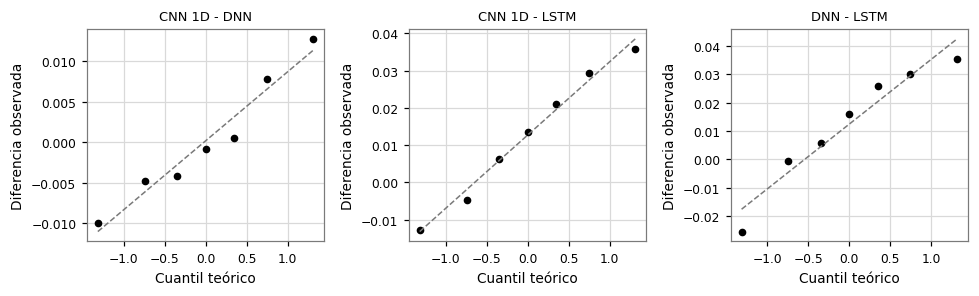

,Par,"Shapiro-Wilk, W","Shapiro-Wilk, p",Prueba elegida
0,CNN 1D - DNN,0.9551,0.7754,t pareada
1,CNN 1D - LSTM,0.9703,0.9006,t pareada
2,DNN - LSTM,0.9326,0.5734,t pareada


**Interpretación.** Shapiro-Wilk no rechaza la normalidad en ninguno de los pares, y los gráficos Q-Q permiten verificar si las diferencias se apartan de la recta. La prueba de Brown-Forsythe da p = 0,865 para la igualdad de varianzas entre modelos.

Hay que tener en cuenta que con 7 observaciones estas pruebas tienen poca potencia, de modo que no rechazar la normalidad no la demuestra. Además, las semillas comparten el conjunto de prueba, por lo que la independencia se cumple solo respecto a la inicialización y al orden de los lotes, y no respecto a la muestra de datos.

Por lo anterior, se aplica la regla declarada para cada par y se reportan siempre las dos pruebas, además del *bootstrap* pareado, de modo que la conclusión no dependa de un único supuesto.

In [34]:
if hay_resultados:
    PARES = [(NOMBRES[i], NOMBRES[j]) for i in range(len(NOMBRES)) for j in range(i + 1, len(NOMBRES))]
    fig, ejes = plt.subplots(1, len(PARES), figsize=(3 * len(PARES), 2.8))
    filas_supuestos = []
    for eje, (a, b) in zip(np.atleast_1d(ejes), PARES):
        d = (MATRIZ_F1[a] - MATRIZ_F1[b]).to_numpy()
        (teoricos, ordenados), (pendiente, intercepto, _) = stats.probplot(d, dist="norm")
        eje.plot(teoricos, ordenados, "o", color=NEGRO, markersize=4)
        eje.plot(teoricos, pendiente * teoricos + intercepto, color=GRIS_MEDIO, linestyle="--", linewidth=1)
        eje.set(title=f"{a} - {b}", xlabel="Cuantil teórico", ylabel="Diferencia observada")
        eje.title.set_size(8.5)
        prueba_normal = stats.shapiro(d)
        filas_supuestos.append({"Par": f"{a} - {b}", "Shapiro-Wilk, W": prueba_normal.statistic, "Shapiro-Wilk, p": prueba_normal.pvalue, "Prueba elegida": "t pareada" if prueba_normal.pvalue >= ALFA else "Wilcoxon"})
    plt.tight_layout()
    plt.show()
    SUPUESTOS = pd.DataFrame(filas_supuestos)
    display(SUPUESTOS.round(4))
    brown_forsythe = stats.levene(*[MATRIZ_F1[n] for n in NOMBRES], center="median")
    rechazados = SUPUESTOS.loc[SUPUESTOS["Shapiro-Wilk, p"] < ALFA, "Par"].tolist()
    interpretar(f'''**Interpretación.** Shapiro-Wilk {"no rechaza la normalidad en ninguno de los pares" if not rechazados else "rechaza la normalidad en " + ", ".join(rechazados)}, y los gráficos Q-Q permiten verificar si las diferencias se apartan de la recta. La prueba de Brown-Forsythe da {valor_p(brown_forsythe.pvalue)} para la igualdad de varianzas entre modelos.

Hay que tener en cuenta que con {len(SEMILLAS)} observaciones estas pruebas tienen poca potencia, de modo que no rechazar la normalidad no la demuestra. Además, las semillas comparten el conjunto de prueba, por lo que la independencia se cumple solo respecto a la inicialización y al orden de los lotes, y no respecto a la muestra de datos.

Por lo anterior, se aplica la regla declarada para cada par y se reportan siempre las dos pruebas, además del *bootstrap* pareado, de modo que la conclusión no dependa de un único supuesto.''')

In [35]:
def comparar_par(a, b, repeticiones=10000):
    a, b = np.asarray(a), np.asarray(b)
    d = a - b
    n, media, sd = len(d), d.mean(), d.std(ddof=1)
    error = sd / np.sqrt(n)
    margen = stats.t.ppf(0.975, n - 1) * error
    # Con varianza nula, la diferencia es exacta: solo hay evidencia si además es distinta de cero
    t_valor, p_t = stats.ttest_rel(a, b) if sd > 0 else (0.0, 1.0) if media == 0 else (np.inf, 0.0)
    p_w = stats.wilcoxon(d, alternative="two-sided").pvalue if np.any(d != 0) else 1.0
    rng = np.random.default_rng(42)
    muestras = d[rng.integers(0, n, (repeticiones, n))]
    ic_media = np.percentile(muestras.mean(1), [2.5, 97.5])
    desviaciones = muestras.std(1, ddof=1)
    efectos = np.divide(muestras.mean(1), desviaciones, out=np.full(repeticiones, np.nan), where=desviaciones > 0)
    ic_efecto = np.nanpercentile(efectos, [2.5, 97.5])
    rangos = rankdata(np.abs(d[d != 0]))
    r_biserial = (rangos[d[d != 0] > 0].sum() - rangos[d[d != 0] < 0].sum()) / rangos.sum() if rangos.size else 0.0
    cliff = np.sign(np.subtract.outer(a, b)).mean()
    # Prueba de equivalencia TOST con el margen declarado a priori
    p_tost = max(stats.t.sf((media + DELTA) / error, n - 1), stats.t.cdf((media - DELTA) / error, n - 1)) if sd > 0 else float(abs(media) >= DELTA)
    return {"Diferencia media": media, "IC 95 % t": (media - margen, media + margen), "IC 95 % bootstrap": tuple(ic_media), "t": t_valor, "p t pareada": p_t, "p Wilcoxon": p_w, "d de Cohen pareada": media / sd if sd > 0 else 0.0 if media == 0 else np.inf,
            "IC 95 % de d": tuple(ic_efecto), "r biserial": r_biserial, "δ de Cliff": cliff, "P. de superioridad": (d > 0).mean() + 0.5 * (d == 0).mean(), "p TOST": p_tost, "Potencia para δ": potencia_pareada(sd, n, DELTA), "Mínima detectable": minima_detectable(sd, n) if sd > 0 else 0.0}


def anova_repetidas(M):
    n, k = M.shape
    gran = M.mean()
    ss_modelo = n * ((M.mean(0) - gran) ** 2).sum()
    ss_semilla = k * ((M.mean(1) - gran) ** 2).sum()
    ss_error = ((M - gran) ** 2).sum() - ss_modelo - ss_semilla
    gl_modelo, gl_error = k - 1, (k - 1) * (n - 1)
    f = (ss_modelo / gl_modelo) / (ss_error / gl_error)
    centro = np.eye(k) - 1 / k
    doble = centro @ np.cov(M, rowvar=False) @ centro
    epsilon = np.trace(doble) ** 2 / ((k - 1) * (doble ** 2).sum())
    return {"F": f, "gl modelo": gl_modelo, "gl error": gl_error, "épsilon GG": epsilon, "p sin corregir": stats.f.sf(f, gl_modelo, gl_error), "p GG": stats.f.sf(f, gl_modelo * epsilon, gl_error * epsilon),
            "η² parcial": ss_modelo / (ss_modelo + ss_error), "ss": {"Modelo": ss_modelo, "Semilla": ss_semilla, "Residuo": ss_error}}


def nemenyi(M):
    n, k = M.shape
    rangos = np.apply_along_axis(lambda f: rankdata(-f), 1, M).mean(0)
    escala = np.sqrt(k * (k + 1) / (6 * n))
    valores = []
    for i in range(k):
        for j in range(i + 1, k):
            valores.append(studentized_range.sf(abs(rangos[i] - rangos[j]) / escala * np.sqrt(2), k, np.inf))
    return rangos, valores, studentized_range.ppf(0.95, k, np.inf) / np.sqrt(2) * escala


if hay_resultados:
    resultados_pares = {f"{a} - {b}": comparar_par(MATRIZ_F1[a], MATRIZ_F1[b]) for a, b in PARES}
    elegida = dict(zip(SUPUESTOS["Par"], SUPUESTOS["Prueba elegida"]))
    p_elegidos = np.array([resultados_pares[par]["p t pareada" if elegida[par] == "t pareada" else "p Wilcoxon"] for par in resultados_pares])
    p_holm = multipletests(p_elegidos, alpha=ALFA, method="holm")[1]
    p_holm_t = multipletests([r["p t pareada"] for r in resultados_pares.values()], alpha=ALFA, method="holm")[1]
    p_holm_w = multipletests([r["p Wilcoxon"] for r in resultados_pares.values()], alpha=ALFA, method="holm")[1]
    tabla_pares = pd.DataFrame([{"Par": par, "Diferencia media": round(r["Diferencia media"], 5), "IC 95 % t": f"[{num(r['IC 95 % t'][0], 4)}; {num(r['IC 95 % t'][1], 4)}]", "IC 95 % bootstrap": f"[{num(r['IC 95 % bootstrap'][0], 4)}; {num(r['IC 95 % bootstrap'][1], 4)}]",
                                 "Prueba elegida": elegida[par], "p sin ajustar": p_exacto(p), "p Holm": p_exacto(h), "p t": p_exacto(r["p t pareada"]), "p t Holm": p_exacto(ht), "p Wilcoxon": p_exacto(r["p Wilcoxon"]), "p Wilcoxon Holm": p_exacto(hw),
                                 "d de Cohen pareada": round(r["d de Cohen pareada"], 3), "IC 95 % de d": f"[{num(r['IC 95 % de d'][0], 2)}; {num(r['IC 95 % de d'][1], 2)}]", "r biserial": round(r["r biserial"], 3), "δ de Cliff": round(r["δ de Cliff"], 3), "P. de superioridad": round(r["P. de superioridad"], 3),
                                 "Potencia para δ": round(r["Potencia para δ"], 3), "Mínima detectable": round(r["Mínima detectable"], 5), "p TOST": p_exacto(r["p TOST"])} for (par, r), p, h, ht, hw in zip(resultados_pares.items(), p_elegidos, p_holm, p_holm_t, p_holm_w)]).set_index("Par").T
    display(tabla_pares)
    tabla_pares.to_csv(RESULTADOS / "comparaciones_pareadas.csv")

    M = MATRIZ_F1.to_numpy()
    anova = anova_repetidas(M)
    friedman = stats.friedmanchisquare(*M.T)
    kendall = friedman.statistic / (M.shape[0] * (M.shape[1] - 1))
    rangos_medios, p_nemenyi, distancia_critica = nemenyi(M)
    display(pd.DataFrame({"Prueba": ["ANOVA de medidas repetidas (Greenhouse-Geisser)", "Friedman"], "Estadístico": [round(anova["F"], 3), round(friedman.statistic, 3)], "p": [p_exacto(anova["p GG"]), p_exacto(friedman.pvalue)],
                          "Tamaño de efecto": [f"η² parcial = {num(anova['η² parcial'], 3)}", f"W de Kendall = {num(kendall, 3)}"]}).style.hide(axis="index"))
    display(pd.DataFrame({"Par": list(resultados_pares), "Diferencia de rangos": [abs(rangos_medios[i] - rangos_medios[j]) for i in range(3) for j in range(i + 1, 3)], "p Nemenyi": [p_exacto(v) for v in p_nemenyi]}).style.hide(axis="index"))
    ss_total = sum(anova["ss"].values())
    varianza = pd.DataFrame({"Suma de cuadrados": anova["ss"], "Porcentaje": {k: 100 * v / ss_total for k, v in anova["ss"].items()}})
    display(varianza.round(6))

    significativos = [par for par, h in zip(resultados_pares, p_holm) if h < ALFA]
    relevantes = [par for par in resultados_pares if abs(resultados_pares[par]["Diferencia media"]) >= DELTA]
    equivalentes = [par for par in resultados_pares if resultados_pares[par]["p TOST"] < ALFA]
    inciertos = [par for par in relevantes if par not in significativos]
    if not equivalentes:
        texto_equivalencia = "ningún par se puede declarar equivalente"
    else:
        texto_equivalencia = ("se declara equivalente, dentro de ±δ, el par " if len(equivalentes) == 1 else "se declaran equivalentes, dentro de ±δ, los pares ") + enumerar(equivalentes)
        if all(resultados_pares[par]["p TOST"] * 3 < ALFA for par in equivalentes):
            texto_equivalencia += ", conclusión que se mantiene al multiplicar el valor p por las tres comparaciones"
    p_min_wilcoxon = 2 / 2 ** len(SEMILLAS)
    interpretar(f'''**Interpretación.** Tras la corrección de Holm (1979), {"ningún par difiere de forma significativa" if not significativos else "difieren de forma significativa " + enumerar(significativos)}. La ANOVA de medidas repetidas da $F$ = {num(anova["F"], 2)} con {valor_p(anova["p GG"])} tras la corrección de Greenhouse-Geisser, y la prueba de Friedman (1937) da χ² = {num(friedman.statistic, 2)} con {valor_p(friedman.pvalue)} y una W de Kendall de {num(kendall, 3)}; la distancia crítica de Nemenyi es de {num(distancia_critica, 2)} rangos (Demšar, 2006). En la descomposición de la varianza, el modelo explica el {num(varianza.loc["Modelo", "Porcentaje"], 1)} %, la semilla el {num(varianza.loc["Semilla", "Porcentaje"], 1)} % y el residuo el {num(varianza.loc["Residuo", "Porcentaje"], 1)} %.

Es decir, hay que distinguir dos preguntas. En significancia estadística, {"no hay evidencia de que algún par difiera" if not significativos else "hay evidencia de diferencia en " + enumerar(significativos)}. En relevancia práctica, {"ninguna diferencia media alcanza" if not relevantes else "la diferencia media de " + enumerar(relevantes) + " supera"} δ = {num(DELTA, 2)}{"" if not inciertos else f", pero sin significancia y con una potencia que va de {num(min(resultados_pares[par]['Potencia para δ'] for par in inciertos), 2)} a {num(max(resultados_pares[par]['Potencia para δ'] for par in inciertos), 2)}, de modo que el resultado en esos pares es no concluyente"}. La equivalencia se evalúa aparte con TOST (Schuirmann, 1987): {texto_equivalencia}. Así mismo, con {len(SEMILLAS)} pares el valor p mínimo de Wilcoxon es {num(p_min_wilcoxon, 4)}, de modo que {"esta prueba no podría superar el nivel más exigente de Holm, α/3 = 0,0167" if p_min_wilcoxon > ALFA / 3 else "esta prueba sí puede superar el nivel más exigente de Holm, α/3 = 0,0167"}.

Por tanto, corresponde apoyar la decisión en la diferencia media con su intervalo y en el tamaño de efecto, y no solo en el valor p. Una ausencia de significancia no se interpreta como equivalencia.''')

Par,CNN 1D - DNN,CNN 1D - LSTM,DNN - LSTM
Diferencia media,0.00018,0.01267,0.01249
IC 95 % t,"[-0,0070; 0,0074]","[-0,0037; 0,0291]","[-0,0071; 0,0321]"
IC 95 % bootstrap,"[-0,0049; 0,0057]","[0,0005; 0,0247]","[-0,0030; 0,0257]"
Prueba elegida,t pareada,t pareada,t pareada
p sin ajustar,0.95379,0.10764,0.16962
p Holm,0.95379,0.32291,0.33923
p t,0.95379,0.10764,0.16962
p t Holm,0.95379,0.32291,0.33923
p Wilcoxon,0.93750,0.10938,0.15625
p Wilcoxon Holm,0.93750,0.32812,0.32812


Prueba,Estadístico,p,Tamaño de efecto
ANOVA de medidas repetidas (Greenhouse-Geisser),2.690000,0.14306,"η² parcial = 0,310"
Friedman,2.000000,0.36788,"W de Kendall = 0,143"


Par,Diferencia de rangos,p Nemenyi
CNN 1D - DNN,0.142857,0.96139
CNN 1D - LSTM,0.571429,0.53334
DNN - LSTM,0.714286,0.37498


,Suma de cuadrados,Porcentaje
Modelo,0.000738,24.271070
Semilla,0.000657,21.597149
Residuo,0.001647,54.131781


**Interpretación.** Tras la corrección de Holm (1979), ningún par difiere de forma significativa. La ANOVA de medidas repetidas da $F$ = 2,69 con p = 0,143 tras la corrección de Greenhouse-Geisser, y la prueba de Friedman (1937) da χ² = 2,00 con p = 0,368 y una W de Kendall de 0,143; la distancia crítica de Nemenyi es de 1,25 rangos (Demšar, 2006). En la descomposición de la varianza, el modelo explica el 24,3 %, la semilla el 21,6 % y el residuo el 54,1 %.

Es decir, hay que distinguir dos preguntas. En significancia estadística, no hay evidencia de que algún par difiera. En relevancia práctica, la diferencia media de CNN 1D - LSTM y DNN - LSTM supera δ = 0,01, pero sin significancia y con una potencia que va de 0,18 a 0,24, de modo que el resultado en esos pares es no concluyente. La equivalencia se evalúa aparte con TOST (Schuirmann, 1987): se declara equivalente, dentro de ±δ, el par CNN 1D - DNN, conclusión que se mantiene al multiplicar el valor p por las tres comparaciones. Así mismo, con 7 pares el valor p mínimo de Wilcoxon es 0,0156, de modo que esta prueba sí puede superar el nivel más exigente de Holm, α/3 = 0,0167.

Por tanto, corresponde apoyar la decisión en la diferencia media con su intervalo y en el tamaño de efecto, y no solo en el valor p. Una ausencia de significancia no se interpreta como equivalencia.

In [36]:
def delong(verdad, puntaje_a, puntaje_b):
    m, n = int(verdad.sum()), int((~verdad).sum())
    componentes = []
    for puntaje in (puntaje_a, puntaje_b):
        pos, neg = puntaje[verdad], puntaje[~verdad]
        tx, ty = rankdata(pos), rankdata(neg)
        tz = rankdata(np.concatenate([pos, neg]))
        componentes.append(((tz[:m].sum() - m * (m + 1) / 2) / (m * n), (tz[:m] - tx) / n, 1 - (tz[m:] - ty) / m))
    (auc_a, v10_a, v01_a), (auc_b, v10_b, v01_b) = componentes
    cov_10, cov_01 = np.cov(v10_a, v10_b), np.cov(v01_a, v01_b)
    varianza = (cov_10[0, 0] + cov_10[1, 1] - 2 * cov_10[0, 1]) / m + (cov_01[0, 0] + cov_01[1, 1] - 2 * cov_01[0, 1]) / n
    return auc_a - auc_b, 2 * stats.norm.sf(abs(auc_a - auc_b) / np.sqrt(varianza)) if varianza > 0 else 1.0


def f1_macro_rapido(verdad, prediccion, k=len(CLASES)):
    confusion = np.bincount(k * verdad + prediccion, minlength=k * k).reshape(k, k)
    return np.mean(2 * np.diag(confusion) / np.maximum(confusion.sum(0) + confusion.sum(1), 1))


if hay_resultados:
    filas_mcnemar, filas_delong = [], []
    for a, b in PARES:
        p_mcnemar, discordantes, diferencias_exactitud, pruebas_delong = [], [], [], []
        for s in SEMILLAS:
            pa, pb = PROBABILIDADES[(a, s)], PROBABILIDADES[(b, s)]
            acierto_a, acierto_b = pa.argmax(1) == y_prueba, pb.argmax(1) == y_prueba
            n01, n10 = int((acierto_a & ~acierto_b).sum()), int((~acierto_a & acierto_b).sum())
            tabla = [[int((acierto_a & acierto_b).sum()), n01], [n10, int((~acierto_a & ~acierto_b).sum())]]
            p_mcnemar.append(mcnemar(tabla, exact=n01 + n10 < 25, correction=True).pvalue)
            discordantes.append(n01 + n10)
            diferencias_exactitud.append(acierto_a.mean() - acierto_b.mean())
            pruebas_delong.append([delong(y_prueba == c, pa[:, c], pb[:, c]) for c in range(len(CLASES))])
        pruebas_delong = np.array(pruebas_delong)
        ajustados = np.array([multipletests(fila, method="holm")[1] for fila in pruebas_delong[:, :, 1]])
        filas_mcnemar.append({"Par": f"{a} - {b}", "Diferencia media de accuracy": np.mean(diferencias_exactitud), "Discordantes (media)": np.mean(discordantes), "p de McNemar (mediana)": p_exacto(np.median(p_mcnemar)), "p mínimo": p_exacto(np.min(p_mcnemar)), "p máximo": p_exacto(np.max(p_mcnemar)),
                              "Semillas con p Holm < 0,05": f"{int((multipletests(p_mcnemar, method='holm')[1] < ALFA).sum())} de {len(SEMILLAS)}"})
        filas_delong.append({"Par": f"{a} - {b}", "Diferencia media de AUC por clase": pruebas_delong[:, :, 0].mean(), "Clase × semilla con p Holm < 0,05": f"{int((ajustados < ALFA).sum())} de {ajustados.size}", "p DeLong (mediana)": p_exacto(np.median(pruebas_delong[:, :, 1]))})
    TABLA_MCNEMAR, TABLA_DELONG = pd.DataFrame(filas_mcnemar), pd.DataFrame(filas_delong)
    display(TABLA_MCNEMAR.round(5).style.hide(axis="index"))
    display(TABLA_DELONG.round(5).style.hide(axis="index"))

    # Bootstrap estratificado por clase sobre el conjunto de prueba: captura la incertidumbre por la muestra de datos
    rng = np.random.default_rng(42)
    posiciones = [np.where(y_prueba == c)[0] for c in range(len(CLASES))]
    REPETICIONES_PRUEBA = 1000
    predicciones = {n: np.stack([PROBABILIDADES[(n, s)].argmax(1) for s in SEMILLAS]) for n in NOMBRES}
    distribucion = {n: np.empty(REPETICIONES_PRUEBA) for n in NOMBRES}
    for repeticion in range(REPETICIONES_PRUEBA):
        muestra = np.concatenate([rng.choice(p, len(p), replace=True) for p in posiciones])
        for n in NOMBRES:
            distribucion[n][repeticion] = np.mean([f1_macro_rapido(y_prueba[muestra], fila[muestra]) for fila in predicciones[n]])
    limites = {f"{a} - {b}": np.percentile(distribucion[a] - distribucion[b], [2.5, 97.5]) for a, b in PARES}

    # Remuestreo por bloques: respeta la unidad de independencia, y se estratifica por la clase dominante de cada bloque
    bloques_prueba = (datos["FlowID"].to_numpy()[particion["prueba"]] - 1) // int(preparados["largo_bloque"])
    dominante = pd.Series(y_prueba).groupby(bloques_prueba).agg(lambda s: s.value_counts().index[0])
    posiciones_bloque = {b: np.where(bloques_prueba == b)[0] for b in dominante.index}
    estratos = [dominante.index[dominante == c].to_numpy() for c in range(len(CLASES)) if (dominante == c).any()]
    distribucion_bloques = {n: np.empty(REPETICIONES_PRUEBA) for n in NOMBRES}
    for repeticion in range(REPETICIONES_PRUEBA):
        muestra = np.concatenate([posiciones_bloque[b] for estrato in estratos for b in rng.choice(estrato, len(estrato), replace=True)])
        for n in NOMBRES:
            distribucion_bloques[n][repeticion] = np.mean([f1_macro_rapido(y_prueba[muestra], fila[muestra]) for fila in predicciones[n]])
    limites_bloques = {f"{a} - {b}": np.percentile(distribucion_bloques[a] - distribucion_bloques[b], [2.5, 97.5]) for a, b in PARES}
    TABLA_BOOTSTRAP = pd.DataFrame([{"Par": par, "Diferencia de F1 macro": float(np.mean(distribucion[par.split(" - ")[0]] - distribucion[par.split(" - ")[1]])), "IC 95 % por filas": f"[{num(l[0], 4)}; {num(l[1], 4)}]", "IC 95 % por bloques": f"[{num(limites_bloques[par][0], 4)}; {num(limites_bloques[par][1], 4)}]"} for par, l in limites.items()])
    display(TABLA_BOOTSTRAP.round(5).style.hide(axis="index"))
    ic_baseline = np.percentile(distribucion[BASELINE], [2.5, 97.5])
    ic_baseline_bloques = np.percentile(distribucion_bloques[BASELINE], [2.5, 97.5])
    sin_cero = [par for par, l in limites.items() if not l[0] <= 0 <= l[1]]
    sin_cero_bloques = [par for par, l in limites_bloques.items() if not l[0] <= 0 <= l[1]]
    interpretar(f'''**Interpretación.** Estas pruebas trabajan con cada observación de prueba, no con cada semilla. McNemar (1947) compara las tasas de error mediante los casos discordantes, $\\chi^2 = (|n_{{01}} - n_{{10}}| - 1)^2 / (n_{{01}} + n_{{10}})$, con su versión exacta si hay menos de 25, y DeLong et al. (1988) compara las curvas ROC correlacionadas. Como el problema es multiclase, DeLong se aplica uno contra el resto, por clase, con corrección de Holm dentro de cada semilla. Como cada semilla entrega una prueba, se reporta la mediana y el rango de los valores p. El *bootstrap* estratificado por clase (Efron y Tibshirani, 1993), con {REPETICIONES_PRUEBA} remuestreos de las filas de prueba, da para el baseline un IC 95 % de [{num(ic_baseline[0], 4)}; {num(ic_baseline[1], 4)}]{", y el intervalo de la diferencia excluye el cero en " + enumerar(sin_cero) if sin_cero else ", y ningún intervalo de diferencia excluye el cero"}. Como las filas de un bloque no son independientes, el remuestreo se repite con los {len(dominante)} bloques de prueba, dentro de su clase dominante, y el IC 95 % del baseline pasa a [{num(ic_baseline_bloques[0], 4)}; {num(ic_baseline_bloques[1], 4)}]{", con un intervalo de la diferencia que excluye el cero en " + enumerar(sin_cero_bloques) if sin_cero_bloques else ", y ningún intervalo de diferencia excluye el cero"}.

Hay que tener en cuenta que, con unas {num(len(y_prueba), 0)} observaciones, McNemar y DeLong detectan diferencias muy pequeñas, de modo que un valor p bajo aquí no implica relevancia práctica. Además, ambas pruebas y el *bootstrap* por filas suponen observaciones independientes, algo que la sección 2.1.3 descarta, de modo que sus valores p y sus intervalos resultan optimistas. Por eso, el remuestreo por bloques es el que mejor mide lo que las semillas no miden, cuánto cambiaría la diferencia con otra muestra de bloques, aunque con tan pocos bloques su intervalo es solo aproximado.

Así las cosas, se decide reportar McNemar y DeLong como pide el enunciado, pero solo como apoyo, sin basar en ellas ninguna afirmación de superioridad, y juzgar la relevancia siempre contra δ = {num(DELTA, 2)}.''')

Par,Diferencia media de accuracy,Discordantes (media),p de McNemar (mediana),p mínimo,p máximo,"Semillas con p Holm < 0,05"
CNN 1D - DNN,0.000310,1003.571430,6.94e-06,3.09e-18,0.80453,5 de 7
CNN 1D - LSTM,0.010860,1680.857140,2.71e-12,4.44e-79,0.00038,7 de 7
DNN - LSTM,0.010560,1695.857140,2.17e-31,1.63e-74,0.32314,6 de 7


Par,Diferencia media de AUC por clase,"Clase × semilla con p Holm < 0,05",p DeLong (mediana)
CNN 1D - DNN,0.003480,30 de 35,8.11e-20
CNN 1D - LSTM,-0.009190,32 de 35,4.05e-28
DNN - LSTM,-0.012670,31 de 35,5.55e-34


Par,Diferencia de F1 macro,IC 95 % por filas,IC 95 % por bloques
CNN 1D - DNN,0.000180,"[-0,0014; 0,0017]","[-0,0082; 0,0076]"
CNN 1D - LSTM,0.012590,"[0,0104; 0,0147]","[-0,0011; 0,0270]"
DNN - LSTM,0.012400,"[0,0100; 0,0149]","[-0,0058; 0,0326]"


**Interpretación.** Estas pruebas trabajan con cada observación de prueba, no con cada semilla. McNemar (1947) compara las tasas de error mediante los casos discordantes, $\chi^2 = (|n_{01} - n_{10}| - 1)^2 / (n_{01} + n_{10})$, con su versión exacta si hay menos de 25, y DeLong et al. (1988) compara las curvas ROC correlacionadas. Como el problema es multiclase, DeLong se aplica uno contra el resto, por clase, con corrección de Holm dentro de cada semilla. Como cada semilla entrega una prueba, se reporta la mediana y el rango de los valores p. El *bootstrap* estratificado por clase (Efron y Tibshirani, 1993), con 1000 remuestreos de las filas de prueba, da para el baseline un IC 95 % de [0,8508; 0,8588], y el intervalo de la diferencia excluye el cero en CNN 1D - LSTM y DNN - LSTM. Como las filas de un bloque no son independientes, el remuestreo se repite con los 24 bloques de prueba, dentro de su clase dominante, y el IC 95 % del baseline pasa a [0,7661; 0,9182], y ningún intervalo de diferencia excluye el cero.

Hay que tener en cuenta que, con unas 22 883 observaciones, McNemar y DeLong detectan diferencias muy pequeñas, de modo que un valor p bajo aquí no implica relevancia práctica. Además, ambas pruebas y el *bootstrap* por filas suponen observaciones independientes, algo que la sección 2.1.3 descarta, de modo que sus valores p y sus intervalos resultan optimistas. Por eso, el remuestreo por bloques es el que mejor mide lo que las semillas no miden, cuánto cambiaría la diferencia con otra muestra de bloques, aunque con tan pocos bloques su intervalo es solo aproximado.

Así las cosas, se decide reportar McNemar y DeLong como pide el enunciado, pero solo como apoyo, sin basar en ellas ninguna afirmación de superioridad, y juzgar la relevancia siempre contra δ = 0,01.

#### Validación cruzada repetida

Las semillas sobre una partición fija no miden la variabilidad que proviene de la selección de los datos. Por eso, como recomienda el enunciado, se agrega una validación cruzada repetida 5 × 5, agrupada por bloques y solo con entrenamiento y validación, de modo que la prueba sigue congelada. En cada pliegue, la transformación y los pesos de clase se ajustan con la parte de entrenamiento, y un 20 % de esa parte se usa para la parada temprana. Las diferencias pareadas se prueban con la corrección de varianza de Nadeau y Bengio (2003), $t = \bar{d} \,/\, \sqrt{\left(\frac{1}{kr} + \frac{n_2}{n_1}\right) \hat{\sigma}_d^2}$, porque los pliegues comparten datos de entrenamiento y la prueba sin corregir sería demasiado optimista.

In [37]:
REPETICIONES_CV, PLIEGUES_CV = 5, 5
RUTA_CV = RESULTADOS / "validacion_repetida.csv"
if hay_resultados:
    hiper = preregistro["hiperparametros"]
    largo = int(preparados["largo_bloque"])
    id_dev_np = np.concatenate([particion["entrenamiento"], particion["validacion"]])
    X_guardada, PESOS_GUARDADOS = X, PESOS
    X_log = torch.from_numpy(preparados["X"].astype(np.float64) * preparados["desviacion"] + preparados["media"]).float()
    hechas = pd.read_csv(RUTA_CV).to_dict("records") if RUTA_CV.exists() else []
    ya = {(f["Repetición"], f["Pliegue"], f["Modelo"]) for f in hechas}
    for rep in range(REPETICIONES_CV):
        pliegues = StratifiedGroupKFold(PLIEGUES_CV, shuffle=True, random_state=3000 + rep)
        for k, (pos_ajuste, pos_fuera) in enumerate(pliegues.split(id_dev_np, y_np[id_dev_np], id_dev_np // largo)):
            if all((rep, k, n) in ya for n in MODELOS):
                continue
            ajuste, fuera = id_dev_np[pos_ajuste], id_dev_np[pos_fuera]
            pos_a, pos_b = next(StratifiedGroupKFold(5, shuffle=True, random_state=3000 + rep).split(ajuste, y_np[ajuste], ajuste // largo))
            ids_a, ids_b = torch.from_numpy(ajuste[pos_a]), torch.from_numpy(ajuste[pos_b])
            X = (X_log - X_log[ids_a].mean(0)) / X_log[ids_a].std(0)
            frecuencia_k = np.bincount(y_np[ajuste[pos_a]], minlength=N_CLASES)
            PESOS = torch.from_numpy((frecuencia_k.sum() / (N_CLASES * frecuencia_k)).astype(np.float32))
            for nombre in MODELOS:
                if (rep, k, nombre) in ya:
                    continue
                modelo, _ = entrenar(nombre, hiper[nombre], 3000 + 100 * rep + k, ids_a, ids_b)
                pred_fuera = predecir(modelo, torch.from_numpy(fuera)).argmax(1).numpy()
                hechas.append({"Repetición": rep, "Pliegue": k, "Modelo": nombre, "F1 macro": f1_score(y_np[fuera], pred_fuera, average="macro", zero_division=0), "n ajuste": len(ajuste), "n fuera": len(fuera)})
                pd.DataFrame(hechas).to_csv(RUTA_CV, index=False)
            print(f"Validación repetida: repetición {rep + 1}, pliegue {k + 1}", flush=True)
    X, PESOS = X_guardada, PESOS_GUARDADOS
    cv = pd.DataFrame(hechas)
    matriz_cv = cv.pivot_table(index=["Repetición", "Pliegue"], columns="Modelo", values="F1 macro")[NOMBRES]
    n1_cv, n2_cv, kr = cv["n ajuste"].mean(), cv["n fuera"].mean(), len(matriz_cv)
    filas_cv = []
    for i in range(len(NOMBRES)):
        for j in range(i + 1, len(NOMBRES)):
            d_cv = matriz_cv[NOMBRES[i]] - matriz_cv[NOMBRES[j]]
            error_cv = np.sqrt((1 / kr + n2_cv / n1_cv) * d_cv.var(ddof=1))
            t_cv = d_cv.mean() / error_cv if error_cv > 0 else 0.0
            margen_cv = stats.t.ppf(0.975, kr - 1) * error_cv
            filas_cv.append({"Par": f"{NOMBRES[i]} - {NOMBRES[j]}", "Diferencia media": d_cv.mean(), "IC 95 % corregido": f"[{num(d_cv.mean() - margen_cv, 4)}; {num(d_cv.mean() + margen_cv, 4)}]", "t corregida": t_cv, "p sin ajustar": 2 * stats.t.sf(abs(t_cv), kr - 1), "P. de superioridad": (d_cv > 0).mean() + 0.5 * (d_cv == 0).mean()})
    tabla_cv = pd.DataFrame(filas_cv)
    tabla_cv["p Holm"] = multipletests(tabla_cv["p sin ajustar"], method="holm")[1]
    resumen_cv = matriz_cv.agg(["mean", "std"]).T
    display(resumen_cv.rename(columns={"mean": "F1 macro medio", "std": "Desviación"}).round(4))
    display(tabla_cv.style.hide(axis="index").format({"Diferencia media": "{:.4f}", "t corregida": "{:.3f}", "p sin ajustar": p_exacto, "p Holm": p_exacto, "P. de superioridad": "{:.2f}"}))
    tabla_cv.to_csv(RESULTADOS / "comparaciones_validacion_repetida.csv", index=False)
    significativos_cv = tabla_cv.loc[tabla_cv["p Holm"] < ALFA, "Par"].tolist()
    interpretar(f'''**Interpretación.** Con {kr} pliegues, el F1 macro medio va de {num(resumen_cv["mean"].min(), 4)} a {num(resumen_cv["mean"].max(), 4)}, y la desviación entre pliegues llega a {num(resumen_cv["std"].max(), 4)}, mayor que la que producen las semillas sobre una partición fija, porque aquí también cambian los datos. Con la corrección de Nadeau y Bengio (2003), {"ningún par difiere de forma significativa" if not significativos_cv else "difieren de forma significativa: " + ", ".join(significativos_cv)} tras el ajuste de Holm.

Esto significa que la incertidumbre por la selección de los bloques pesa más que la de la inicialización. En ese sentido, una diferencia que parece clara entre semillas puede no sostenerse cuando cambia el conjunto de datos, y por eso esta prueba es la más exigente del estudio. Hay que tener en cuenta que el estadístico corregido es conservador cuando los pliegues se solapan mucho.

Por tal motivo, se toma esta prueba como la referencia para afirmar que un modelo base supera a otro.''')

,F1 macro medio,Desviación
Modelo,,
CNN 1D,0.8888,0.0382
DNN,0.8811,0.0417
LSTM,0.8649,0.0491


Par,Diferencia media,IC 95 % corregido,t corregida,p sin ajustar,P. de superioridad,p Holm
CNN 1D - DNN,0.0077,"[-0,0082; 0,0236]",1.001,0.32697,0.76,0.65394
CNN 1D - LSTM,0.0239,"[-0,0058; 0,0536]",1.664,0.10919,0.84,0.32756
DNN - LSTM,0.0162,"[-0,0179; 0,0503]",0.979,0.33723,0.68,0.65394


**Interpretación.** Con 25 pliegues, el F1 macro medio va de 0,8649 a 0,8888, y la desviación entre pliegues llega a 0,0491, mayor que la que producen las semillas sobre una partición fija, porque aquí también cambian los datos. Con la corrección de Nadeau y Bengio (2003), ningún par difiere de forma significativa tras el ajuste de Holm.

Esto significa que la incertidumbre por la selección de los bloques pesa más que la de la inicialización. En ese sentido, una diferencia que parece clara entre semillas puede no sostenerse cuando cambia el conjunto de datos, y por eso esta prueba es la más exigente del estudio. Hay que tener en cuenta que el estadístico corregido es conservador cuando los pliegues se solapan mucho.

Por tal motivo, se toma esta prueba como la referencia para afirmar que un modelo base supera a otro.

### 5.5 Discusión crítica

Esta subsección responde las preguntas del enunciado con la evidencia de las secciones 4.4 y 5.1 a 5.4. El resultado central es que el estudio fija un baseline y un umbral, pero no permite ordenar con certeza a los tres modelos, porque dos de ellos son equivalentes en esta partición y el tercero queda en un resultado no concluyente.

**Qué modelo funciona mejor y por qué.** Por F1 macro, CNN 1D (0,8549) y DNN (0,8548) quedan empatadas, y LSTM queda por detrás (0,8423). CNN 1D es la primera y por eso es el baseline, como indica el enunciado, pero su ventaja de 0,0002 no tiene peso alguno: gana en 3 de las 7 semillas, y TOST declara equivalentes a los dos modelos dentro de ±0,01 (p = 0,0079). En sesgo inductivo, la convolución y la LSTM suponen que la posición en el vector tiene significado, mientras que aquí el orden es solo el de las columnas del archivo (sección 2.2.2). Que CNN 1D iguale a DNN con 3,1 veces sus parámetros sugiere que la localidad no aporta sobre las conexiones densas, y que LSTM quede atrás es coherente con que deba resumir en un estado de 64 unidades una secuencia de 16 pasos sin sentido temporal. En capacidad y regularización, LSTM es además el modelo más sensible a los hiperparámetros, con un rango de 0,073 en la búsqueda; su configuración elegida no tiene *dropout* ni *weight decay*, y muestra la mayor brecha entre entrenamiento y validación, 0,037 frente a 0,005 en CNN 1D y 0,001 en DNN. Hay que tener en cuenta que estas explicaciones son plausibles, pero no están demostradas, porque el diseño compara tres arquitecturas completas y no aísla cada factor.

El orden, además, depende de la métrica. LSTM, la última por F1 macro, obtiene el mayor AUC-ROC macro (0,9728, frente a 0,9637 en CNN 1D y 0,9602 en DNN), el mayor AUC-PR macro (0,8791, frente a 0,8511 y 0,8336) y el menor ECE (0,0402, frente a 0,0482 y 0,0520). Esto sugiere que ordena mejor las probabilidades, aunque decide peor al tomar la clase más probable, de modo que parte de su desventaja podría estar en la decisión y no en la discriminación.

**Qué modelo generaliza mejor.** Ninguno se distingue de forma concluyente. La brecha entre entrenamiento y prueba es casi la misma en los tres: 0,074 en CNN 1D y en DNN, y 0,071 en LSTM. En la validación repetida, CNN 1D tiene la mayor media y la menor dispersión (0,8888 ± 0,0382), seguida de DNN (0,8811 ± 0,0417) y de LSTM (0,8649 ± 0,0491), pero ningún par difiere tras el ajuste de Holm (p = 0,654, 0,328 y 0,654). Frente a un ruido gaussiano de σ = 0,5, con los pesos de la primera semilla, DNN es la que menos cae, 0,186, frente a 0,193 en LSTM y 0,202 en CNN 1D.

Lo que sí queda claro es que el F1 absoluto depende mucho de qué bloques se evalúan. CNN 1D y DNN pasan de 0,924 y 0,927 en validación a 0,855 en prueba, y esa caída no se explica solo por haber elegido la época y los hiperparámetros sobre validación, porque la regresión logística, que no elige nada sobre esa partición, cae todavía más, de 0,8803 a 0,7661. El boosting, en cambio, solo cae de 0,8875 a 0,8748. Una explicación posible, que este diseño no permite comprobar, es que los modelos que extrapolan sufren más con el desplazamiento de covariables de la sección 2.1.4, mientras que los árboles saturan fuera del rango visto. Así mismo, el remuestreo de los 24 bloques de prueba lleva el IC 95 % del baseline a [0,7661; 0,9182], y en la validación repetida el F1 macro de CNN 1D va de 0,8300 a 0,9649 entre pliegues. En ese sentido, el 0,8549 solo es comparable con otros modelos evaluados sobre esta misma partición.

**Si las diferencias son significativas y relevantes.** No hay evidencia estadística sólida de diferencias. La prueba $t$ pareada da valores p ajustados por Holm de 0,954, 0,323 y 0,339; la ANOVA de medidas repetidas da p = 0,143; Friedman, p = 0,368, y la validación repetida con la corrección de Nadeau y Bengio (2003) tampoco rechaza. El *bootstrap* pareado por semillas apenas excluye el cero en CNN 1D - LSTM, con [0,0005; 0,0247], pero sin ajuste por comparaciones múltiples y con solo 7 pares. McNemar, DeLong y el *bootstrap* por filas sí rechazan, y ninguno sostiene una afirmación de superioridad, porque suponen filas independientes: con el remuestreo por bloques, ningún intervalo excluye el cero.

En relevancia práctica, la situación cambia según el par. Entre CNN 1D y DNN, la diferencia de 0,0002 queda muy por debajo de δ = 0,01, con un intervalo por bloques de [-0,0082; 0,0076], contenido en ±δ. Sin embargo, esa equivalencia vale para esta partición, porque en la validación repetida, donde cambian los datos de entrenamiento, el intervalo de la diferencia es de [-0,0082; 0,0236] y no cabe en ±δ. En los dos pares con LSTM, la diferencia media, de 0,0127 y 0,0125, supera δ, pero sus intervalos $t$, [-0,0037; 0,0291] y [-0,0071; 0,0321], incluyen el cero, la potencia para δ es de solo 0,24 y 0,18, y tampoco son equivalentes según TOST (p = 0,648 y 0,617). Es decir, en esos pares el resultado es no concluyente: LSTM puede ser peor en una magnitud relevante, pero este diseño no lo demuestra.

**Si existe un *trade-off* entre desempeño y costo.** Sí, y favorece al modelo más simple. DNN iguala a CNN 1D con un tercio de sus parámetros (12 677 frente a 39 493), menos de la mitad del tiempo de entrenamiento (0,65 frente a 1,47 minutos por corrida) y una inferencia unas 41 veces más rápida (0,0007 frente a 0,0287 ms por muestra). LSTM es la más costosa de entrenar, con 2,30 minutos, sin que ese costo se refleje en el F1 macro. Por tal motivo, aunque CNN 1D sea el baseline por la regla del enunciado, DNN queda como la alternativa recomendada cuando importe el costo, por ejemplo, en un despliegue a bordo, teniendo en cuenta que estos tiempos se midieron en un solo equipo con CPU. Así mismo, el boosting, sin ajuste de hiperparámetros, supera al baseline en 0,0199 en este mismo conjunto de prueba, lo que indica que estas arquitecturas de Deep Learning no tienen aquí una ventaja ganada frente a un método clásico para datos tabulares.

**Baseline y umbral de mejora.** El baseline es CNN 1D, con F1 macro de 0,8549 ± 0,0091 e IC 95 % de [0,8466; 0,8633] entre semillas. Para ser una mejora distinguible y relevante, un modelo avanzado debe alcanzar un F1 macro medio de al menos 0,8775, es decir, 0,0226 por encima del baseline, evaluado con esta misma partición y con semillas pareadas. Ese umbral lo fija la mínima detectable, que con 7 semillas y $\hat{\sigma}_d$ = 0,0177 supera a δ = 0,01; con unas 27 semillas, el umbral podría bajar hasta cerca de 0,8649, y entonces lo fijaría la relevancia práctica. El margen teórico hasta un F1 perfecto es de 0,1451.

**Margen que sugiere la literatura y su credibilidad.** Los valores publicados sobre UAVIDS-2025 van de 0,9066 a 0,9428, entre 0,052 y 0,088 por encima del baseline. Esa brecha no es creíble como margen de mejora real, porque no compara lo mismo: esos estudios parten de forma aleatoria, lo que en la sección 2.1.3 sube el F1 macro de referencia en 0,0689, y Zarkadis y Douligeris (2026) codifican las direcciones IP, que aquí se excluyen por funcionar como atajo. Al descontar solo el efecto de la partición, la distancia frente a la CNN de Zeng et al. (2025), de 0,0751, queda en 0,0062, por debajo de δ, aunque ese descuento es aproximado, porque se midió con el boosting en validación. La evidencia más creíble es interna: el boosting sin ajuste queda 0,0199 por encima del baseline, a 0,0027 del umbral. Esto significa que el margen con respaldo hoy es del orden de 0,02, similar al umbral e inferior a la desviación de cerca de 0,04 entre pliegues, de modo que un modelo mejor puede no distinguirse si no se aumentan las semillas.

**Amenazas a la validez.**

- **Validez interna.** El archivo no identifica la simulación de origen, y la partición por bloques reduce esa fuga, pero no la elimina: `FlowID`, que no se usa como entrada, conserva un F1 macro de 0,859 con partición agrupada, porque los tramos de una sola clase son más largos que el bloque (sección 2.1.4), y el 1,8 % de las filas de prueba tiene un casi duplicado en entrenamiento. Si los atributos de tráfico delatan el tramo del archivo, el baseline sigue siendo optimista. La optimización desigual se evita con el mismo presupuesto de ajuste para los tres modelos (sección 4.2.3), aunque la búsqueda usa una sola semilla. La prueba no se usó para elegir hiperparámetros, y ni los modelos ni la partición cambiaron después de verla.
- **Validez externa.** Los flujos provienen de un solo simulador y de una sola configuración de radio y enrutamiento, sin drones reales. Por tanto, los resultados no se extienden a otros enjambres ni a capturas en campo, y los atributos de tráfico pueden reflejar parámetros de cada escenario y no solo el ataque (sección 2.1.4).
- **Validez de construcción.** El F1 macro pondera por igual las cinco clases, aunque la proporción de clases la definió quien construyó el archivo. La etiqueta corresponde al escenario y no a cada flujo, de modo que parte del error puede ser ruido de etiquetas (sección 2.1.2). Además, el orden de los modelos cambia entre el F1 macro y el AUC, de modo que la conclusión depende de la métrica; por esa razón, la métrica primaria se declaró a priori y se complementa con los resultados por clase, por tamaño de flujo y con las demás métricas declaradas.

**Limitaciones del estudio.** Se evalúa una sola partición de un solo conjunto de datos simulado, y las semillas solo miden la inicialización y el orden de los lotes. El piloto estimó la variabilidad en validación, con $\hat{\sigma}_d$ de 0,0068 a 0,0089, y en prueba resultó mayor, de 0,0078 a 0,0212, por lo que las 7 ejecuciones preregistradas solo dieron potencia suficiente para el par CNN 1D - DNN. Además, la revisión de literatura no incluye aún IEEE Xplore, Web of Science ni Scopus, y 137 de los 172 reportes elegibles no se recuperaron a texto completo (sección 3.1).

**Recomendaciones futuras.** Para el Entregable 2 se recomienda conservar `particion.npz`, el umbral de `baseline.json` y el mismo protocolo, y aumentar las semillas hasta unas 27 o, al menos, reportar la mínima detectable que resulte. Así mismo, conviene incluir arquitecturas pensadas para datos tabulares, que no supongan un orden entre atributos, y exigirles el resultado por clase, porque el mayor espacio de mejora está en separar los ataques entre sí: en CNN 1D, Normal ya alcanza un F1 de 0,9688, mientras que los cuatro ataques van de 0,8017 a 0,8517, con Blackhole predicho como Wormhole en el 17,6 % de sus muestras. También conviene revisar la decisión de LSTM con calibración sobre validación y evaluar el efecto de los pesos de clase, porque en Flooding, la clase con mayor peso (1,936), el recall de 0,9059 contrasta con una precision de 0,7209. Por último, para la validez externa hace falta obtener de los autores el identificador de simulación o probar el modelo con otro conjunto de datos de drones.
por tamaño de flujo y con las demás métricas declaradas.

## 6. Guía de procedimiento para clasificación con datos tabulares

El enunciado indica cómo proceder según el tipo de problema. La tabla contrasta cada punto de su guía para clasificación tabular con lo que se hace en este trabajo, y señala dónde se desarrolla.

| Aspecto | Guía del enunciado | Aplicación en este trabajo | Dónde |
|---|---|---|---|
| Partición | Estratificada por clase; agrupada si hay varios registros por entidad; validación cruzada anidada si el tamaño es reducido | Estratificada por clase y agrupada por bloques de filas; sin validación anidada, porque hay decenas de miles de flujos | Secciones 2.1.3 y 4.1 |
| Preprocesamiento | Imputación, escalado y codificación ajustados solo en entrenamiento; *embeddings* para categóricas de alta cardinalidad | No hace falta imputar; transformación y estandarización ajustadas solo en entrenamiento; las categóricas se excluyen, porque funcionan como atajos | Secciones 2.1.2, 2.1.4 y 2.2.1 |
| Modelos base típicos | MLP superficial, MLP profundo regularizado y red residual tabular | Los que resultan de la tabla de frecuencia de la literatura, como exige el enunciado | Sección 3.2 |
| Pérdida | Entropía cruzada, ponderada o *focal* ante desbalance | Entropía cruzada ponderada | Secciones 2.2.5 y 4.2.2 |
| Evaluación | F1 macro, AUC-ROC, AUC-PR, MCC y calibración | Las cinco, además de las métricas declaradas en la sección 1.1 | Secciones 4.4 y 5.1 |
| Inferencia | DeLong, McNemar y Friedman con *post-hoc* | Las tres, con Nemenyi y Holm como *post-hoc* | Sección 5.4 |
| Referencia de contexto | Regresión logística, para dimensionar el margen | Regresión logística con regularización L2, además de un boosting | Secciones 2.2.3 y 5.3 |

## 7. Limitaciones inferenciales de trabajar con tres modelos

En esta sección se declaran los límites de lo que este diseño permite concluir, para leer los resultados con honestidad. El propósito del entregable es fijar el baseline y su variabilidad, no obtener significancia a toda costa.

**Potencia con tres modelos.** Con pocas ejecuciones, varias pruebas tienen muy poca potencia. La prueba de Friedman con tres modelos es una de ellas, y su *post-hoc* de Nemenyi es conservador. Con $n$ pares, el valor p exacto bilateral más pequeño de Wilcoxon es $2/2^n$: con 5 pares es 0,0625, de modo que nunca podría rechazar $H_0$ a α = 0,05, y por esto se usan al menos 6 ejecuciones. Con las tres comparaciones entre pares, además, el nivel más exigente de la corrección de Holm es α/3 ≈ 0,0167, lo que con 6 pares ($2/2^6$ = 0,03125) tampoco deja rechazar en la primera comparación; con las 7 ejecuciones de este diseño ($2/2^7$ = 0,0156) ya es posible. Una ausencia de significancia no demuestra equivalencia.

**Diseño de repetición.** La validación cruzada repetida 5 × 5 con la corrección de varianza de Nadeau y Bengio (2003) da más observaciones pareadas y mide también la selección de los datos, y por ser viable en CPU, con unas 2 horas en este equipo, se aplica en la sección 5.4, además de las semillas repetidas sobre una partición fija. Hay que tener en cuenta que las ejecuciones con semillas comparten el conjunto de prueba, de modo que no son estrictamente independientes, y que su variabilidad corresponde a la inicialización y al orden de los lotes, no a la selección de los datos.

**Qué se hace al respecto.** Las comparaciones se complementan con la prueba $t$ pareada cuando se cumple la normalidad y con el *bootstrap* pareado. Se reporta la diferencia mínima detectable con las ejecuciones disponibles (secciones 4.3.1 y 5.3), los tamaños de efecto con su intervalo y la probabilidad de superioridad (sección 5.4). Para afirmar equivalencia entre dos modelos se usa TOST con el margen δ, y no la ausencia de significancia (sección 5.4).

**Qué ocurrió en este estudio.** El preregistro fijó 7 ejecuciones con la variabilidad que el piloto midió en validación. En prueba, la variabilidad fue mayor, de modo que la potencia para δ es de 0,81 en CNN 1D - DNN, pero de solo 0,24 y 0,18 en los pares con LSTM, con diferencias mínimas detectables de 0,0226 y 0,0269. Friedman (p = 0,368) y Nemenyi no rechazan, y ese resultado no se interpreta como equivalencia: la equivalencia del par CNN 1D - DNN proviene de TOST, y los pares con LSTM quedan como no concluyentes. Detectar δ con la mayor $\hat{\sigma}_d$ de las comparaciones del baseline exigiría 27 semillas.

## 8. Conclusiones

Este entregable fija, con evidencia estadística, el punto de partida del proyecto: la detección de intrusiones en redes de drones con UAVIDS-2025, clasificando cada flujo como tráfico normal o como uno de cuatro ataques, con el F1 macro como métrica primaria y con δ = 0,01 y α = 0,05 declarados a priori.

**El baseline es CNN 1D, con un F1 macro de 0,8549 ± 0,0091 e IC 95 % de [0,8466; 0,8633], y el umbral de mejora es de 0,8775.** Un modelo avanzado debe alcanzar ese valor, con esta misma partición y con semillas pareadas, para ser una mejora distinguible y relevante. El umbral lo fija la variabilidad medida, porque la mejora mínima detectable, de 0,0226, supera a δ, lo que se declara como una limitación del diseño.

**Los tres modelos base no se pueden ordenar con certeza.** Ninguna prueba que respete la dependencia entre filas detecta diferencias. CNN 1D y DNN son equivalentes dentro de ±δ en esta partición, según TOST (p = 0,0079), y DNN lo logra con un tercio de los parámetros, menos de la mitad del tiempo de entrenamiento y una inferencia unas 41 veces más rápida, de modo que es la alternativa recomendada cuando importe el costo. Los pares con LSTM quedan como no concluyentes, con una potencia de 0,24 y 0,18, y aunque LSTM es la última por F1 macro, obtiene los mejores AUC-ROC, AUC-PR y ECE.

**La forma de partir los datos pesa más que la arquitectura.** La partición aleatoria sube el F1 macro de referencia en 0,0689, casi siete veces δ y más de cinco veces la mayor diferencia entre modelos base, de 0,0127. Esto explica buena parte de la distancia con los valores publicados, de 0,9066 a 0,9428, de modo que esa brecha no es un margen de mejora creíble.

**El margen con respaldo es estrecho.** El margen teórico hasta un F1 perfecto es de 0,1451, pero el boosting sin ajuste, con 0,8748, sugiere que la mejora con respaldo hoy es del orden de 0,02, cercana al umbral. Además, el F1 absoluto depende mucho de los bloques evaluados, porque el IC 95 % por bloques del baseline va de 0,7661 a 0,9182. Por eso, lo que se hereda al Entregable 2 son las comparaciones pareadas sobre esta partición, y no el valor absoluto.

**Los resultados tienen límites claros.** Los datos son simulados, de un solo simulador y sin identificador de simulación; la partición por bloques reduce la fuga, pero no la elimina, como muestra `FlowID`, que conserva un F1 macro de 0,859, y la búsqueda bibliográfica aún no incluye IEEE Xplore, Web of Science ni Scopus. En consecuencia, estas cifras describen el comportamiento dentro de UAVIDS-2025 y no se extienden a enjambres reales.

Para el Entregable 2 se heredan `particion.npz`, `declaracion_a_priori.json`, `preregistro.json` y `baseline.json`, con la recomendación de subir a unas 27 semillas para que el umbral lo fije la relevancia práctica y no la variabilidad.

## 9. Bibliografía

- Abdulhammed, R., Al-Dabag, M. L. A., Najeeb, S. M. M., et al. (2026). Assessing learning-based models for intrusion detection in uav networks. *Archives for Technical Sciences*, 229. <https://doi.org/10.70102/afts.2026.1836.229>
- Aburasain, R. Y. (2024). Enhanced Black Widow Optimization With Hybrid Deep Learning Enabled Intrusion Detection in Internet of Things-Based Smart Farming. *IEEE Access, 12*, 16621–16631. <https://doi.org/10.1109/access.2024.3359043>
- Alharthi, R. S. (2024). Enhancing unmanned aerial vehicle and smart grid communication security using a ConvLSTM model for intrusion detection. *Frontiers in Energy Research, 12*. <https://doi.org/10.3389/fenrg.2024.1491332>
- Alotaibi, S. S., Sayed, A. E., Elhameed, E. S. A., et al. (2024). Enhancing Security in IoT-Assisted UAV Networks Using Adaptive Mongoose Optimization Algorithm With Deep Learning. *IEEE Access, 12*, 63768–63776. <https://doi.org/10.1109/access.2024.3392618>
- Alruwaili, F. J. y Tunc, C. (2026). Federated Lightweight Intrusion Detection in Drone Swarms with Knowledge Distillation. *arXiv (Cornell University)*. <https://doi.org/10.48550/arxiv.2607.17025>
- Alshammari, S. M., Alganmi, N. A., Ba-Aoum, M. H., et al. (2024). Hybrid arithmetic optimization algorithm with deep learning model for secure Unmanned Aerial Vehicle networks. *AIMS Mathematics, 9*(3), 7131–7151. <https://doi.org/10.3934/math.2024348>
- Arulalan, V., Balamurugan, G. y Premanand, V. (2023). A Deep CNN Framework for UAV Intrusion Detection in Intelligent Systems. *International Journal on Recent and Innovation Trends in Computing and Communication, 11*(9), 227–236. <https://doi.org/10.17762/ijritcc.v11i9.8338>
- Ashraf, S. N., Manickam, S., Zia, S. S., et al. (2023). IoT empowered smart cybersecurity framework for intrusion detection in internet of drones. *Scientific Reports, 13*(1), 18422. <https://doi.org/10.1038/s41598-023-45065-8>
- Attaullah, H. M., Khan, I. U., Alam, M. M., et al. (2026). BPBiLSTM-IDS: a lightweight intrusion detection framework for cyber-physical UAV networks. *Scientific Reports, 16*(1). <https://doi.org/10.1038/s41598-026-55446-4>
- Babu, S. A., Ranganath, A., Goswami, M. M., et al. (2024). Modified Marine Predators Algorithm With Deep Learning-Driven Security Solution for IoT-Assisted UAV Networks. *IEEE Access, 12*, 54991–54998. <https://doi.org/10.1109/access.2024.3386570>
- Balgoon, J. O. (2026). Edge-Aware GATv2-BiLSTM Framework for Spatiotemporal Intrusion Detection in Autonomous UAV Command-and-Control Networks. *International Journal of Intelligent Systems and Applications in Engineering*. <https://ijisae.org/index.php/IJISAE/article/view/8549>
- Cengiz, K., Lipsa, S., Dash, R. K., et al. (2024). A Novel Intrusion Detection System Based on Artificial Neural Network and Genetic Algorithm With a New Dimensionality Reduction Technique for UAV Communication. *IEEE Access, 12*, 4925–4937. <https://doi.org/10.1109/access.2024.3349469>
- Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.
- DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988). Comparing the areas under two or more correlated receiver operating characteristic curves: A nonparametric approach. *Biometrics, 44*(3), 837–845.
- Demšar, J. (2006). Statistical comparisons of classifiers over multiple data sets. *Journal of Machine Learning Research, 7*, 1–30.
- Efron, B. y Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.
- Friedman, M. (1937). The use of ranks to avoid the assumption of normality implicit in the analysis of variance. *Journal of the American Statistical Association, 32*(200), 675–701.
- Geirhos, R., Jacobsen, J.-H., Michaelis, C., Zemel, R., Brendel, W., Bethge, M. y Wichmann, F. A. (2020). Shortcut learning in deep neural networks. *Nature Machine Intelligence, 2*(11), 665–673.
- Gharami, K. y Moni, S. S. (2025). An Efficient Privacy-preserving Intrusion Detection Scheme for UAV Swarm Networks. En *IEEE/AIAA Digital Avionics Systems Conference (DASC)* (pp. 1–10). <https://doi.org/10.1109/dasc66011.2025.11257309>
- Hakeem, A., Sabir, M., Alhebshi, R. M., et al. (2025). Integrating artificial intelligence for improved security of IoT-drones through cyber-physical attack detection. *Frontiers in Computer Science, 7*. <https://doi.org/10.3389/fcomp.2025.1545282>
- Hamad, A. H., Hussein, N. K. y Abdulghani, A. M. (2025). A Deep Learning Paradigm for Intrusion Detection in Unmanned Aerial Vehicle Networks Using Extended LSTM. *International journal of intelligent engineering and systems, 18*(4), 507–523. <https://doi.org/10.22266/ijies2025.0531.33>
- Hochreiter, S. y Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780. <https://doi.org/10.1162/neco.1997.9.8.1735>
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70.
- Katbar, N. M., Hakeem, A., Ahmed, I., et al. (2024). Radial Basis Function Neural Networks (RBFNN) for Secure Intrusion Detection in the Internet of Drones (IoD). *Proceedings of the Bulgarian Academy of Sciences, 77*(8). <https://doi.org/10.7546/crabs.2024.08.09>
- Kingma, D. P. y Ba, J. (2015). Adam: A method for stochastic optimization. En *International Conference on Learning Representations*. <https://arxiv.org/abs/1412.6980>
- Lopez-Paz, D. y Oquab, M. (2017). Revisiting classifier two-sample tests. En *International Conference on Learning Representations*.
- McNemar, Q. (1947). Note on the sampling error of the difference between correlated proportions or percentages. *Psychometrika, 12*(2), 153–157.
- Menssouri, S., Delamou, M., Ibrahimi, K., et al. (2024). Enhanced Intrusion Detection System for Multiclass Classification in UAV Networks. En *IEEE International Symposium on Personal, Indoor and Mobile Radio Communications (PIMRC)* (pp. 1–6). <https://doi.org/10.1109/pimrc59610.2024.10817244>
- Nadeau, C. y Bengio, Y. (2003). Inference for the generalization error. *Machine Learning, 52*(3), 239–281.
- Ozsoy, D. B., Ozcan, A. y Al-Hubaishi, M. (2026). Federated Learning for Intrusion Detection in UAV Networks. *Turkish Journal of Mathematics and Computer Science, 18*(2), 481–503. <https://doi.org/10.47000/tjmcs.1828534>
- Page, M. J., McKenzie, J. E., Bossuyt, P. M., et al. (2021). The PRISMA 2020 statement: An updated guideline for reporting systematic reviews. *BMJ, 372*, n71. <https://doi.org/10.1136/bmj.n71>
- Schuirmann, D. J. (1987). A comparison of the two one-sided tests procedure and the power approach for assessing the equivalence of average bioavailability. *Journal of Pharmacokinetics and Biopharmaceutics, 15*(6), 657–680.
- Shapiro, S. S. y Wilk, M. B. (1965). An analysis of variance test for normality (complete samples). *Biometrika, 52*(3/4), 591–611.
- SureshBabu, P. y Geetha, M. (2026). Deep Reinforced Adaptive Graph Optimization Network for Intelligent Intrusion Detection in UAV Communication Networks. *Indian Engineering Journal*. <https://indianengineeringjournal.com/index.php/journal/article/view/270>
- Tan, X., Su, S., Zuo, Z., et al. (2019). Intrusion Detection of UAVs Based on the Deep Belief Network Optimized by PSO. *Sensors, 19*(24), 5529. <https://doi.org/10.3390/s19245529>
- Wang, J., Alsubait, T., Mufleh, A. S. S., et al. (2026). Residual-aware lightweight deep learning framework for high-fidelity intrusion detection in UAV swarm networks. *Scientific Reports, 16*(1). <https://doi.org/10.1038/s41598-026-52524-5>
- Wilcoxon, F. (1945). Individual comparisons by ranking methods. *Biometrics Bulletin, 1*(6), 80–83.
- Zarkadis, I.-C. y Douligeris, C. (2026). XAI and Statistical Analysis for Reliable Intrusion Detection in the UAVIDS-2025 Dataset: From Tree to Hybrid and Tabular DNN Ensembles. En *International Conference on Computer, Information and Telecommunication Systems* (pp. 1–8). <https://doi.org/10.1109/cits70307.2026.11637173>
- Zeng, Q. (2025). *UAV--IDS2025* [Código fuente]. GitHub. <https://github.com/QingliZeng/UAV--IDS2025>
- Zeng, Q., Bashir, A. y Nait-Abdesselam, F. (2025). *UAVIDS-2025* [Conjunto de datos]. Zenodo. <https://doi.org/10.5281/zenodo.15336998>
- Zeng, Q., Bashir, A. y Naït-Abdesselam, F. (2025). UAVIDS-2025: A Benchmark Dataset for Intrusion Detection in UAV Networks Using Machine Learning Techniques. En *IEEE Conference on Communications and Network Security* (pp. 1–9). <https://doi.org/10.1109/cns66487.2025.11194990>
- Zhou, W., Li, B. y Zeng, X. (2026). Intrusion detection model of UAV system based on machine learning and neural network. *Frontiers in Physics, 13*. <https://doi.org/10.3389/fphy.2025.1660104>